# Who really rents Milan on Airbnb? — reproducible analysis

**Sofia Cipolloni · Laura Ferri** · Scientific Data Visualization · 11 November 2026

This notebook reproduces every number and every chart of the presentation, from the raw Inside Airbnb file to the last slide.
Running it top to bottom (*Kernel → Restart & Run All*) writes:

* `results/` — the intermediate tables (cleaned measures, PCA loadings, cluster labels, test results, model outputs);
* `figures/` — every chart of the deck, named after its slide (e.g. `slide08_h_dendro_col.png`); charts that are not in the deck start with `extra_`.

**Part A** runs the analysis and prints the numbers quoted in the slides. **Part B** draws the charts, one cell per slide.

| Phase | Slides | Part A | Part B |
|---|---|---|---|
| Data and cleaning | 3 | A1 | – |
| Exploratory analysis | 5 | A2 | B5 |
| PCA | 6 | A3 | B6 |
| Hierarchical clustering → k-means → bootstrap | 7–11 | A4–A6 | B8–B11 |
| The four types | 12–13 | A6 | B13 |
| Tests on the 7 held-out variables | 14–19 | A7 | B15–B19 (+ extras) |
| Superhost prediction: logistic vs neural net | 20–21 | A8–A9 | B20–B21 |
| The market over time | 22–23 | A10 | B22–B23 |
| Closing numbers | 24–26 | A10 | – |

**Requirements.** Python 3.11+ with the packages pinned in `requirements.txt`. Data: `data/listings.csv` (Inside Airbnb, Milan, snapshot of 21 September 2026), included because Inside Airbnb replaces old snapshots. Font: Inter, included in `fonts/` and registered below. All random steps use the seed 2026. The whole notebook takes a few minutes (about 3 on our machine), most of it for the bootstrap and the neural-network grid search.

In [1]:
import os, glob, json, itertools, warnings
import numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')                      # draw off-screen exactly like a script, then show the saved PNG
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.colors import LinearSegmentedColormap, LinearSegmentedColormap as LSC, LinearSegmentedColormap as LSC2
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Circle
from IPython.display import Image, display
from scipy import stats
from scipy.stats import gaussian_kde
from scipy.cluster.hierarchy import linkage, cophenet, fcluster, dendrogram
from scipy.spatial.distance import pdist
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.neighbors import NearestCentroid
from sklearn.metrics import silhouette_score, adjusted_rand_score as ari, roc_auc_score, roc_curve
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance, partial_dependence
import shap
warnings.filterwarnings('ignore')

DATA = 'data/listings.csv'; O = 'results/'; FIGDIR = 'figures/'; SEED = 2026
os.makedirs(O, exist_ok=True); os.makedirs(FIGDIR, exist_ok=True)
for f in sorted(glob.glob('fonts/*.otf')): fm.fontManager.addfont(f)      # Inter, shipped with the notebook

# colours: one per type, plus ink / grey / accent red
INK, MUTED, GRID, RED, PAPER = '#111827', '#6B7280', '#E5E7EB', '#B3261E', '#FFFFFF'
COL = ['#D99A2B', '#1E9AA8', '#4B5FB8', '#C2577A']; DARK = ['#9A6A12', '#13707A', '#33438A', '#8E3B58']
NAMES = ['Active hosts', 'Large flats', 'Property managers', 'Monthly rentals']
TEAL2 = '#111827'

# chart file -> slide of the presentation
SLIDE = {'e_corr': 5, 'h_price': 5, 'h_minn': 5, 'h_host': 5, 'h_rev': 5, 'd_loadings': 6, 'h_dendro_col': 8, 'h_linkage_col': 8,
         'k_sil_band': 9, 'k_boot_ari': 10, 'd_map1': 11, 'b_price': 13, 't_super': 15, 't_cin_line': 16, 't_density': 17,
         'g_hexrow': 18, 'g_bubble': 19, 'sup_roc': 20, 'sup_pdp': 20, 'sup_shap': 21, 'q6_heat': 22, 'q6_stack': 23}
def save(fig, name):
    path = FIGDIR + (f'slide{SLIDE[name]:02d}_' if name in SLIDE else 'extra_') + name + '.png'
    fig.savefig(path); plt.close(fig); display(Image(filename=path, width=760))

# chart styles (each set of charts was drawn with one of these matplotlib settings)
BASE = {'font.family': 'Inter', 'savefig.dpi': 220, 'savefig.bbox': 'tight'}
STYLE = {
 'modern': {**BASE, 'font.size': 11, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
            'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'semibold', 'axes.titlesize': 12.5, 'axes.titlelocation': 'left',
            'axes.titlecolor': INK, 'axes.linewidth': 0.8, 'figure.facecolor': PAPER, 'axes.facecolor': PAPER, 'savefig.facecolor': PAPER},
 'clustering': {**BASE, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED, 'xtick.color': MUTED,
                'ytick.color': MUTED, 'axes.labelcolor': INK, 'text.color': INK, 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white'},
 'heat': {**BASE, 'font.size': 11, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
          'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': 'white', 'savefig.facecolor': 'white'},
 'tests': {**BASE, 'font.size': 12, 'axes.edgecolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
           'axes.spines.right': False, 'figure.facecolor': 'white', 'savefig.facecolor': 'white', 'text.color': INK},
 'scale': {**BASE, 'font.size': 12, 'text.color': INK},
 'plain': {**BASE, 'font.size': 11, 'axes.edgecolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False,
           'axes.spines.right': False, 'text.color': INK, 'axes.labelcolor': INK}}
def style(name):
    mpl.rcdefaults(); mpl.rcParams.update(STYLE[name])
print('ready')

ready


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Part A — analysis

## A1 · Data and cleaning (slide 3)
Inside Airbnb, every Milan listing on 21 September 2026. We keep entire homes and private rooms with a price on the day between 20 and 2,000 €.
Price and bathrooms are read from text, amenities are counted, and the distance from the Duomo is computed from latitude and longitude.

In [2]:
raw = pd.read_csv(DATA, low_memory=False)
flow = {'rows': len(raw), 'cols': raw.shape[1], 'hosts': int(raw.host_id.nunique()), 'snapshot': str(raw.last_scraped.max())}
d = raw.copy()
d['price'] = d.price.astype(str).str.replace(r'[\$,]', '', regex=True).replace('nan', np.nan).astype(float)
d['bath'] = d.bathrooms_text.str.extract(r'([\d.]+)').astype(float).iloc[:, 0]
d.loc[d.bath.isna() & d.bathrooms_text.str.contains('half', case=False, na=False), 'bath'] = 0.5
d['amen'] = d.amenities.str.count('",') + 1
d = d[d.room_type.isin(['Entire home/apt', 'Private room'])]; flow['homes_rooms'] = len(d)
flow['no_price'] = int(d.price.isna().sum())
d = d[d.price.notna()]; flow['outside_20_2000'] = int((~d.price.between(20, 2000)).sum())
d = d[d.price.between(20, 2000)].copy().reset_index(drop=True); flow['analysed'] = len(d)
lat0, lon0 = 45.4642, 9.1900                                                       # Duomo
d['dist'] = np.sqrt(((d.latitude - lat0) * 111.2) ** 2 + ((d.longitude - lon0) * 111.2 * np.cos(np.radians(lat0))) ** 2)

In [3]:
f_ = flow
print(f"listings in the file {f_['rows']:,} · hosts {f_['hosts']:,} · columns {f_['cols']}")
print(f"- shared or hotel rooms: {f_['rows'] - f_['homes_rooms']:,} -> {f_['homes_rooms']:,}")
print(f"- no price on the day:   {f_['no_price']:,} -> {f_['homes_rooms'] - f_['no_price']:,}")
print(f"- price < 20 or > 2,000: {f_['outside_20_2000']:,} -> {f_['analysed']:,}")
print(f"kept: {f_['analysed'] / f_['rows'] * 100:.1f}% of the file")

listings in the file 25,338 · hosts 11,475 · columns 90
- shared or hotel rooms: 81 -> 25,257
- no price on the day:   3,666 -> 21,591
- price < 20 or > 2,000: 81 -> 21,510
kept: 84.9% of the file


## A2 · The 11 clustering measures (block A) and exploratory numbers (slide 5)
Block A = 11 measures of size, price, use and host activity. Missing cells (0.2%) are filled with the median; four skewed measures go on a log scale; all are standardised (z-scores).
The other 7 variables (Superhost, guest rating, CIN licence code, latitude, longitude, neighbourhood, room type) form **block B** and are never shown to the clustering.

In [4]:
X = pd.DataFrame({'Guests': d.accommodates, 'Bedrooms': d.bedrooms, 'Beds': d.beds, 'Bathrooms': d.bath, 'Price / night': d.price,
                  'Minimum nights': d.minimum_nights.clip(1, 365), 'Days available / year': d.availability_365,
                  'Reviews, last 12 m': d.number_of_reviews_ltm, 'Host listings': d.calculated_host_listings_count,
                  'Years as host': d.hosts_time_as_host_years, 'Amenities': d.amen})
flow['imputed_cells_pct'] = float(X.isna().mean().mean() * 100); X = X.fillna(X.median())
LOG = {'Price / night': np.log, 'Minimum nights': np.log, 'Reviews, last 12 m': np.log1p, 'Host listings': np.log}
Xt = X.copy()
for c, f in LOG.items(): Xt[c] = f(Xt[c])
Z = (Xt - Xt.mean()) / Xt.std(); VARS = list(X.columns)
X.assign(id=d.id.values).to_csv(O + 'blockA_raw.csv', index=False); Z.assign(id=d.id.values).to_csv(O + 'blockA_z.csv', index=False)
Z.corr().to_csv(O + 'corr.csv')

In [5]:
print(f"missing cells filled with the median: {flow['imputed_cells_pct']:.1f}%")
p_, mn_, hl_, rv_ = X['Price / night'], X['Minimum nights'], X['Host listings'], X['Reviews, last 12 m']
print(f"Price: median {p_.median():.0f} €; 100–250 €: {p_.between(100, 250).mean()*100:.0f}%; over 500 €: {(p_ > 500).mean()*100:.0f}%")
print(f"Minimum nights: 1–3 nights {(mn_ <= 3).mean()*100:.0f}%; 28 or more {(mn_ >= 28).mean()*100:.0f}%")
print(f"Host listings: host's only listing {(hl_ == 1).mean()*100:.0f}%; hosts with 20+ listings {(hl_ >= 20).mean()*100:.0f}%")
print(f"Reviews 12 m: median {rv_.median():.0f}; none {(rv_ == 0).mean()*100:.0f}%; 50 or more {(rv_ >= 50).mean()*100:.0f}%")
print('strongest correlation:', Z.corr().where(~np.eye(len(VARS), dtype=bool)).stack().idxmax(), round(Z.corr().where(~np.eye(len(VARS), dtype=bool)).max().max(), 2))

missing cells filled with the median: 0.2%
Price: median 164 €; 100–250 €: 65%; over 500 €: 4%
Minimum nights: 1–3 nights 86%; 28 or more 12%
Host listings: host's only listing 36%; hosts with 20+ listings 29%
Reviews 12 m: median 4; none 26%; 50 or more 7%
strongest correlation: ('Guests', 'Beds') 0.78


## A3 · PCA (slide 6)
Kaiser rule: keep the components with eigenvalue > 1.

In [6]:
pca = PCA(random_state=SEED).fit(Z); evr = pca.explained_variance_ratio_; eig = pca.explained_variance_
NPC = int((eig > 1).sum()); PCs = pca.transform(Z)[:, :NPC]
load = pd.DataFrame(pca.components_[:NPC].T, index=VARS, columns=[f'PC{i+1}' for i in range(NPC)])
(load * np.sqrt(eig[:NPC])).to_csv(O + 'pc_corr.csv'); load.to_csv(O + 'loadings.csv')
rs = np.random.RandomState(SEED); SS = 6000
sil = lambda Xm, l: silhouette_score(Xm, l, sample_size=SS, random_state=SEED)

In [7]:
print('components kept:', NPC, '· variance explained:', [f'{v*100:.0f}%' for v in evr[:NPC]], '· total', f'{evr[:NPC].sum()*100:.0f}%')
print(load.round(2))

components kept: 4 · variance explained: ['29%', '16%', '12%', '9%'] · total 66%
                        PC1   PC2   PC3   PC4
Guests                 0.49 -0.04 -0.02 -0.01
Bedrooms               0.46 -0.18 -0.14 -0.12
Beds                   0.46 -0.11 -0.08 -0.13
Bathrooms              0.38 -0.20 -0.07 -0.12
Price / night          0.33  0.02  0.21  0.45
Minimum nights        -0.15 -0.53 -0.34 -0.22
Days available / year  0.00 -0.24 -0.09  0.71
Reviews, last 12 m     0.11  0.55  0.04 -0.18
Host listings          0.07 -0.11  0.72  0.09
Years as host         -0.01 -0.27  0.51 -0.39
Amenities              0.20  0.44 -0.14 -0.03


## A4 · Hierarchical clustering (slides 7–8)
Ward needs all pairwise distances, so the four linkage rules run on a random 4,000 listings (the dendrogram is drawn on the first 2,000 of them).

In [8]:
sub = rs.choice(len(PCs), 4000, replace=False); dsub = pdist(PCs[sub]); hier = []
extend = lambda Xs, ls, Xall: NearestCentroid().fit(Xs, ls).predict(Xall)
for meth in ['single', 'complete', 'average', 'ward']:
    Lk = linkage(PCs[sub], method=meth); ls = AgglomerativeClustering(4, linkage=meth).fit_predict(PCs[sub])
    hier.append(dict(method=meth, cophenetic=float(cophenet(Lk, dsub)[0]), sizes=sorted(np.bincount(ls, minlength=4).tolist(), reverse=True)))
np.save(O + 'ward_linkage.npy', linkage(PCs[sub[:2000]], method='ward'))

In [9]:
print(pd.DataFrame(hier))

     method  cophenetic                   sizes
0    single    0.725642         [3994, 4, 1, 1]
1  complete    0.732442      [3784, 200, 14, 2]
2   average    0.788740       [3843, 147, 8, 2]
3      ward    0.570649  [1738, 1037, 742, 483]


## A5 · Choosing k: silhouette vs shuffled data, bootstrap stability (slides 9–10)
For k = 2…7: k-means (30 starts) and Ward (extended to all listings with the nearest centroid); silhouette against the same data with each column shuffled (8 times);
stability = mean ARI over 15 bootstrap resamples; agreement = ARI between Ward and k-means.

In [10]:
def ward_full(k, idx): return extend(PCs[idx], AgglomerativeClustering(k, linkage='ward').fit_predict(PCs[idx]), PCs)
ksel = []
for k in range(2, 8):
    w = ward_full(k, sub); km = KMeans(k, n_init=30, random_state=SEED).fit_predict(PCs)
    bw = [ari(w, ward_full(k, rs.choice(len(PCs), 4000, replace=False))) for b in range(15)]
    bk = [ari(km, KMeans(k, n_init=5, random_state=b).fit(PCs[rs.choice(len(PCs), len(PCs))]).predict(PCs)) for b in range(15)]
    nl = []
    for b in range(8):
        Zp = np.column_stack([rs.permutation(c) for c in Z.values.T]); Pp = PCA(NPC).fit_transform(Zp)
        nl.append(sil(Pp, KMeans(k, n_init=5, random_state=b).fit_predict(Pp)))
    ksel.append(dict(k=k, sil_km=sil(PCs, km), sil_ward=sil(PCs, w), null_mean=np.mean(nl), null_lo=min(nl), null_hi=max(nl),
                     boot_km=np.mean(bk), boot_km_lo=np.percentile(bk, 5), boot_km_hi=np.percentile(bk, 95),
                     boot_ward=np.mean(bw), boot_ward_lo=np.percentile(bw, 5), boot_ward_hi=np.percentile(bw, 95), ari_ward_km=ari(w, km)))
    print(ksel[-1])
ksel = pd.DataFrame(ksel); ksel.to_csv(O + 'k_selection.csv', index=False)

{'k': 2, 'sil_km': 0.3612325828006439, 'sil_ward': 0.36135868804376164, 'null_mean': np.float64(0.16888034941865965), 'null_lo': 0.16602677970505836, 'null_hi': 0.17218633992356794, 'boot_km': np.float64(0.9912774240303968), 'boot_km_lo': np.float64(0.9802941118306587), 'boot_km_hi': np.float64(0.997784040926847), 'boot_ward': np.float64(0.9391374759224117), 'boot_ward_lo': np.float64(0.8854390057402919), 'boot_ward_hi': np.float64(0.9696034771322782), 'ari_ward_km': 0.9684744088763427}


{'k': 3, 'sil_km': 0.3178065326465264, 'sil_ward': 0.32945505755588467, 'null_mean': np.float64(0.1682963179980961), 'null_lo': 0.15946704285575874, 'null_hi': 0.17729356795276408, 'boot_km': np.float64(0.9526716133585175), 'boot_km_lo': np.float64(0.8211125534440811), 'boot_km_hi': np.float64(0.9948079044720827), 'boot_ward': np.float64(0.9433844508663701), 'boot_ward_lo': np.float64(0.8846874748082217), 'boot_ward_hi': np.float64(0.9695588735005018), 'ari_ward_km': 0.919733396937822}


{'k': 4, 'sil_km': 0.27014985271305214, 'sil_ward': 0.2641895075596279, 'null_mean': np.float64(0.1795759593092796), 'null_lo': 0.17086558895353554, 'null_hi': 0.18401617366892592, 'boot_km': np.float64(0.9838021375977655), 'boot_km_lo': np.float64(0.9760290294640247), 'boot_km_hi': np.float64(0.991829563649782), 'boot_ward': np.float64(0.7619792880338458), 'boot_ward_lo': np.float64(0.672236895463944), 'boot_ward_hi': np.float64(0.8068797779927562), 'ari_ward_km': 0.8663423347841135}


{'k': 5, 'sil_km': 0.23988488108781075, 'sil_ward': 0.2638079694530172, 'null_mean': np.float64(0.18632418790034613), 'null_lo': 0.17717469698478483, 'null_hi': 0.19720747598215682, 'boot_km': np.float64(0.9503188709880231), 'boot_km_lo': np.float64(0.915454532609703), 'boot_km_hi': np.float64(0.9772924118870936), 'boot_ward': np.float64(0.6361912626392969), 'boot_ward_lo': np.float64(0.4775509293316021), 'boot_ward_hi': np.float64(0.8371519707607747), 'ari_ward_km': 0.498665347434086}


{'k': 6, 'sil_km': 0.24303324164218607, 'sil_ward': 0.2383317247737248, 'null_mean': np.float64(0.1733446838124127), 'null_lo': 0.16360789071241297, 'null_hi': 0.18152116491893716, 'boot_km': np.float64(0.965877190956412), 'boot_km_lo': np.float64(0.9434544743436736), 'boot_km_hi': np.float64(0.9878590845262774), 'boot_ward': np.float64(0.6556979202945944), 'boot_ward_lo': np.float64(0.5020011549862277), 'boot_ward_hi': np.float64(0.7822903826223417), 'ari_ward_km': 0.7505884468722761}


{'k': 7, 'sil_km': 0.22056809216332038, 'sil_ward': 0.2414311149557698, 'null_mean': np.float64(0.17084491252668804), 'null_lo': 0.16451314101084752, 'null_hi': 0.17861490740713354, 'boot_km': np.float64(0.934520644085543), 'boot_km_lo': np.float64(0.8822940503068882), 'boot_km_hi': np.float64(0.9704022441276613), 'boot_ward': np.float64(0.5626116044391293), 'boot_ward_lo': np.float64(0.45444193319032183), 'boot_ward_hi': np.float64(0.6284932219196435), 'ari_ward_km': 0.5368366084049508}


In [11]:
k4 = ksel.set_index('k').loc[4]
print(f"k = 4: silhouette k-means {k4.sil_km:.2f} vs shuffled {k4.null_mean:.2f}")
print(f"k = 4: bootstrap ARI k-means {k4.boot_km:.2f} (5–95%: {k4.boot_km_lo:.2f}–{k4.boot_km_hi:.2f}), Ward {k4.boot_ward:.2f} ({k4.boot_ward_lo:.2f}–{k4.boot_ward_hi:.2f})")
print(f"k = 4: agreement Ward vs k-means ARI {k4.ari_ward_km:.2f}")

k = 4: silhouette k-means 0.27 vs shuffled 0.18
k = 4: bootstrap ARI k-means 0.98 (5–95%: 0.98–0.99), Ward 0.76 (0.67–0.81)
k = 4: agreement Ward vs k-means ARI 0.87


## A6 · Final k-means with k = 4 and the profile of each type (slides 11–13)
100 random starts. Types are ordered by their share of Superhosts: 0 active hosts, 1 large flats, 2 property managers, 3 monthly rentals.

In [12]:
K = 4
km = KMeans(K, n_init=100, random_state=SEED).fit(PCs); raw_lab = km.labels_
rob = {n: float(ari(raw_lab, KMeans(K, n_init=30, random_state=SEED).fit_predict(pca.transform(Z)[:, :n]))) for n in [3, 5, len(VARS)]}

# ---------------- 5. order and describe
sh = (d.host_is_superhost == 't').astype(float)
order = sh.groupby(raw_lab).mean().sort_values(ascending=False).index.tolist()
lab = np.vectorize({o: n for n, o in enumerate(order)}.get)(raw_lab)
cent = Z.groupby(lab).mean(); med = X.groupby(lab).median()
cent.to_csv(O + 'centroids_z.csv'); med.to_csv(O + 'medians.csv')
print(med.round(1).T); print(np.bincount(lab))

                           0      1      2      3
Guests                   3.0    6.0    3.0    2.0
Bedrooms                 1.0    2.0    1.0    1.0
Beds                     2.0    3.0    2.0    1.0
Bathrooms                1.0    2.0    1.0    1.0
Price / night          147.0  266.0  189.5   96.5
Minimum nights           1.0    1.0    1.0   31.0
Days available / year  179.0  243.0  258.0  270.0
Reviews, last 12 m      12.0    8.0    2.0    0.0
Host listings            1.0    6.0   47.0    1.0
Years as host            3.0    4.0    9.0    7.0
Amenities               39.0   40.0   28.0   18.0
[9580 3374 5463 3093]


## A7 · Testing the types on the 7 held-out variables (slides 14–19)
All seven block-B variables are tested (latitude and longitude become one distance from the Duomo, so there are six variables plus two derived checks):
χ² tests for the categorical ones (Cramér V), Kruskal–Wallis for the skewed numbers (ε²), Benjamini–Hochberg correction across the 8 tests,
Wilson confidence intervals for the shares, and logistic regressions with standard errors clustered by host for the adjusted odds.
The slides show Superhost, CIN licence code, distance and neighbourhood; room type and guest rating are tested here too and drawn in the `extra_` charts.

In [13]:
B = pd.DataFrame({'id': d.id.values, 'host_id': d.host_id.values, 'cluster': lab, **{f'PC{i+1}': PCs[:, i] for i in range(NPC)},
    'Superhost': sh.values, 'Rating': d.review_scores_rating.values,
    'Top rating (≥ 4.9)': (d.review_scores_rating >= 4.9).astype(float).where(d.review_scores_rating.notna()).values,
    'CIN licence shown': d.license.astype(str).str.upper().str.startswith('IT').astype(float).values,
    'Private room': (d.room_type == 'Private room').astype(float).values, 'Dist': d.dist.values,
    'Within 2 km of Duomo': (d.dist <= 2).astype(float).values,
    'Neighbourhood': d.neighbourhood_cleansed.values, 'lat': d.latitude.values, 'lon': d.longitude.values, 'Price': d.price.values})
B.to_csv(O + 'heldout.csv', index=False)
BIN = ['Superhost', 'Top rating (≥ 4.9)', 'CIN licence shown', 'Private room', 'Within 2 km of Duomo']; CONT = ['Rating', 'Dist']
tests = []
for v in CONT:
    g = [B.loc[B.cluster == k, v].dropna() for k in range(K)]; Hs, p = stats.kruskal(*g); n = sum(map(len, g))
    tests.append(dict(var=v, test='Kruskal-Wallis', p=p, effect=(Hs - K + 1) / (n - K), effect_name='epsilon2'))
for v in BIN + ['Neighbourhood']:
    tab = pd.crosstab(B.cluster, B[v]); chi2, p, _, _ = stats.chi2_contingency(tab)
    tests.append(dict(var=v, test='chi2', p=p, effect=np.sqrt(chi2 / tab.values.sum() / (min(tab.shape) - 1)), effect_name='Cramer V'))
T = pd.DataFrame(tests); T['q_BH'] = multipletests(T.p, method='fdr_bh')[1]; T.to_csv(O + 'tests.csv', index=False); print(T.round(4))
props = []
for v in BIN:
    for k in range(K):
        x = B.loc[B.cluster == k, v].dropna(); s, n = int(x.sum()), len(x)
        ci = stats.binomtest(s, n).proportion_ci(method='wilson'); props.append(dict(var=v, cluster=k, p=s / n, lo=ci.low, hi=ci.high, n=n))
pd.DataFrame(props).to_csv(O + 'proportions.csv', index=False)
adj = []                                        # same distance from the Duomo and room type; SE clustered by host
for v in ['Superhost', 'Top rating (≥ 4.9)', 'CIN licence shown']:
    dd = B[[v, 'cluster', 'Dist', 'Private room', 'host_id']].dropna().rename(columns={v: 'y', 'Private room': 'priv'})
    m = smf.logit('y ~ C(cluster) + Dist + priv', dd).fit(disp=0, cov_type='cluster', cov_kwds={'groups': dd.host_id})
    for k in range(1, K):
        nm = f'C(cluster)[T.{k}]'; ci = m.conf_int().loc[nm]
        adj.append(dict(outcome=v, cluster=k, OR=np.exp(m.params[nm]), lo=np.exp(ci[0]), hi=np.exp(ci[1]), p=m.pvalues[nm]))
pd.DataFrame(adj).to_csv(O + 'adjusted_or.csv', index=False); print(pd.DataFrame(adj).round(3))
bands = pd.cut(B.Dist, [0, 1, 2, 3, 4, 5, 6, 8, 30], labels=['0–1', '1–2', '2–3', '3–4', '4–5', '5–6', '6–8', '8+'])
pd.crosstab(bands, B.cluster, normalize='index').to_csv(O + 'share_by_distance.csv')
pd.crosstab(B.Neighbourhood, B.cluster).to_csv(O + 'neigh_counts.csv')

                    var            test    p  effect effect_name  q_BH
0                Rating  Kruskal-Wallis  0.0  0.0748    epsilon2   0.0
1                  Dist  Kruskal-Wallis  0.0  0.0521    epsilon2   0.0
2             Superhost            chi2  0.0  0.2910    Cramer V   0.0
3    Top rating (≥ 4.9)            chi2  0.0  0.2022    Cramer V   0.0
4     CIN licence shown            chi2  0.0  0.6303    Cramer V   0.0
5          Private room            chi2  0.0  0.2153    Cramer V   0.0
6  Within 2 km of Duomo            chi2  0.0  0.2033    Cramer V   0.0
7         Neighbourhood            chi2  0.0  0.1764    Cramer V   0.0


              outcome  cluster     OR     lo     hi      p
0           Superhost        1  0.703  0.596  0.831  0.000
1           Superhost        2  0.266  0.175  0.405  0.000
2           Superhost        3  0.163  0.129  0.206  0.000
3  Top rating (≥ 4.9)        1  0.724  0.643  0.816  0.000
4  Top rating (≥ 4.9)        2  0.357  0.277  0.458  0.000
5  Top rating (≥ 4.9)        3  1.046  0.928  1.178  0.466
6   CIN licence shown        1  0.570  0.469  0.694  0.000
7   CIN licence shown        2  0.784  0.632  0.971  0.026
8   CIN licence shown        3  0.023  0.019  0.028  0.000


In [14]:
B = pd.read_csv(O + 'heldout.csv'); K = 4
# pairwise distance (Mann-Whitney, Holm) + rank-biserial effect
pw = []
for i, j in itertools.combinations(range(K), 2):
    a, b = B.loc[B.cluster == i, 'Dist'], B.loc[B.cluster == j, 'Dist']; u, p = stats.mannwhitneyu(a, b)
    pw.append(dict(a=i, b=j, p=p, r_rb=1 - 2 * u / (len(a) * len(b)), med_a=a.median(), med_b=b.median()))
pw = pd.DataFrame(pw); pw['p_holm'] = multipletests(pw.p, method='holm')[1]; pw.to_csv(O + 'pairwise_dist.csv', index=False); print(pw.round(4))
H, p = stats.kruskal(*[B.loc[B.cluster == k, 'Dist'] for k in range(K)]); print('KW dist H', round(H, 1), p)
# relative over/under-representation by distance band
bands = pd.cut(B.Dist, [0, 1, 2, 3, 4, 5, 6, 8, 30], labels=['0–1', '1–2', '2–3', '3–4', '4–5', '5–6', '6–8', '8+'])
share = pd.crosstab(bands, B.cluster, normalize='index'); city = B.cluster.value_counts(normalize=True).sort_index()
((share - city) / city).to_csv(O + 'rel_by_distance.csv'); print(((share - city) / city).round(2))
print(pd.crosstab(bands, B.cluster).sum(1).to_dict())
# neighbourhoods
g = B.groupby('Neighbourhood').agg(n=('id', 'size'), price=('Price', 'median'), dist=('Dist', 'median'),
                                     managers=('cluster', lambda c: (c == 2).mean()), monthly=('cluster', lambda c: (c == 3).mean()),
                                     superhost=('Superhost', 'mean'))
g.to_csv(O + 'neighbourhoods.csv'); g = g[g.n >= 50]
print(len(g), g.sort_values('n', ascending=False).head(10).round(2))
print('spearman price-managers', stats.spearmanr(g.price, g.managers), 'dist-managers', stats.spearmanr(g.dist, g.managers))

   a  b    p    r_rb   med_a   med_b  p_holm
0  0  1  0.0 -0.2039  2.9623  2.4147     0.0
1  0  2  0.0 -0.2626  2.9623  2.2042     0.0
2  0  3  0.0  0.0872  2.9623  3.1649     0.0
3  1  2  0.0 -0.0562  2.4147  2.2042     0.0
4  1  3  0.0  0.2839  2.4147  3.1649     0.0
5  2  3  0.0  0.3421  2.2042  3.1649     0.0
KW dist H 1123.3 3.129726349178126e-243
cluster     0     1     2     3
Dist                           
0–1     -0.42  0.52  0.77 -0.62
1–2     -0.11  0.14  0.27 -0.28
2–3      0.03  0.04 -0.08  0.00
3–4      0.11 -0.20 -0.16  0.16
4–5      0.15 -0.29 -0.28  0.35
5–6      0.16 -0.23 -0.34  0.37
6–8      0.15 -0.02 -0.52  0.48
8+       0.11  0.26 -0.65  0.50
{'0–1': 1907, '1–2': 4816, '2–3': 5511, '3–4': 4750, '4–5': 2385, '5–6': 1130, '6–8': 900, '8+': 111}
58                            n   price  dist  managers  monthly  superhost
Neighbourhood                                                           
BUENOS AIRES - VENEZIA  1747  181.00  2.29      0.27     0.11       0.36
D

In [15]:
# pairwise comparisons (Holm) for every held-out variable, and the six tests in one table
pair_rows = []
for v_ in ['Superhost', 'CIN licence shown', 'Private room', 'Top rating (≥ 4.9)']:
    ps_ = [stats.chi2_contingency(pd.crosstab(B[B.cluster.isin([a_, b_])].dropna(subset=[v_]).cluster, B[B.cluster.isin([a_, b_])].dropna(subset=[v_])[v_]))[1]
           for a_, b_ in itertools.combinations(range(K), 2)]
    pair_rows.append(dict(var=v_, pairs_different=int(multipletests(ps_, method='holm')[0].sum())))
ps_ = [stats.mannwhitneyu(B.Rating[B.cluster == a_].dropna(), B.Rating[B.cluster == b_].dropna())[1] for a_, b_ in itertools.combinations(range(K), 2)]
pair_rows.append(dict(var='Rating', pairs_different=int(multipletests(ps_, method='holm')[0].sum())))
pair_rows.append(dict(var='Dist', pairs_different=int((pw.p_holm < 0.05).sum())))
six = {'Superhost': 'Superhost badge', 'CIN licence shown': 'CIN licence code', 'Dist': 'Latitude, longitude → km from the Duomo',
       'Neighbourhood': 'Neighbourhood', 'Private room': 'Room type', 'Rating': 'Guest rating'}
tab_ = T.set_index('var').loc[list(six)].assign(variable=list(six.values())).merge(pd.DataFrame(pair_rows).set_index('var'), left_index=True, right_index=True, how='left')
tab_['pairs_different'] = tab_.pairs_different.map(lambda v: '–' if pd.isna(v) else f'{int(v)} of 6')
print(tab_[['variable', 'test', 'p', 'q_BH', 'effect_name', 'effect', 'pairs_different']].to_string())
print('\nshares by type (Superhost, CIN, private room):')
print(pd.read_csv(O + 'proportions.csv').pivot(index='var', columns='cluster', values='p').round(3))
print('\nmedian km from the Duomo by type:', B.groupby('cluster').Dist.median().round(1).tolist())
gN = pd.read_csv(O + 'neighbourhoods.csv', index_col=0); gN = gN[gN.n >= 50]
print(f"neighbourhoods with 50+ listings: {len(gN)}; Spearman price vs share of managers: rho = {stats.spearmanr(gN.price, gN.managers)[0]:.2f}")

                                                  variable            test              p           q_BH effect_name    effect pairs_different
var                                                                                                                                           
Superhost                                  Superhost badge            chi2   0.000000e+00   0.000000e+00    Cramer V  0.290967          6 of 6
CIN licence shown                         CIN licence code            chi2   0.000000e+00   0.000000e+00    Cramer V  0.630251          6 of 6
Dist               Latitude, longitude → km from the Duomo  Kruskal-Wallis  3.129726e-243  5.007562e-243    epsilon2  0.052095          6 of 6
Neighbourhood                                Neighbourhood            chi2  6.799262e-268  1.359852e-267    Cramer V  0.176362               –
Private room                                     Room type            chi2  6.858339e-216  9.144452e-216    Cramer V  0.215326          6 of 6

## A8 · Predicting Superhosts: logistic regression vs neural network (slide 20)
Features: the 11 block-A measures + distance from the Duomo + room type. Train/test split **by host** (no host on both sides), 5-fold grouped cross-validation
for the network's size and penalty; the network is kept only because it beats the logit on held-out hosts (host-cluster bootstrap of the AUC gain).

In [16]:
feats = VARS + ['Distance to Duomo', 'Private room']
F = Xt.assign(**{'Distance to Duomo': d.dist.values, 'Private room': B['Private room'].values})[feats].astype(float)
y = sh.values.astype(int); gr = d.host_id.values
tr, te = next(GroupShuffleSplit(1, test_size=0.3, random_state=SEED).split(F, y, gr))
gcv = GroupKFold(5)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(F.iloc[tr], y[tr])
nn = GridSearchCV(make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, early_stopping=True, random_state=SEED)),
                  {'mlpclassifier__hidden_layer_sizes': [(8,), (16,), (32, 16), (64, 32)], 'mlpclassifier__alpha': [1e-4, 1e-3, 1e-2, 1e-1, 1]},
                  cv=gcv, scoring='roc_auc', n_jobs=-1).fit(F.iloc[tr], y[tr], groups=gr[tr])
print('NN best', nn.best_params_, round(nn.best_score_, 3))
lg_cv = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)), {'logisticregression__C': [1]}, cv=gcv, scoring='roc_auc').fit(F.iloc[tr], y[tr], groups=gr[tr])
sup = {'n': len(F), 'events': int(y.sum()), 'n_test': len(te), 'hosts_test': int(len(set(gr[te]))), 'nn_params': {k.split('__')[1]: str(v) for k, v in nn.best_params_.items()},
       'cv_auc': {'Logistic regression': float(lg_cv.best_score_), 'Neural network': float(nn.best_score_)}}
rocs = []; pte = {}
for name, m in [('Logistic regression', logit), ('Neural network', nn.best_estimator_)]:
    p_tr = m.predict_proba(F.iloc[tr])[:, 1]; pte[name] = m.predict_proba(F.iloc[te])[:, 1]
    sup[name] = dict(train=float(roc_auc_score(y[tr], p_tr)), test=float(roc_auc_score(y[te], pte[name])))
    f, t, _ = roc_curve(y[te], pte[name]); rocs.append(pd.DataFrame({'model': name, 'fpr': f, 'tpr': t}))
pd.concat(rocs).to_csv(O + 'roc.csv', index=False)
# host-cluster bootstrap of the AUC gain on the test set
yt, gt = y[te], gr[te]; hosts = np.unique(gt); idx = {h: np.where(gt == h)[0] for h in hosts}; diff = []
for b in range(500):
    hb = rs.choice(hosts, len(hosts)); ii = np.concatenate([idx[h] for h in hb])
    if yt[ii].min() == yt[ii].max(): continue
    diff.append(roc_auc_score(yt[ii], pte['Neural network'][ii]) - roc_auc_score(yt[ii], pte['Logistic regression'][ii]))
sup['auc_gain'] = float(np.mean(diff)); sup['auc_gain_ci'] = [float(np.percentile(diff, 2.5)), float(np.percentile(diff, 97.5))]
# logit odds ratios per SD (statsmodels, SE clustered by host)
Sd = F.iloc[tr].copy(); Sd = (Sd - Sd.mean()) / Sd.std(); Sd.columns = [f'x{i}' for i in range(len(feats))]
mm = smf.logit('y ~ ' + ' + '.join(Sd.columns), Sd.assign(y=y[tr], g=gr[tr])).fit(disp=0, cov_type='cluster', cov_kwds={'groups': gr[tr]})
ci = np.exp(mm.conf_int())
pd.DataFrame({'var': feats, 'OR_per_SD': np.exp(mm.params.iloc[1:].values), 'lo': ci.iloc[1:, 0].values, 'hi': ci.iloc[1:, 1].values,
              'p': mm.pvalues.iloc[1:].values}).to_csv(O + 'logit_or.csv', index=False)
pi = permutation_importance(nn.best_estimator_, F.iloc[te], y[te], scoring='roc_auc', n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({'var': feats, 'imp': pi.importances_mean, 'sd': pi.importances_std}).sort_values('imp', ascending=False); imp.to_csv(O + 'nn_importance.csv', index=False)
# what the net sees that the logit cannot: response curves of the top 2 features (other features at observed values)
pdr = []
for v in imp['var'].iloc[:3]:
    for name, m in [('Logistic regression', logit), ('Neural network', nn.best_estimator_)]:
        r = partial_dependence(m, F.iloc[tr], [v], grid_resolution=30, kind='average', percentiles=(0.02, 0.98))
        xs = r['grid_values'][0]; xs = np.exp(xs) if v in LOG and v != 'Reviews, last 12 m' else (np.expm1(xs) if v == 'Reviews, last 12 m' else xs)
        pdr.append(pd.DataFrame({'var': v, 'model': name, 'x': xs, 'p': r['average'][0]}))
pd.concat(pdr).to_csv(O + 'pdp.csv', index=False)

NN best {'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (64, 32)} 0.851


In [17]:
meta = dict(flow=flow, eig=eig.tolist(), evr=evr.tolist(), NPC=NPC, VARS=VARS, hier=hier, K=K, sizes=np.bincount(lab).tolist(),
            sil_final=float(sil(PCs, lab)), ari_ward_final=float(ari(lab, ward_full(K, sub))), robust_npc=rob, sup=sup,
            seed_ari_min=float(min(ari(lab, KMeans(K, n_init=1, random_state=s).fit_predict(PCs)) for s in range(20))))
json.dump(meta, open(O + 'meta.json', 'w'), indent=1, default=float)
print(json.dumps(meta, indent=1, default=float)); print(imp.round(4))

{
 "flow": {
  "rows": 25338,
  "cols": 90,
  "hosts": 11475,
  "snapshot": "2026-09-21",
  "homes_rooms": 25257,
  "no_price": 3666,
  "outside_20_2000": 81,
  "analysed": 21510,
  "imputed_cells_pct": 0.24470647901610248
 },
 "eig": [
  3.2113061820425073,
  1.7439986025925118,
  1.33128403503941,
  1.0121492929565827,
  0.9347803071317741,
  0.6933210474204997,
  0.6342421215175313,
  0.5452659803966348,
  0.38277707142748774,
  0.3108749458547325,
  0.20000041362033327
 ],
 "evr": [
  0.2919369256402278,
  0.15854532750841008,
  0.12102582136721902,
  0.09201357208696202,
  0.08498002792107033,
  0.06302918612913631,
  0.057658374683411916,
  0.04956963458151223,
  0.03479791558431705,
  0.02826135871406658,
  0.018181855783666653
 ],
 "NPC": 4,
 "VARS": [
  "Guests",
  "Bedrooms",
  "Beds",
  "Bathrooms",
  "Price / night",
  "Minimum nights",
  "Days available / year",
  "Reviews, last 12 m",
  "Host listings",
  "Years as host",
  "Amenities"
 ],
 "hier": [
  {
   "method": "sin

## A9 · What the neural net looks at: SHAP values (slide 21)

In [18]:
nn_final = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1, max_iter=1000, early_stopping=True, random_state=SEED)).fit(F.iloc[tr], y[tr])
print('test AUC', roc_auc_score(y[te], nn_final.predict_proba(F.iloc[te])[:, 1]))
rs = np.random.RandomState(SEED); bg = F.iloc[tr].iloc[rs.choice(len(tr), 200, replace=False)]; ex = F.iloc[te].iloc[rs.choice(len(te), 800, replace=False)]
f = lambda A: nn_final.predict_proba(pd.DataFrame(A, columns=feats))[:, 1]
sv = shap.PermutationExplainer(f, bg.values, seed=SEED)(ex.values, max_evals=2 * len(feats) + 1 + 60)
Xraw = X.assign(**{'Distance to Duomo': d.dist.values, 'Private room': (d.room_type == 'Private room').astype(float).values})[feats]
np.savez(O + 'shap_nn.npz', values=sv.values, data=ex.values, raw=Xraw.loc[ex.index].values, base=np.array(sv.base_values).mean(), feats=np.array(feats))
print(pd.Series(np.abs(sv.values).mean(0), index=feats).sort_values(ascending=False).round(4))

Background dataset has 200 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=200 when initializing the masker.


test AUC 0.8325636308711003


Reviews, last 12 m       0.1872
Host listings            0.0617
Amenities                0.0524
Minimum nights           0.0423
Price / night            0.0415
Guests                   0.0252
Distance to Duomo        0.0173
Days available / year    0.0142
Years as host            0.0139
Bedrooms                 0.0094
Private room             0.0050
Beds                     0.0048
Bathrooms                0.0046
dtype: float64


## A10 · The market over time and the closing numbers (slides 22–26)
Entry month = month of the first review (a proxy for when a listing entered the market); host size = listings of the host in Milan.

In [19]:
full = pd.read_csv(DATA, low_memory=False)
per_host = full.groupby('host_id').size().sort_values(ascending=False)
print(f"top 5% of hosts hold {per_host.iloc[:int(len(per_host) * 0.05)].sum() / per_host.sum() * 100:.0f}% of all listings; "
      f"{(per_host == 1).mean() * 100:.0f}% of hosts have a single listing")
print(f"property managers: {(B.cluster == 2).mean() * 100:.0f}% of the listings analysed (1 in 4)")

top 5% of hosts hold 46% of all listings; 79% of hosts have a single listing
property managers: 25% of the listings analysed (1 in 4)


# Part B — the charts, slide by slide
Every cell reloads what it needs from `results/`, sets its chart style and saves the PNG used in the deck.

## Slide 5 · Exploratory data analysis

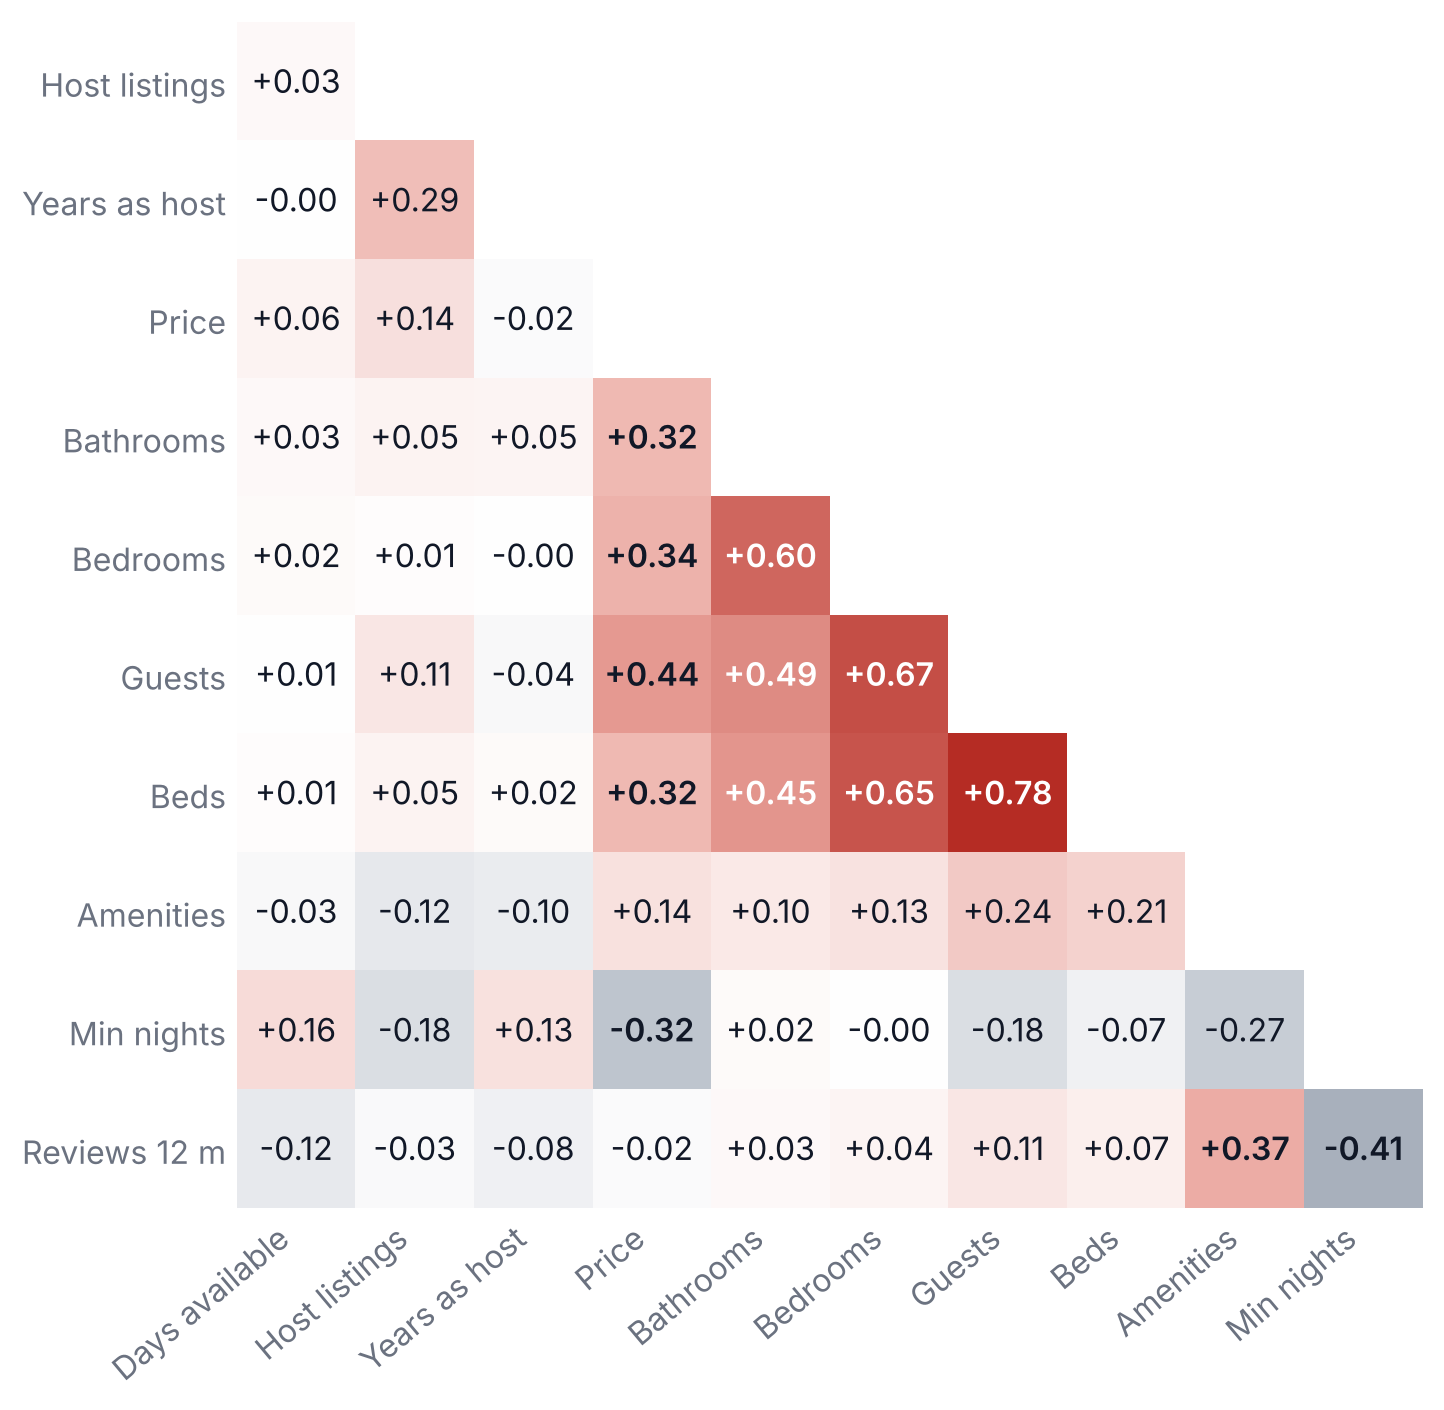

In [20]:
style('heat')
# ---- correlation and loadings heatmaps: neutral slate (negative) – white – accent red (positive), no type colours
import json
from scipy.cluster.hierarchy import linkage, leaves_list
DIV = LSC.from_list('div', ['#2F3A4D', '#AEB6C2', '#FFFFFF', '#EBA79F', RED])
meta = json.load(open(O + 'meta.json')); VARS = meta['VARS']; NPC = meta['NPC']
Z = pd.read_csv(O + 'blockA_z.csv')
SHORT = {'Price / night': 'Price', 'Minimum nights': 'Min nights', 'Days available / year': 'Days available', 'Reviews, last 12 m': 'Reviews 12 m'}
sh = lambda v: SHORT.get(v, v)
R = Z[VARS].corr(); n = len(VARS)
o = leaves_list(linkage(1 - R.abs().values[np.triu_indices(n, 1)], 'average')); R = R.iloc[o, o]
Rl = R.values.copy(); Rl[np.triu_indices(n, 0)] = np.nan
fig, ax = plt.subplots(figsize=(8.2, 7.0))
ax.imshow(Rl, cmap=DIV, vmin=-0.8, vmax=0.8)
for i in range(n):
    for j in range(i):
        v = R.values[i, j]; ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=10.5, color='white' if abs(v) > 0.45 else INK, fontweight='semibold' if abs(v) >= 0.3 else 'normal')
ax.set_xticks(range(n - 1)); ax.set_xticklabels([sh(c) for c in R.columns[:n - 1]], rotation=40, ha='right', fontsize=10.5)
ax.set_yticks(range(1, n)); ax.set_yticklabels([sh(c) for c in R.index[1:]], fontsize=10.5); ax.set_ylim(n - 0.5, 0.5); ax.set_xlim(-0.5, n - 1.5)
ax.tick_params(length=0); [s_.set_visible(False) for s_ in ax.spines.values()]
save(fig, 'e_corr')

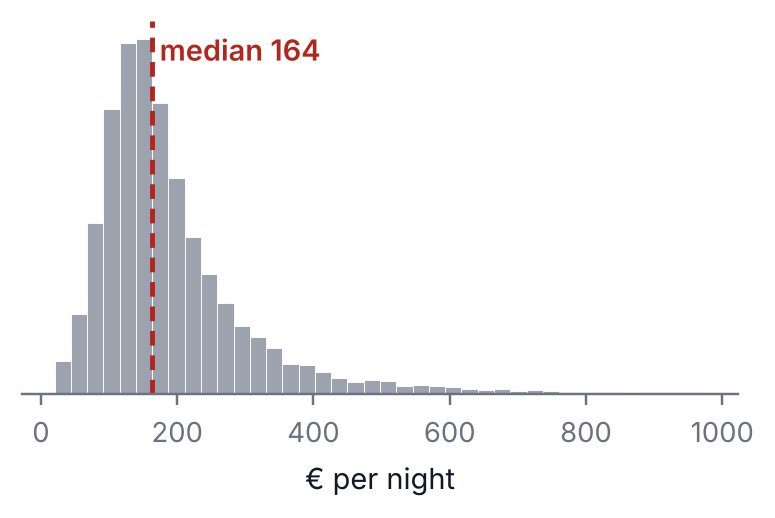

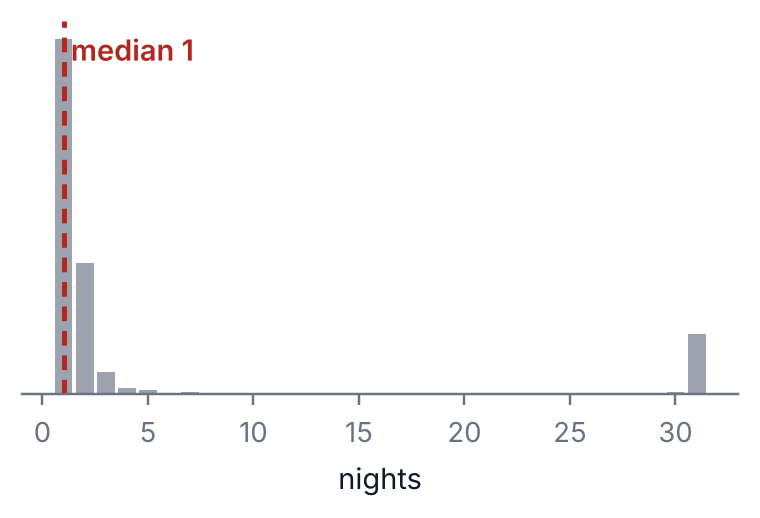

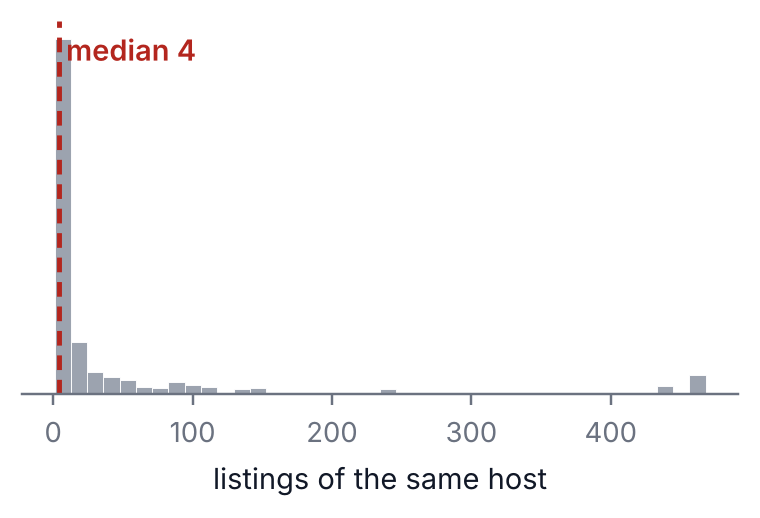

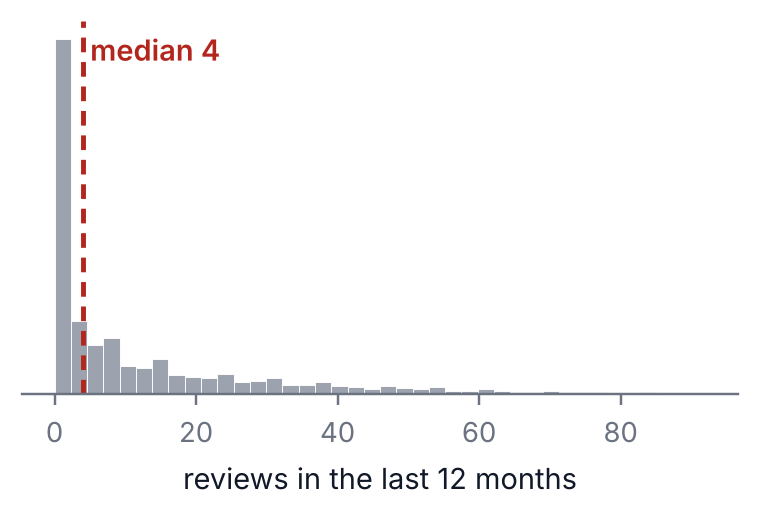

In [21]:
style('clustering')
meta = json.load(open(O + 'meta.json')); B = pd.read_csv(O + 'heldout.csv'); Xr = pd.read_csv(O + 'blockA_raw.csv')
# ---- 1. one clean histogram per skewed measure
for key, col, xl, cut in [('price', 'Price / night', '€ per night', 0.99), ('minn', 'Minimum nights', 'nights', 0.99),
                          ('host', 'Host listings', 'listings of the same host', 0.99), ('rev', 'Reviews, last 12 m', 'reviews in the last 12 months', 0.99)]:
    x = Xr[col]; hi = x.quantile(cut); xs = x[x <= hi]
    fig, a = plt.subplots(figsize=(4.2, 2.2))
    if key == 'minn': cts = xs.value_counts().sort_index(); a.bar(cts.index, cts.values, color='#9CA3AF', width=0.85)
    else: a.hist(xs, bins=40, color='#9CA3AF', edgecolor='white', lw=0.3)
    m = x.median(); a.axvline(m, color=RED, lw=1.6, ls=(0, (3, 2)))
    a.text(m, a.get_ylim()[1] * 0.97, f' median {m:.0f}', color=RED, fontsize=9.5, va='top', fontweight='semibold')
    a.set_yticks([]); a.spines['left'].set_visible(False); a.set_xlabel(xl, fontsize=9.5); a.tick_params(labelsize=9)
    save(fig, 'h_' + key)

## Slide 6 · PCA loadings

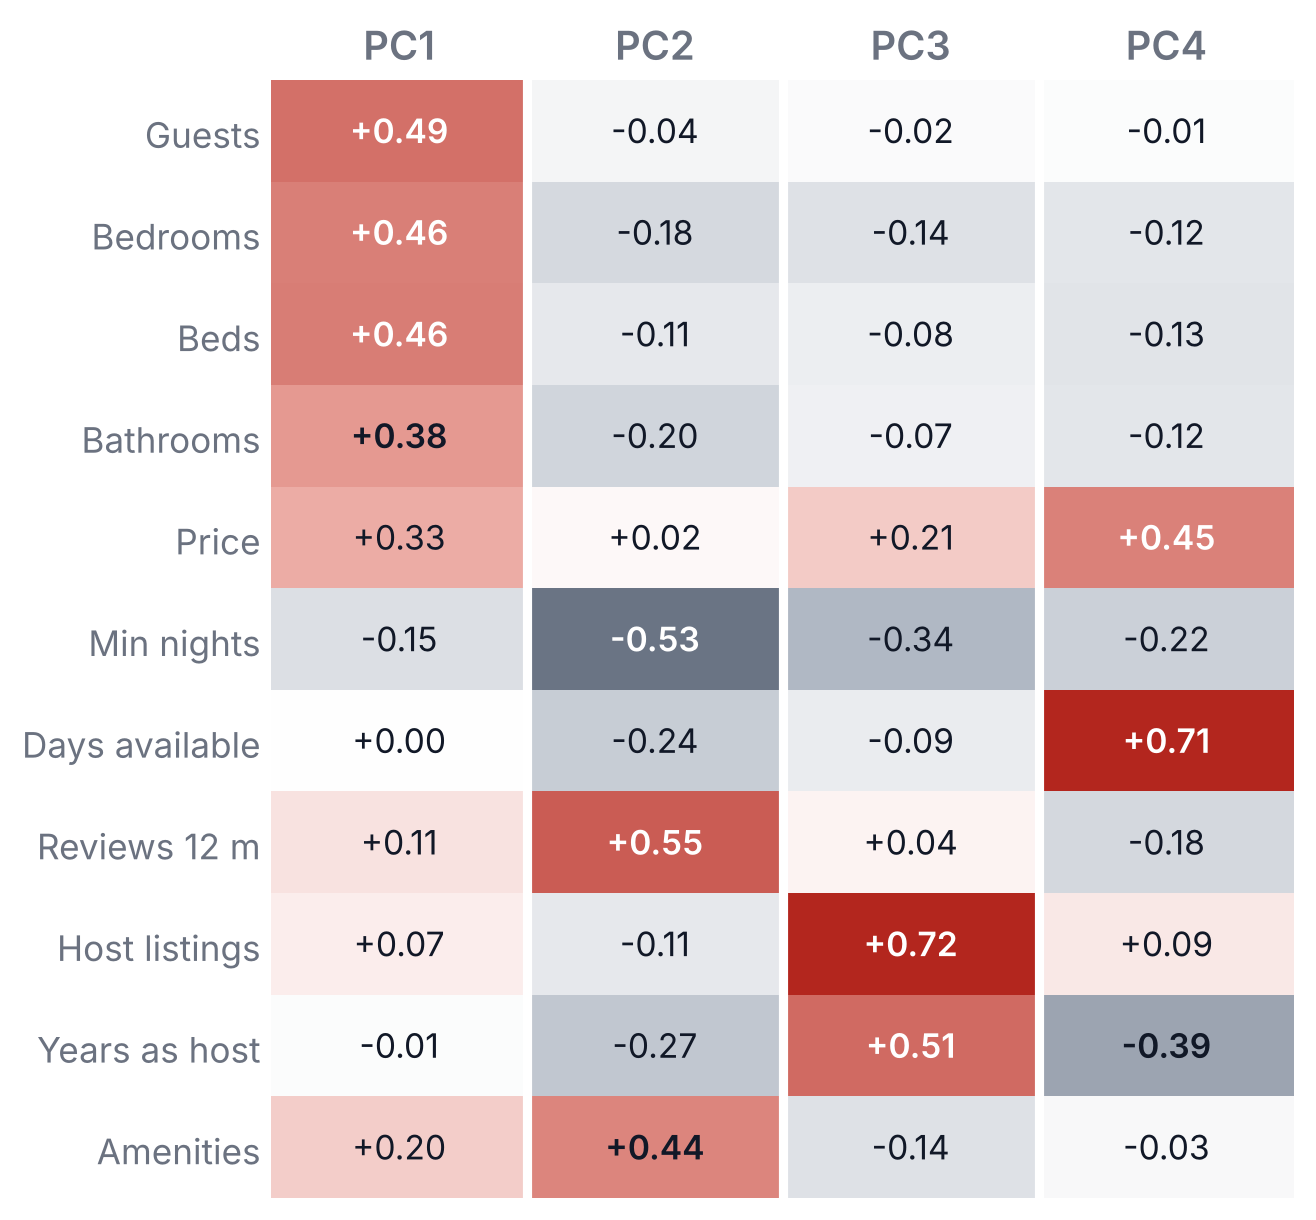

In [22]:
style('heat')
meta = json.load(open(O + 'meta.json')); VARS = meta['VARS']; NPC = meta['NPC']
Z = pd.read_csv(O + 'blockA_z.csv')
n = len(VARS); SHORT = {'Price / night': 'Price', 'Minimum nights': 'Min nights', 'Days available / year': 'Days available', 'Reviews, last 12 m': 'Reviews 12 m'}
sh = lambda v: SHORT.get(v, v)
DIV = LSC.from_list('div', ['#2F3A4D', '#AEB6C2', '#FFFFFF', '#EBA79F', RED])
L = pd.read_csv(O + 'loadings.csv', index_col=0)
fig, ax = plt.subplots(figsize=(6.0, 6.6))
ax.imshow(L.values, cmap=DIV, vmin=-0.7, vmax=0.7, aspect='auto')
for i in range(n):
    for j in range(NPC): v = L.values[i, j]; ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=11, color='white' if abs(v) > 0.45 else INK, fontweight='semibold' if abs(v) >= 0.35 else 'normal')
ax.set_yticks(range(n)); ax.set_yticklabels([sh(v) for v in L.index], fontsize=11.5)
ax.set_xticks(range(NPC)); ax.set_xticklabels([f'PC{i+1}' for i in range(NPC)], fontsize=13, fontweight='semibold'); ax.xaxis.tick_top()
ax.tick_params(length=0); [s_.set_visible(False) for s_ in ax.spines.values()]
for xx in np.arange(0.5, NPC - 1, 1): ax.axvline(xx, color='white', lw=3)
save(fig, 'd_loadings')

## Slide 8 · Hierarchical clustering: Ward's tree and the four linkage rules

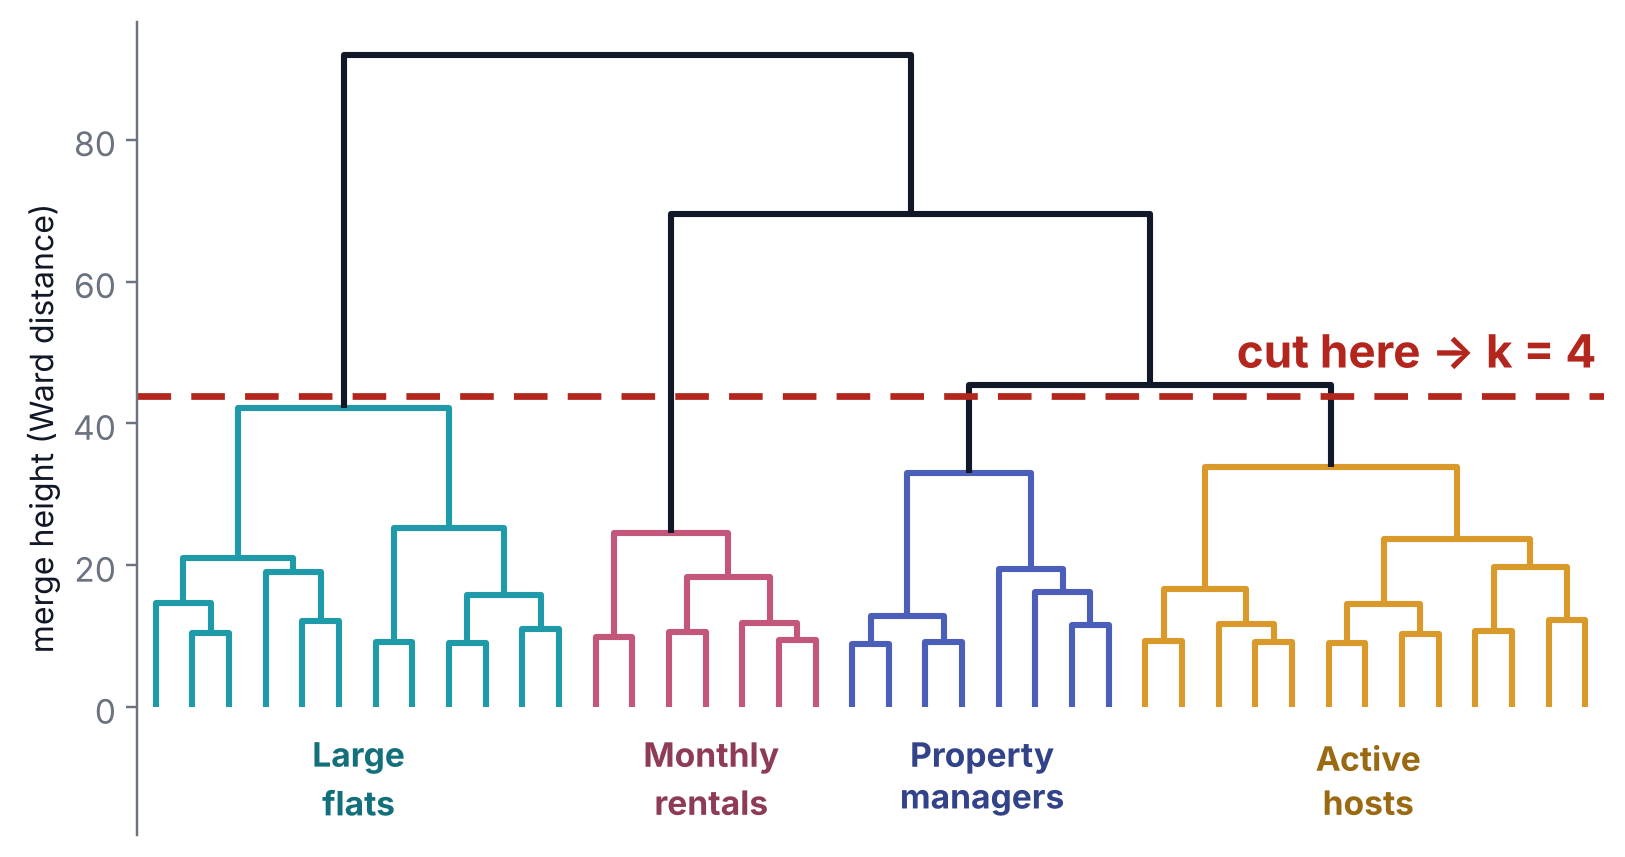

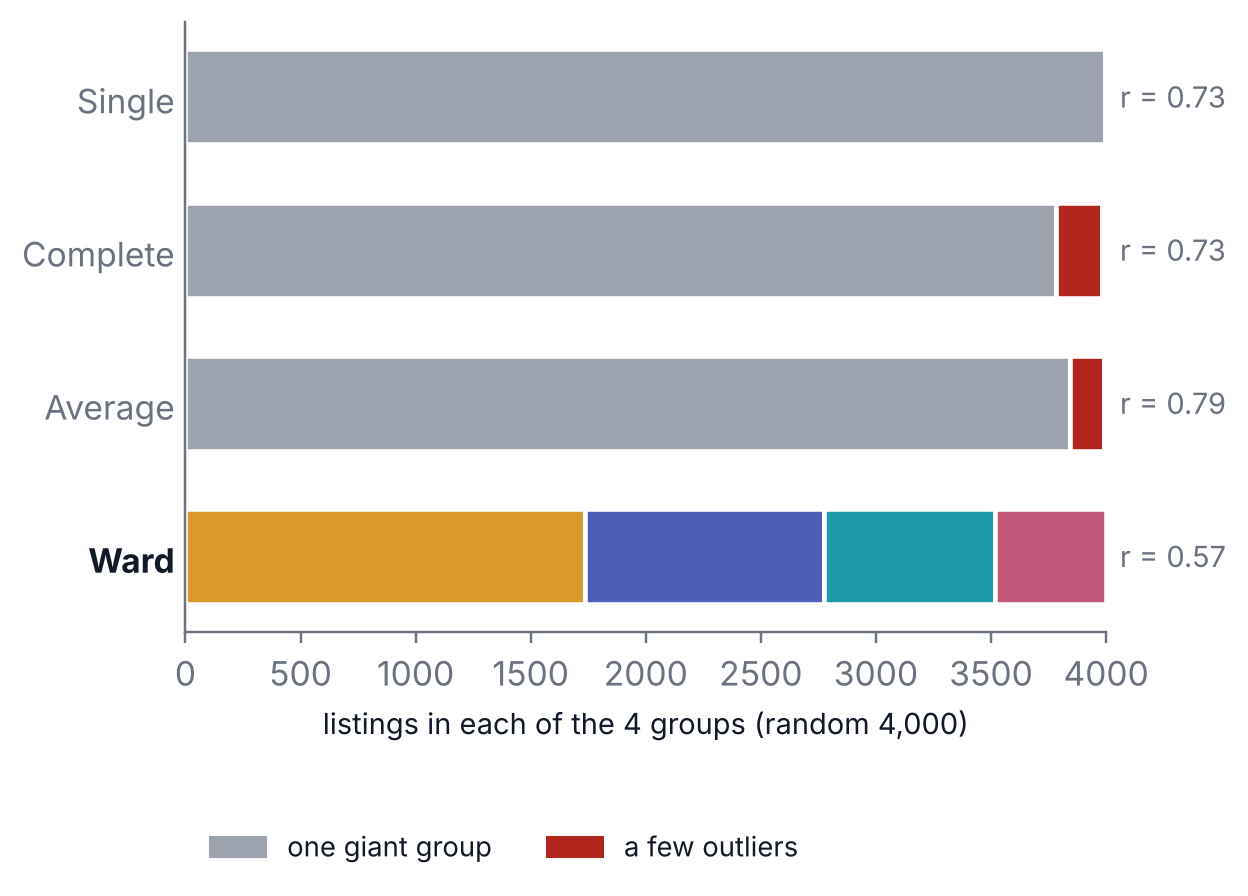

In [23]:
style('clustering')
meta = json.load(open(O + 'meta.json')); B = pd.read_csv(O + 'heldout.csv')
Z = pd.read_csv(O + 'blockA_z.csv').drop(columns='id').values
PCs = PCA(random_state=SEED).fit(Z).transform(Z)[:, :meta['NPC']]
rs = np.random.RandomState(SEED); sub = rs.choice(len(PCs), 4000, replace=False)
km = B.cluster.values
Lw = linkage(PCs[sub[:2000]], method='ward'); lab2 = fcluster(Lw, 4, 'maxclust')
map2 = {c: pd.Series(km[sub[:2000]][lab2 == c]).mode()[0] for c in np.unique(lab2)}
leaf_type = {i: map2[lab2[i]] for i in range(len(lab2))}
thr = (Lw[-4, 2] + Lw[-3, 2]) / 2; n = len(lab2)
# colour each link by the type of its cluster when below the cut
clus_of = {}
def members(node):
    return [node] if node < n else members(int(Lw[node - n, 0])) + members(int(Lw[node - n, 1]))
def link_color(k):
    if Lw[k - n, 2] > thr: return INK
    t = leaf_type[members(k)[0]]; return COL[t]
fig, a = plt.subplots(figsize=(8.6, 4.8))
d = dendrogram(Lw, ax=a, truncate_mode='lastp', p=40, link_color_func=link_color, no_labels=True)
for ln in a.collections: ln.set_linewidth(2.0)
a.axhline(thr, color=RED, lw=2.2, ls=(0, (5, 3)))
a.text(a.get_xlim()[1] * 0.995, thr + 2.5, 'cut here → k = 4', ha='right', va='bottom', fontsize=15, fontweight='bold', color=RED)
# type names under each branch
xs_leaf = np.array(d['icoord'])[:, [0, 3]]; cols = d['color_list']
for t in range(4):
    xx = [np.mean(ic) for ic, c, dc in zip(d['icoord'], d['color_list'], d['dcoord']) if c == COL[t]]
    if xx: a.text(np.mean(xx), -4, NAMES[t].replace(' ', chr(10)), ha='center', va='top', fontsize=11, fontweight='bold', color=DARK[t], linespacing=1.1)
a.set_ylim(-18, a.get_ylim()[1]); a.spines['bottom'].set_visible(False); a.set_xticks([])
a.set_ylabel('merge height (Ward distance)', fontsize=10.5); a.set_yticks([0, 20, 40, 60, 80])
save(fig, 'h_dendro_col')

# ---- 3. group sizes by linkage method (4,000 listings), Ward segments coloured by matching type
from sklearn.cluster import AgglomerativeClustering
fig, b = plt.subplots(figsize=(5.4, 3.6))
for i, h in enumerate(meta['hier']):
    lab = AgglomerativeClustering(4, linkage=h['method']).fit_predict(PCs[sub])
    sizes = pd.Series(lab).value_counts()
    left = 0
    for c, sz in sizes.items():
        if h['method'] == 'ward':
            t = pd.Series(km[sub][lab == c]).mode()[0]; colr = COL[t]
        else: colr = '#9CA3AF' if sz > 1000 else RED
        b.barh(i, sz, left=left, color=colr, edgecolor='white', lw=1.5, height=0.62); left += sz
    b.text(4060, i, f"r = {h['cophenetic']:.2f}", va='center', fontsize=9.5, color=MUTED)
b.set_yticks(range(4)); b.set_yticklabels([h['method'].capitalize() for h in meta['hier']], fontsize=11); b.invert_yaxis()
for tl in b.get_yticklabels():
    if tl.get_text() == 'Ward': tl.set_fontweight('bold'); tl.set_color(INK)
b.set_xlim(0, 4000); b.set_xlabel('listings in each of the 4 groups (random 4,000)', fontsize=9.5); b.tick_params(axis='y', length=0)
b.legend(handles=[Patch(color='#9CA3AF', label='one giant group'), Patch(color=RED, label='a few outliers')], loc='lower left', bbox_to_anchor=(0, -0.42), ncol=2, frameon=False, fontsize=9)
save(fig, 'h_linkage_col')

## Slide 9 · K-means: silhouette against shuffled data

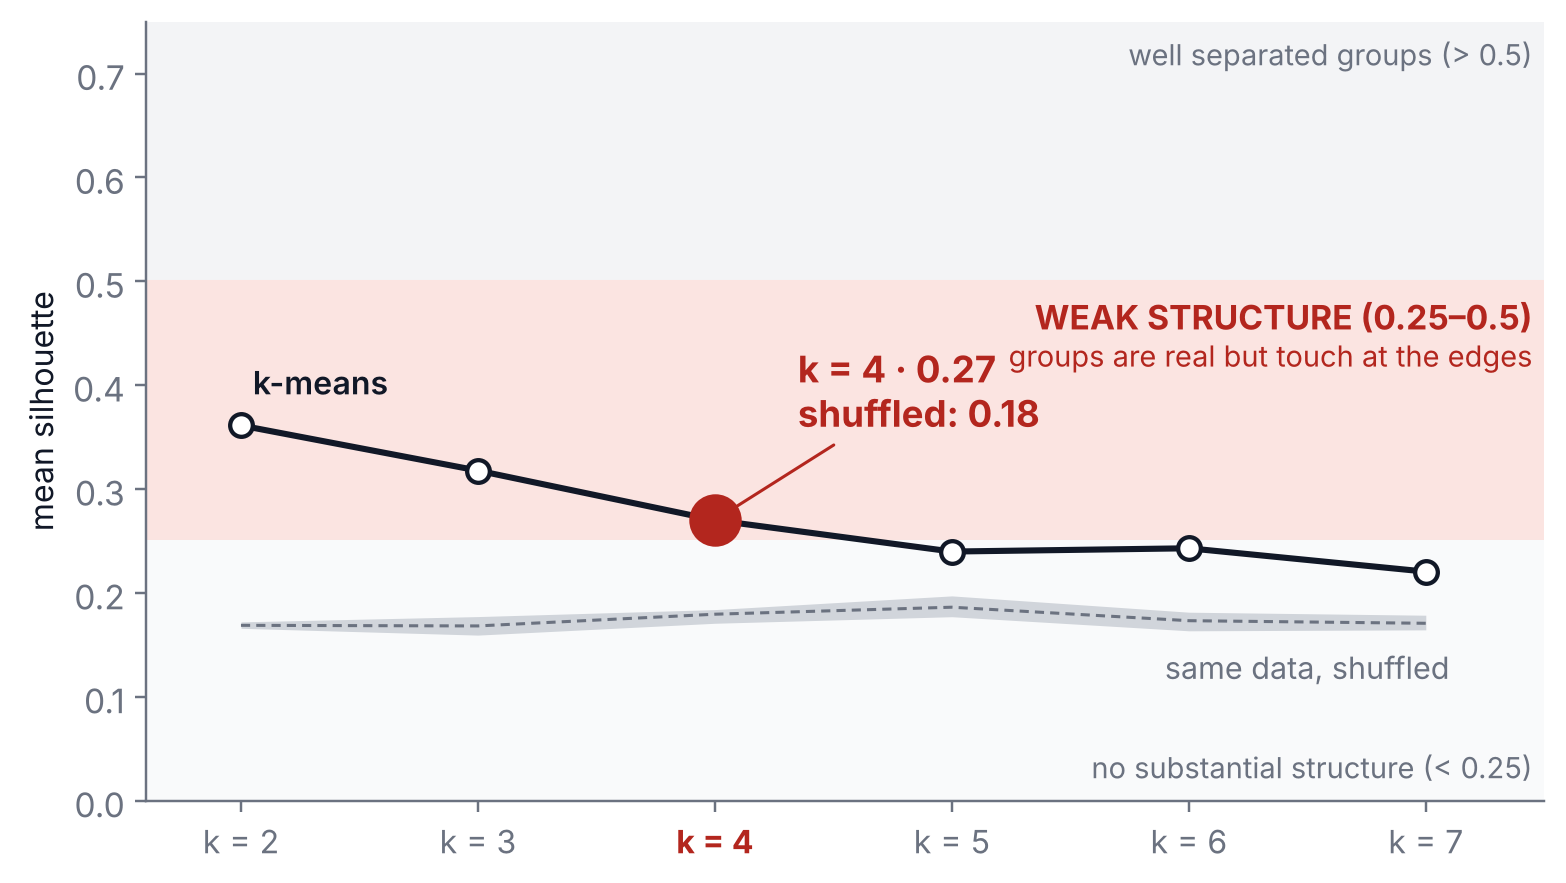

In [24]:
style('clustering')
ks = pd.read_csv(O + 'k_selection.csv'); x = ks.k.values; y = ks.sil_km.values
fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.axhspan(0.5, 0.75, color='#F3F4F6', zorder=0); ax.text(7.45, 0.735, 'well separated groups (> 0.5)', ha='right', va='top', fontsize=9.5, color=MUTED)
ax.axhspan(0.25, 0.5, color='#FBE4E1', zorder=0)
ax.text(7.45, 0.485, 'WEAK STRUCTURE (0.25–0.5)', ha='right', va='top', fontsize=11, color='#B3261E', fontweight='bold')
ax.text(7.45, 0.445, 'groups are real but touch at the edges', ha='right', va='top', fontsize=9.5, color='#B3261E')
ax.axhspan(0, 0.25, color='#F9FAFB', zorder=0); ax.text(7.45, 0.015, 'no substantial structure (< 0.25)', ha='right', va='bottom', fontsize=9.5, color=MUTED)
ax.fill_between(x, ks.null_lo, ks.null_hi, color='#D1D5DB', lw=0, zorder=1); ax.plot(x, ks.null_mean, color=MUTED, lw=1, ls=(0, (3, 2)), zorder=1)
ax.text(7.1, ks.null_mean.iloc[-1] - 0.025, 'same data, shuffled', fontsize=10, color=MUTED, ha='right', va='top')
ax.plot(x, y, color=INK, lw=2, zorder=3)
for xi, yi in zip(x, y):
    on = xi == 4
    ax.scatter(xi, yi, s=230 if on else 55, color=RED if on else 'white', edgecolor=RED if on else INK, lw=2 if on else 1.4, zorder=4)
ax.annotate('k = 4 · 0.27\nshuffled: 0.18', (4, y[2]), xytext=(4.35, 0.36), fontsize=12, fontweight='bold', color=RED, arrowprops=dict(arrowstyle='-', color=RED, lw=1))
ax.text(2.05, y[0] + 0.03, 'k-means', fontsize=10.5, color=INK, fontweight='semibold')
ax.set_xticks(x); ax.set_xticklabels([f'k = {k}' for k in x], fontsize=10.5); ax.get_xticklabels()[2].set_fontweight('bold'); ax.get_xticklabels()[2].set_color(RED)
ax.set_xlim(1.6, 7.5); ax.set_ylim(0, 0.75); ax.set_ylabel('mean silhouette', fontsize=10.5)
save(fig, 'k_sil_band')

## Slide 10 · Bootstrap: stability of both methods

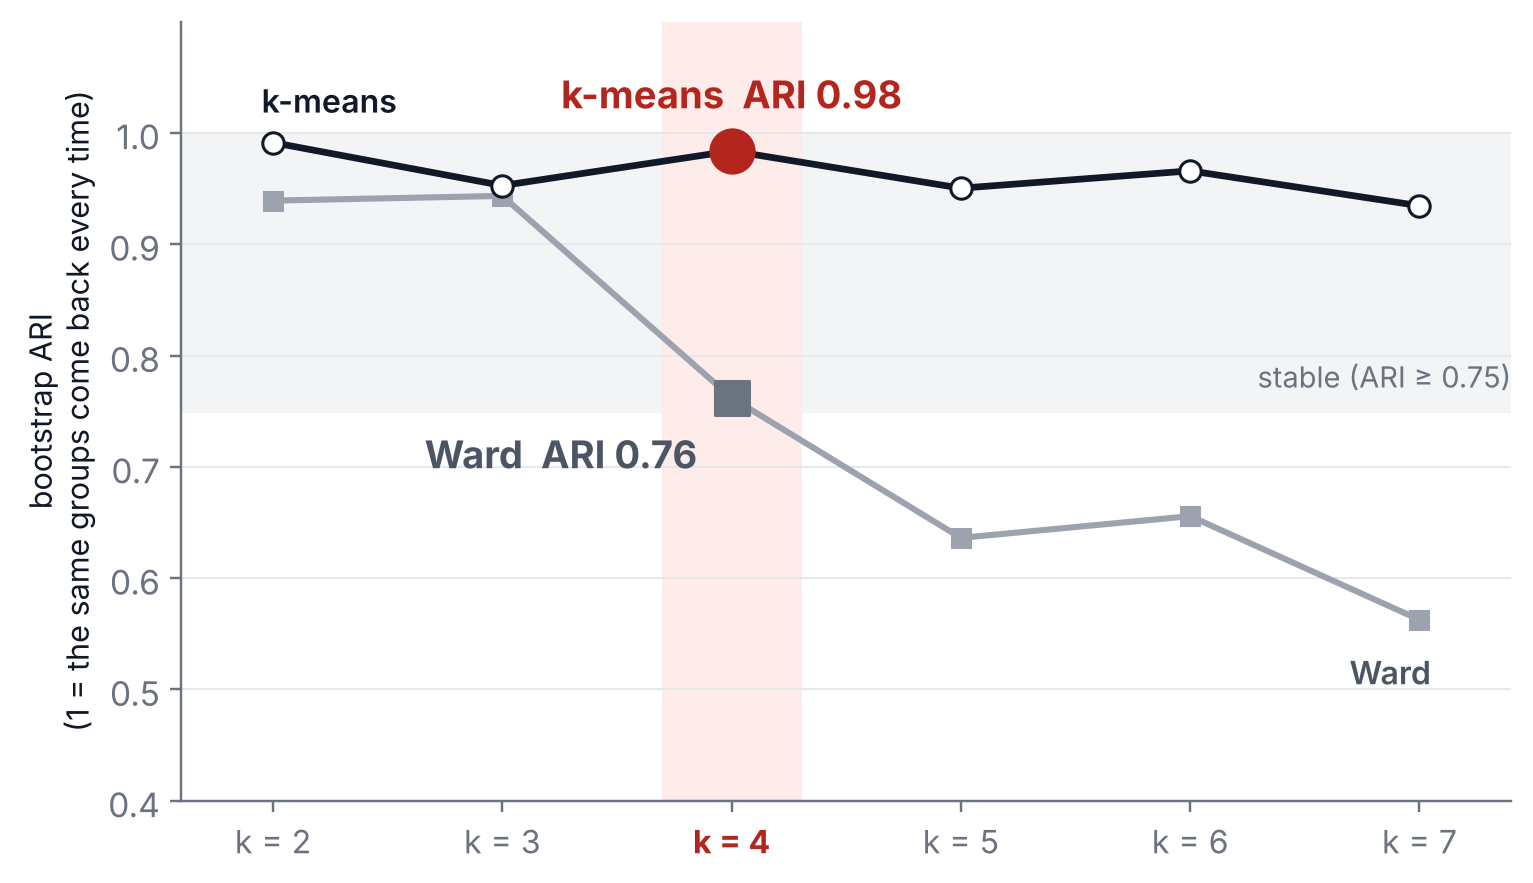

ward-kmeans ARI at k=4 0.866 meta 0.865


In [25]:
style('clustering')
meta = json.load(open(O + 'meta.json'))
ks = pd.read_csv(O + 'k_selection.csv'); x = ks.k.values
fig, ax = plt.subplots(figsize=(7.8, 4.6))
ax.axhspan(0.75, 1.0, color='#F3F4F6', zorder=0); ax.text(7.4, 0.765, 'stable (ARI ≥ 0.75)', ha='right', va='bottom', fontsize=9.5, color=MUTED)
ax.axvspan(3.7, 4.3, color='#FDECEA', zorder=0)
ax.plot(x, ks.boot_ward, color='#9CA3AF', lw=2, marker='s', ms=6, zorder=2)
ax.plot(x, ks.boot_km, color=INK, lw=2.2, marker='o', ms=7, mfc='white', zorder=3)
k4 = ks.set_index('k').loc[4]
ax.scatter([4], [k4.boot_km], s=200, color=RED, zorder=4); ax.scatter([4], [k4.boot_ward], s=120, color='#6B7280', marker='s', zorder=4)
ax.text(4, k4.boot_km + 0.03, f'k-means  ARI {k4.boot_km:.2f}', fontsize=12.5, fontweight='bold', color=RED, va='bottom', ha='center')
ax.text(3.85, k4.boot_ward - 0.03, f'Ward  ARI {k4.boot_ward:.2f}', fontsize=12.5, fontweight='bold', color='#4B5563', va='top', ha='right')
ax.text(1.95, ks.boot_km.iloc[0] + 0.02, 'k-means', fontsize=10.5, fontweight='semibold', va='bottom')
ax.text(7.05, ks.boot_ward.iloc[-1] - 0.03, 'Ward', fontsize=10.5, fontweight='semibold', color='#4B5563', va='top', ha='right')
ax.set_xticks(x); ax.set_xticklabels([f'k = {k}' for k in x], fontsize=10.5); ax.get_xticklabels()[2].set_fontweight('bold'); ax.get_xticklabels()[2].set_color(RED)
ax.set_ylim(0.4, 1.1); ax.set_xlim(1.6, 7.4); ax.set_yticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_ylabel('bootstrap ARI\n(1 = the same groups come back every time)', fontsize=10)
ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
save(fig, 'k_boot_ari')
print('ward-kmeans ARI at k=4', round(k4.ari_ward_km, 3), 'meta', round(meta['ari_ward_final'], 3))

## Slide 11 · The four types on the PCA map

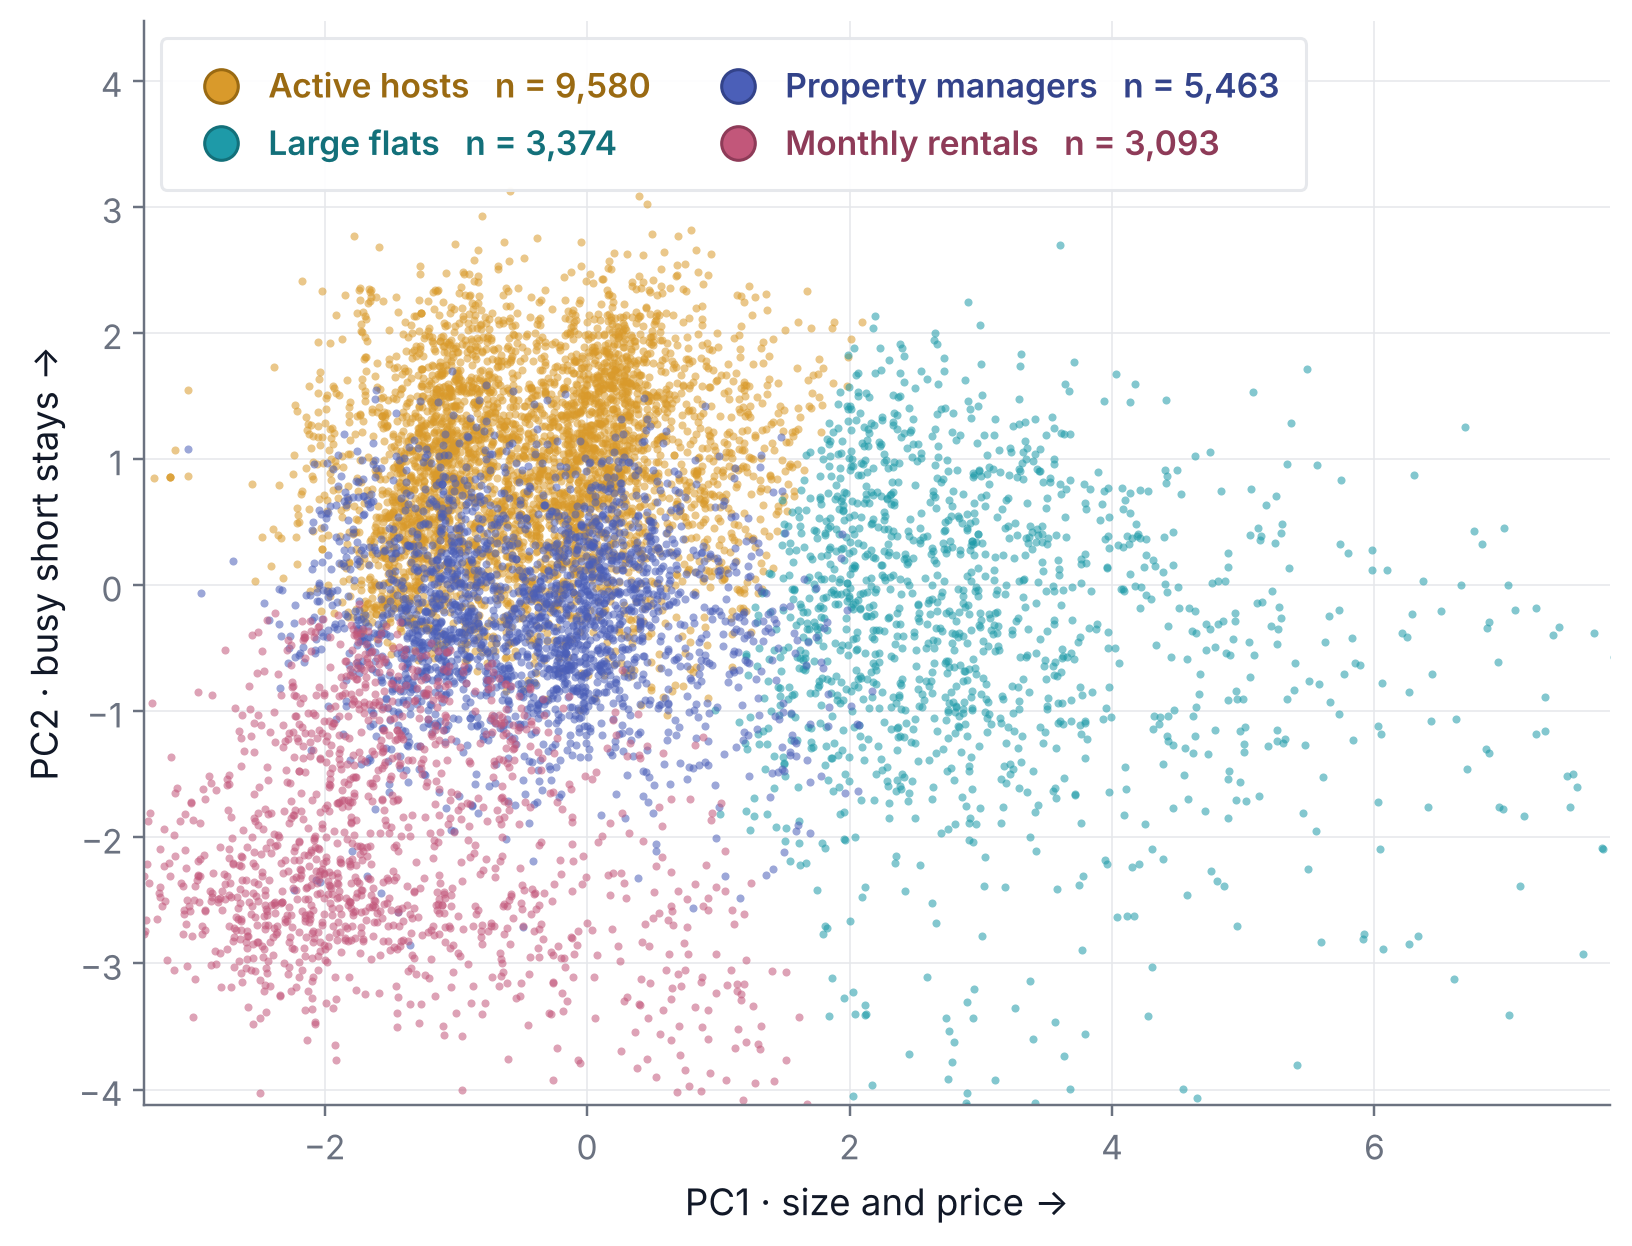

In [26]:
style('modern')
meta = json.load(open(O + 'meta.json')); K = meta['K']; B = pd.read_csv(O + 'heldout.csv')
df = B.copy()
fig, a2 = plt.subplots(figsize=(8.6, 6.4)); smp1 = df.sample(9000, random_state=1)
for kk in range(K):
    s_ = smp1[smp1.cluster == kk]; a2.scatter(s_.PC1, s_.PC2, s=7, color=COL[kk], alpha=0.55, lw=0, rasterized=True)
hs = [Line2D([0], [0], marker='o', ls='', ms=11, mfc=COL[kk], mec=DARK[kk], label=f'{NAMES[kk]}   n = {meta["sizes"][kk]:,}') for kk in range(K)]
leg = a2.legend(handles=hs, loc='upper left', ncol=2, frameon=True, fontsize=11, borderpad=0.8, handletextpad=0.4, columnspacing=1.6)
leg.get_frame().set_facecolor('white'); leg.get_frame().set_edgecolor(GRID); leg.get_frame().set_alpha(0.95)
for t_, c in zip(leg.get_texts(), DARK): t_.set_color(c); t_.set_fontweight('semibold')
lo1, hi1 = np.percentile(df.PC1, [0.5, 99.5]); lo2, hi2 = np.percentile(df.PC2, [0.5, 99.5])
a2.set_xlim(lo1 - 0.3, hi1 + 0.3); a2.set_ylim(lo2 - 0.3, hi2 + (hi2 - lo2) * 0.32)
a2.set_xlabel('PC1 · size and price →', fontsize=12); a2.set_ylabel('PC2 · busy short stays →', fontsize=12); a2.grid(color=GRID, lw=0.5); a2.set_axisbelow(True)
save(fig, 'd_map1')

## Slide 13 · Price per night by type (notched boxplots)

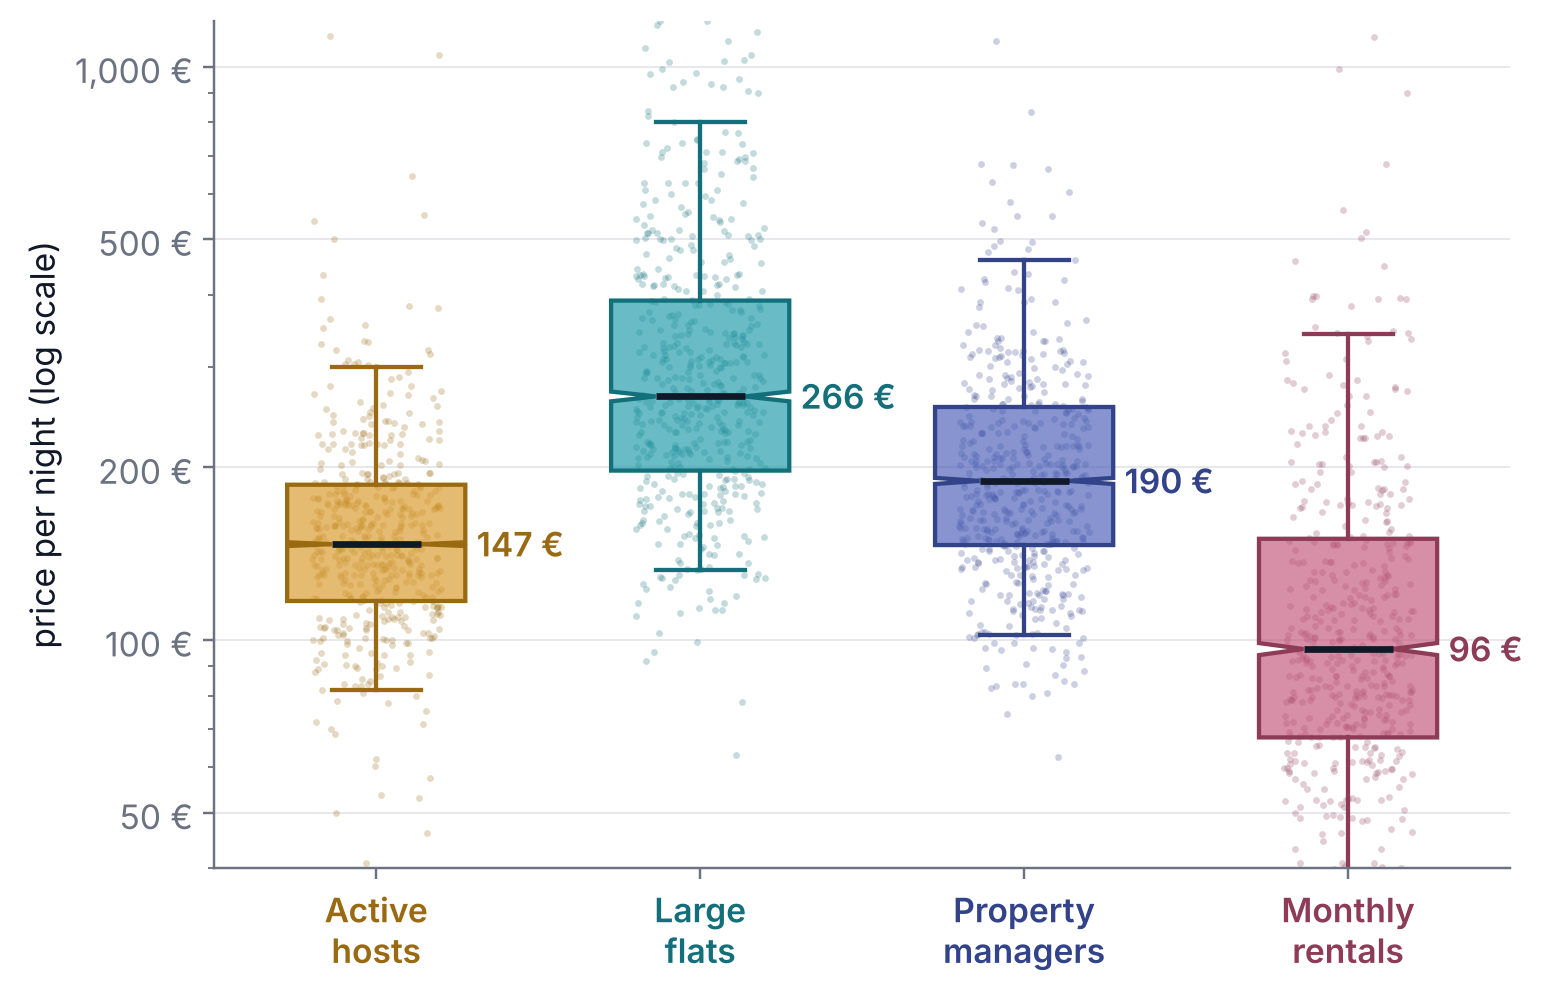

In [27]:
style('modern')
K = 4; Xr = pd.read_csv(O + 'blockA_raw.csv'); B = pd.read_csv(O + 'heldout.csv')
rsj = np.random.RandomState(3); Xp = Xr.merge(B[['id', 'cluster']], on='id')
fig, ax = plt.subplots(figsize=(7.6, 5.0))
for kk in range(K):
    d_ = Xp.loc[Xp.cluster == kk, 'Price / night'].values; pts = rsj.choice(d_, 500, replace=False)
    ax.scatter(kk + rsj.uniform(-0.2, 0.2, len(pts)), pts, s=5, color=DARK[kk], alpha=0.25, lw=0, zorder=1)
    ax.boxplot(d_, positions=[kk], widths=0.55, notch=True, patch_artist=True, showfliers=False, whis=(5, 95),
               medianprops=dict(color=INK, lw=2.2), whiskerprops=dict(color=DARK[kk], lw=1.4), capprops=dict(color=DARK[kk], lw=1.4),
               boxprops=dict(facecolor=COL[kk] + 'AA', edgecolor=DARK[kk], lw=1.4))
    ax.text(kk + 0.31, np.median(d_), f'{np.median(d_):.0f} €', va='center', fontsize=11, fontweight='semibold', color=DARK[kk])
ax.set_yscale('log'); ax.set_yticks([50, 100, 200, 500, 1000]); ax.set_yticklabels(['50 €', '100 €', '200 €', '500 €', '1,000 €'])
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter()); ax.set_ylim(40, 1200)
ax.set_xticks(range(K)); ax.set_xticklabels([n.replace(' ', '\n') for n in NAMES], fontsize=11)
for tl, c in zip(ax.get_xticklabels(), DARK): tl.set_color(c); tl.set_fontweight('semibold')
ax.set_ylabel('price per night (log scale)', fontsize=11); ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True)
save(fig, 'b_price')

## Slide 15 · Test 1 — Superhost badge

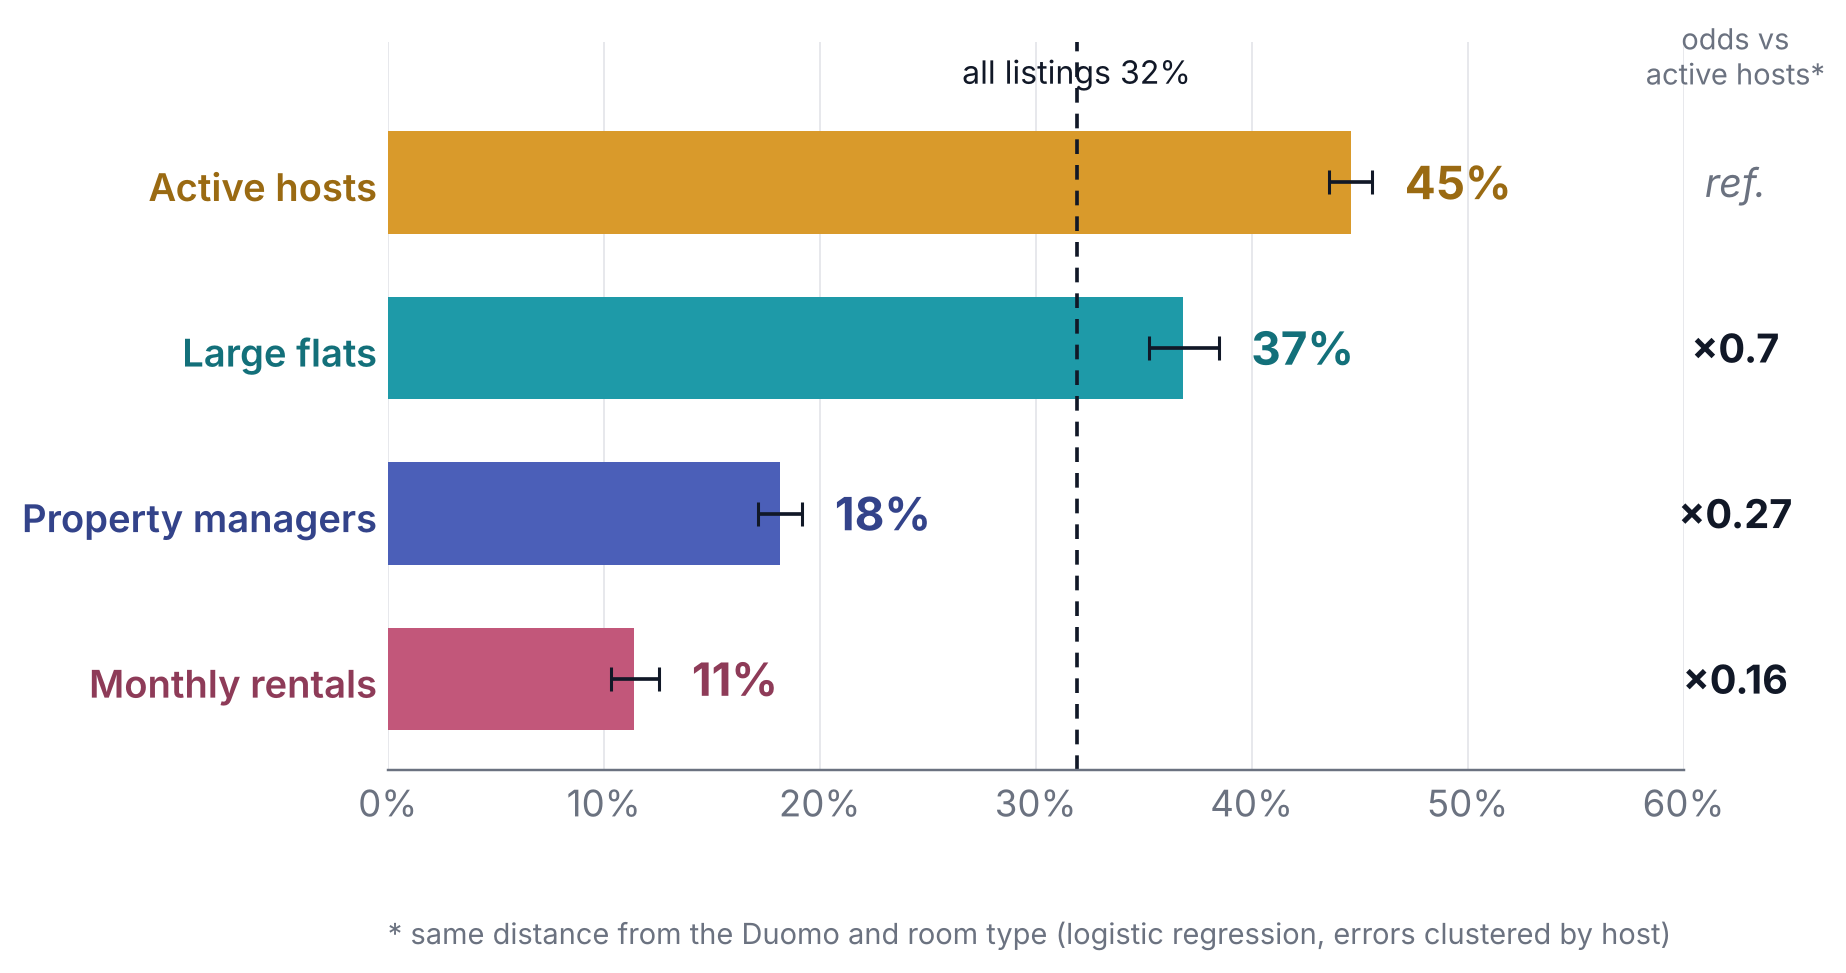

In [28]:
style('tests')
B = pd.read_csv(O + 'heldout.csv'); PR = pd.read_csv(O + 'proportions.csv'); OR = pd.read_csv(O + 'adjusted_or.csv')

def bars(var, fname, xmax=100, odds=True, note=None):
    d = PR[PR['var'] == var].set_index('cluster'); allp = B[var].mean() * 100
    fig, ax = plt.subplots(figsize=(7.6, 4.3)); y = np.arange(4)[::-1]
    ax.barh(y, d.p * 100, color=COL, height=0.62)
    ax.errorbar(d.p * 100, y, xerr=[(d.p - d.lo) * 100, (d.hi - d.p) * 100], fmt='none', ecolor=INK, elinewidth=1.2, capsize=4)
    for k in range(4):
        ax.text(d.hi[k] * 100 + 1.5, y[k], f'{d.p[k] * 100:.0f}%', va='center', fontsize=15, fontweight='bold', color=DARK[k])
    ax.axvline(allp, color=INK, lw=1.2, ls=(0, (4, 3)))
    ax.text(allp, 3.55, f'all listings {allp:.0f}%', ha='center', va='bottom', fontsize=10.5, color=INK)
    ax.set_yticks(y); ax.set_yticklabels(NAMES, fontsize=12.5)
    for t, c in zip(ax.get_yticklabels(), DARK): t.set_color(c); t.set_fontweight('semibold')
    ax.set_xlim(0, xmax); ax.set_ylim(-0.55, 3.85); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    ax.tick_params(length=0); ax.spines['left'].set_visible(False); ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
    if odds:
        o = OR[OR.outcome == var].set_index('cluster')
        ax.text(1.04, 3.55, 'odds vs\nactive hosts*', transform=ax.get_yaxis_transform(), ha='center', va='bottom', fontsize=9.5, color=MUTED)
        for k in range(4):
            lab = 'ref.' if k == 0 else f'×{o.OR[k]:.2f}'.rstrip('0').rstrip('.')
            ns = k > 0 and o.p[k] >= 0.05
            ax.text(1.04, y[k], lab, transform=ax.get_yaxis_transform(), ha='center', va='center', fontsize=13,
                    fontweight='bold' if k else 'normal', color=MUTED if (k == 0 or ns) else INK, style='italic' if k == 0 else 'normal')
    if note: ax.text(0, -0.2, note, transform=ax.transAxes, fontsize=9.5, color=MUTED, va='top')
    save(fig, fname)

nt = '* same distance from the Duomo and room type (logistic regression, errors clustered by host)'
bars('Superhost', 't_super', xmax=60, note=nt)

## Slide 16 · Test 2 — CIN licence code

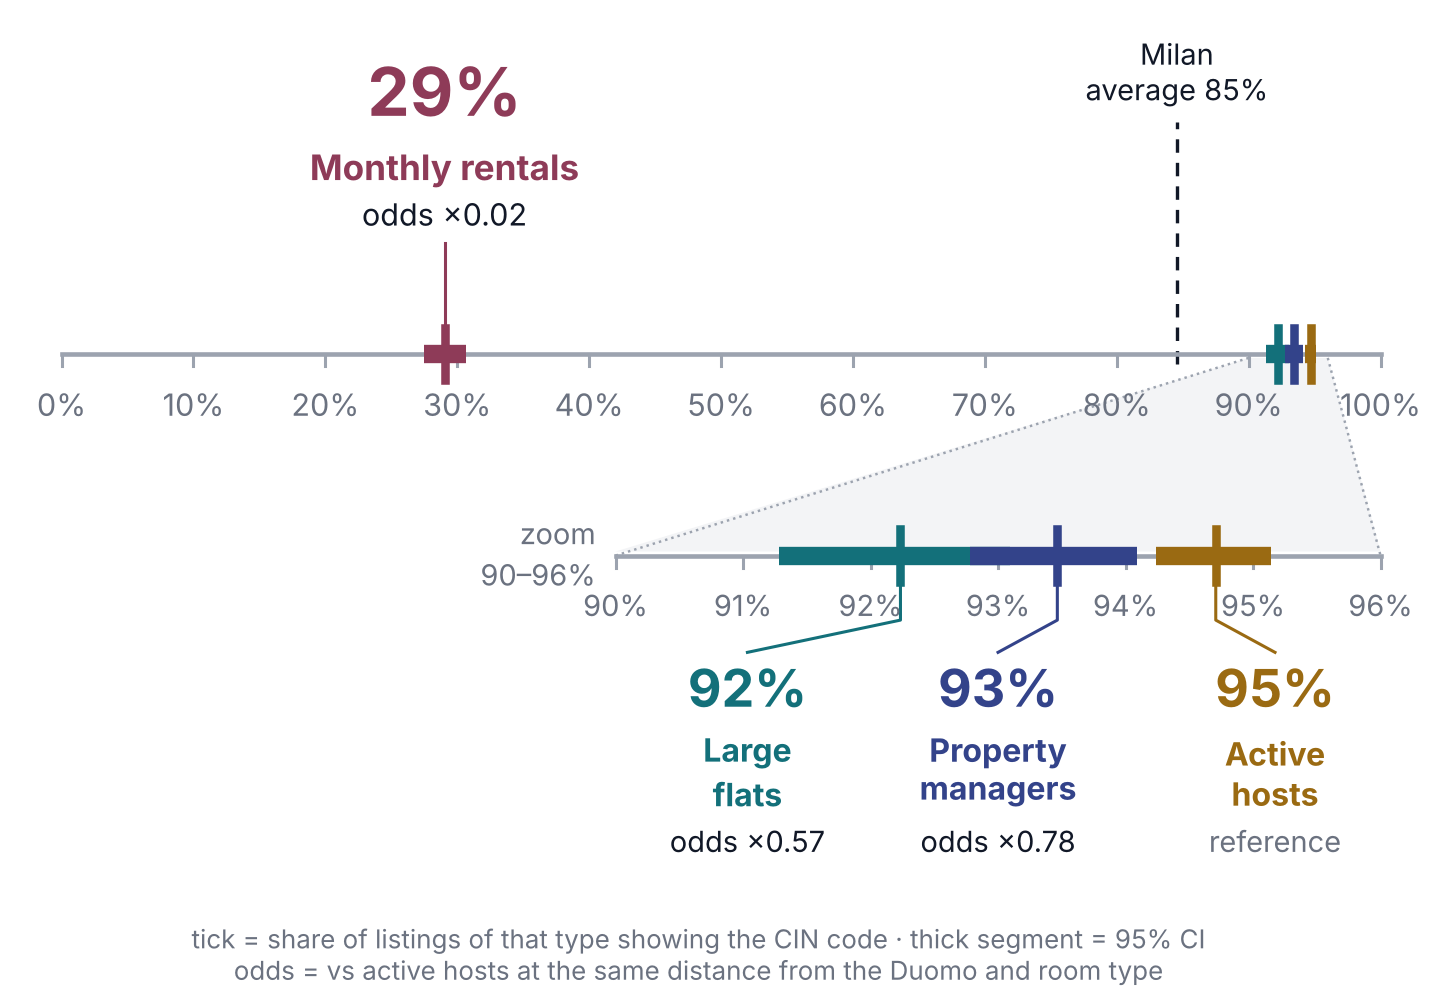

In [29]:
style('scale')
NAMES = ['Active hosts', 'Large flats', 'Property\nmanagers', 'Monthly rentals']
ZN = ['Active\nhosts', 'Large\nflats', 'Property\nmanagers', '']; LX = {1: 52, 2: 71, 0: 92}
PR = pd.read_csv(O + 'proportions.csv'); OR = pd.read_csv(O + 'adjusted_or.csv'); B = pd.read_csv(O + 'heldout.csv')
d = PR[PR['var'] == 'CIN licence shown'].set_index('cluster'); o = OR[OR.outcome == 'CIN licence shown'].set_index('cluster')
allp = B['CIN licence shown'].mean() * 100
odds = ['reference'] + [f'odds ×{o.OR[k]:.2f}'.rstrip('0').rstrip('.') for k in (1, 2, 3)]
fig, ax = plt.subplots(figsize=(8.2, 5.0))
AX = '#9CA3AF'
# ---- main scale 0-100
ax.plot([0, 100], [0, 0], color=AX, lw=1.5, zorder=1)
for t in range(0, 101, 10):
    ax.plot([t, t], [-0.06, 0], color=AX, lw=1); ax.text(t, -0.16, f'{t}%', ha='center', va='top', fontsize=10, color=MUTED)
ax.plot([allp, allp], [-0.05, 1.15], color=INK, lw=1.1, ls=(0, (4, 3)), zorder=0)
ax.text(allp, 1.2, f'Milan\naverage {allp:.0f}%', ha='center', va='bottom', fontsize=9.5, color=INK, linespacing=1.1)
def mark(k, x, lo, hi, y):
    ax.plot([lo, hi], [y, y], color=DARK[k], lw=6, solid_capstyle='butt', zorder=2)
    ax.plot([x, x], [y - 0.13, y + 0.13], color=DARK[k], lw=2.8, zorder=3)
for k in range(4): mark(k, d.p[k] * 100, d.lo[k] * 100, d.hi[k] * 100, 0)
# monthly rentals label above its tick
x3 = d.p[3] * 100
ax.plot([x3, x3], [0.13, 0.55], color=DARK[3], lw=1)
ax.text(x3, 1.1, f'{x3:.0f}%', ha='center', va='bottom', fontsize=22, fontweight='bold', color=DARK[3])
ax.text(x3, 0.82, NAMES[3], ha='center', va='bottom', fontsize=11.5, fontweight='bold', color=DARK[3])
ax.text(x3, 0.6, odds[3], ha='center', va='bottom', fontsize=10, color=INK)
# ---- zoom: 90-96% stretched over 45..100
Z0, Z1, X0, X1, YZ = 90, 96, 42, 100, -1.0
zx = lambda v: X0 + (v - Z0) / (Z1 - Z0) * (X1 - X0)
ax.fill([Z0, Z1, X1, X0], [-0.02, -0.02, YZ + 0.02, YZ + 0.02], color='#F3F4F6', zorder=0, lw=0)
ax.plot([Z0, X0], [-0.02, YZ], color=AX, lw=0.8, ls=':'); ax.plot([Z1, X1], [-0.02, YZ], color=AX, lw=0.8, ls=':')
ax.plot([X0, X1], [YZ, YZ], color=AX, lw=1.5)
for t in range(Z0, Z1 + 1):
    ax.plot([zx(t), zx(t)], [YZ - 0.06, YZ], color=AX, lw=1); ax.text(zx(t), YZ - 0.16, f'{t}%', ha='center', va='top', fontsize=9.5, color=MUTED)
ax.text(X0 - 1.5, YZ, 'zoom\n90–96%', ha='right', va='center', fontsize=9.5, color=MUTED, linespacing=1.1)
for k in (1, 2, 0):
    x = d.p[k] * 100; mark(k, zx(x), zx(d.lo[k] * 100), zx(d.hi[k] * 100), YZ); lx = LX[k]
    ax.plot([zx(x), zx(x), lx], [YZ - 0.13, YZ - 0.32, YZ - 0.48], color=DARK[k], lw=1)
    ax.text(lx, YZ - 0.5, f'{x:.0f}%', ha='center', va='top', fontsize=17, fontweight='bold', color=DARK[k])
    ax.text(lx, YZ - 0.88, ZN[k], ha='center', va='top', fontsize=10.5, fontweight='bold', color=DARK[k], linespacing=1.05)
    ax.text(lx, YZ - 1.33, odds[k], ha='center', va='top', fontsize=9.5, color=MUTED if k == 0 else INK)
ax.set_xlim(-3, 103); ax.set_ylim(-2.55, 1.65); ax.axis('off')
fig.text(0.5, 0.06, 'tick = share of listings of that type showing the CIN code · thick segment = 95% CI\nodds = vs active hosts at the same distance from the Duomo and room type',
         ha='center', va='top', fontsize=8.5, color=MUTED)
save(fig, 't_cin_line')
NAMES = ['Active hosts', 'Large flats', 'Property managers', 'Monthly rentals']

## Slide 17 · Test 3 — distance from the Duomo (from latitude and longitude)

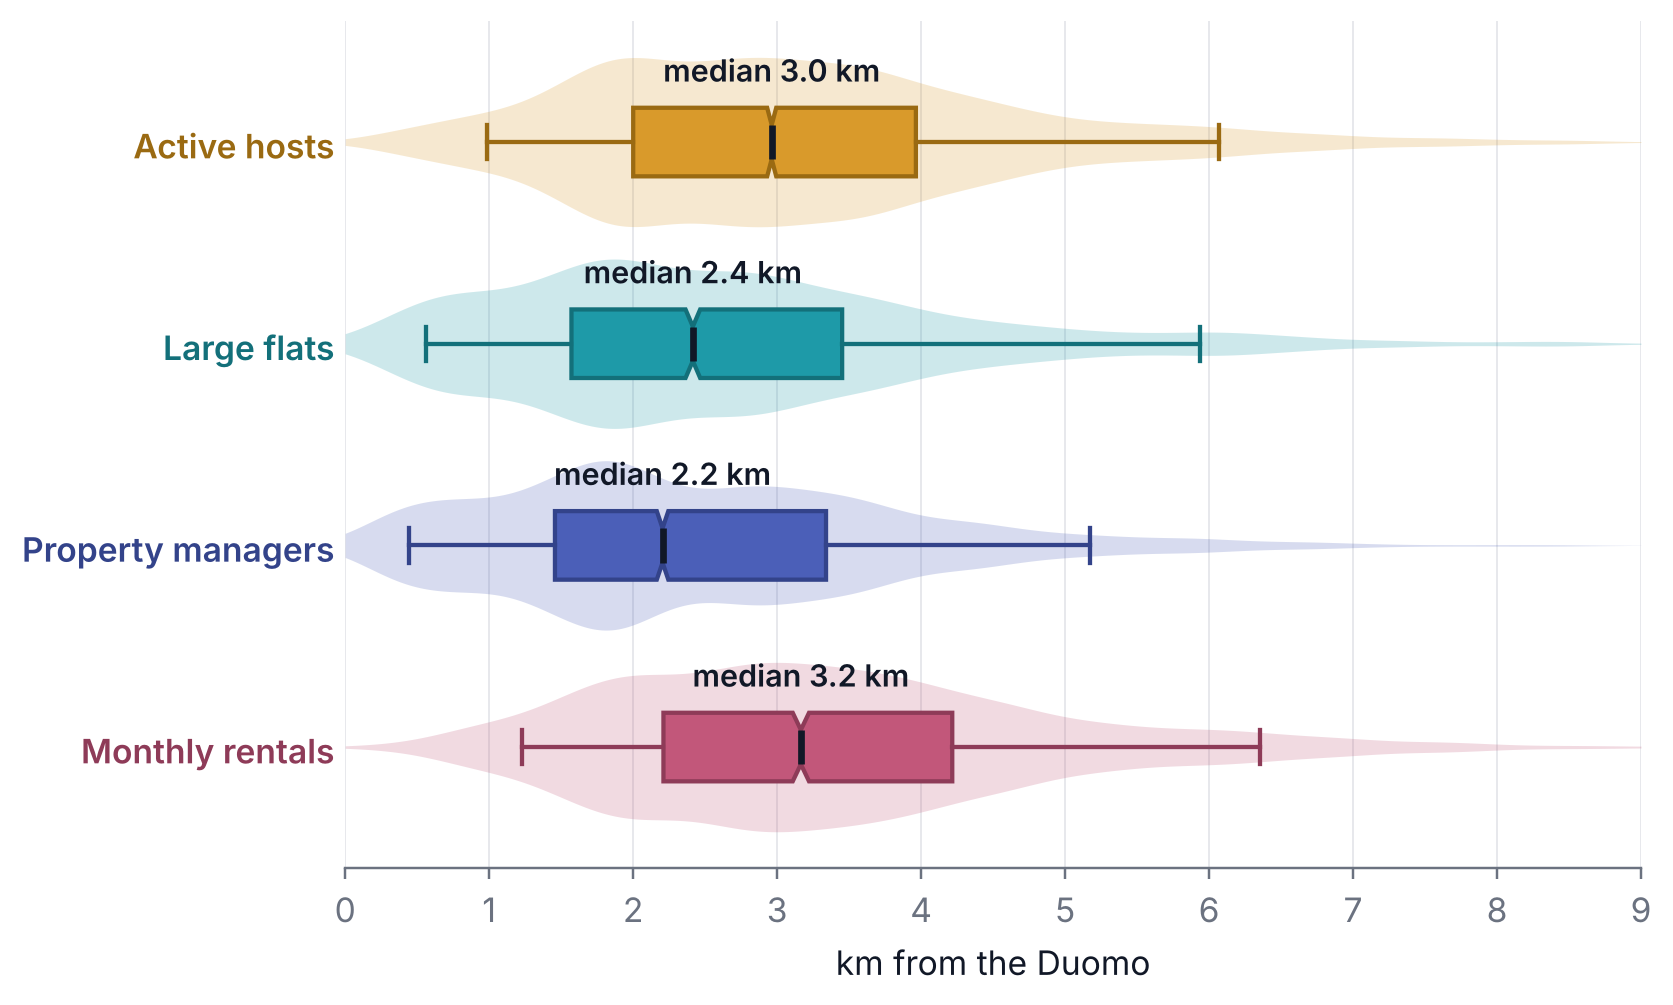

In [30]:
style('modern')
K = 4; B = pd.read_csv(O + 'heldout.csv')
from scipy.stats import gaussian_kde
fig, ax = plt.subplots(figsize=(7.6, 5.0)); xs = np.linspace(0, 9, 400)
for kk in range(K):
    d_ = B.loc[B.cluster == kk, 'Dist'].values; dens = gaussian_kde(d_, bw_method=0.18)(xs); dens = dens / dens.max() * 0.42
    y0 = 3 - kk
    ax.fill_between(xs, y0 - dens, y0 + dens, color=COL[kk], alpha=0.22, lw=0)
    ax.boxplot(d_, positions=[y0], orientation='horizontal', widths=0.34, notch=True, patch_artist=True, showfliers=False, whis=(5, 95),
               medianprops=dict(color=INK, lw=2.2), whiskerprops=dict(color=DARK[kk], lw=1.4), capprops=dict(color=DARK[kk], lw=1.4),
               boxprops=dict(facecolor=COL[kk], edgecolor=DARK[kk], lw=1.4))
    m = np.median(d_); ax.text(m, y0 + 0.3, f'median {m:.1f} km', fontsize=10, color=INK, fontweight='semibold', ha='center')
ax.set_yticks(range(4)); ax.set_yticklabels(NAMES[::-1], fontsize=11)
for tl, c in zip(ax.get_yticklabels(), DARK[::-1]): tl.set_color(c); tl.set_fontweight('semibold')
ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False); ax.set_ylim(-0.6, 3.6)
ax.set_xlim(0, 9); ax.set_xlabel('km from the Duomo', fontsize=11); ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
save(fig, 't_density')

## Slide 18 · Test 4 — neighbourhood maps

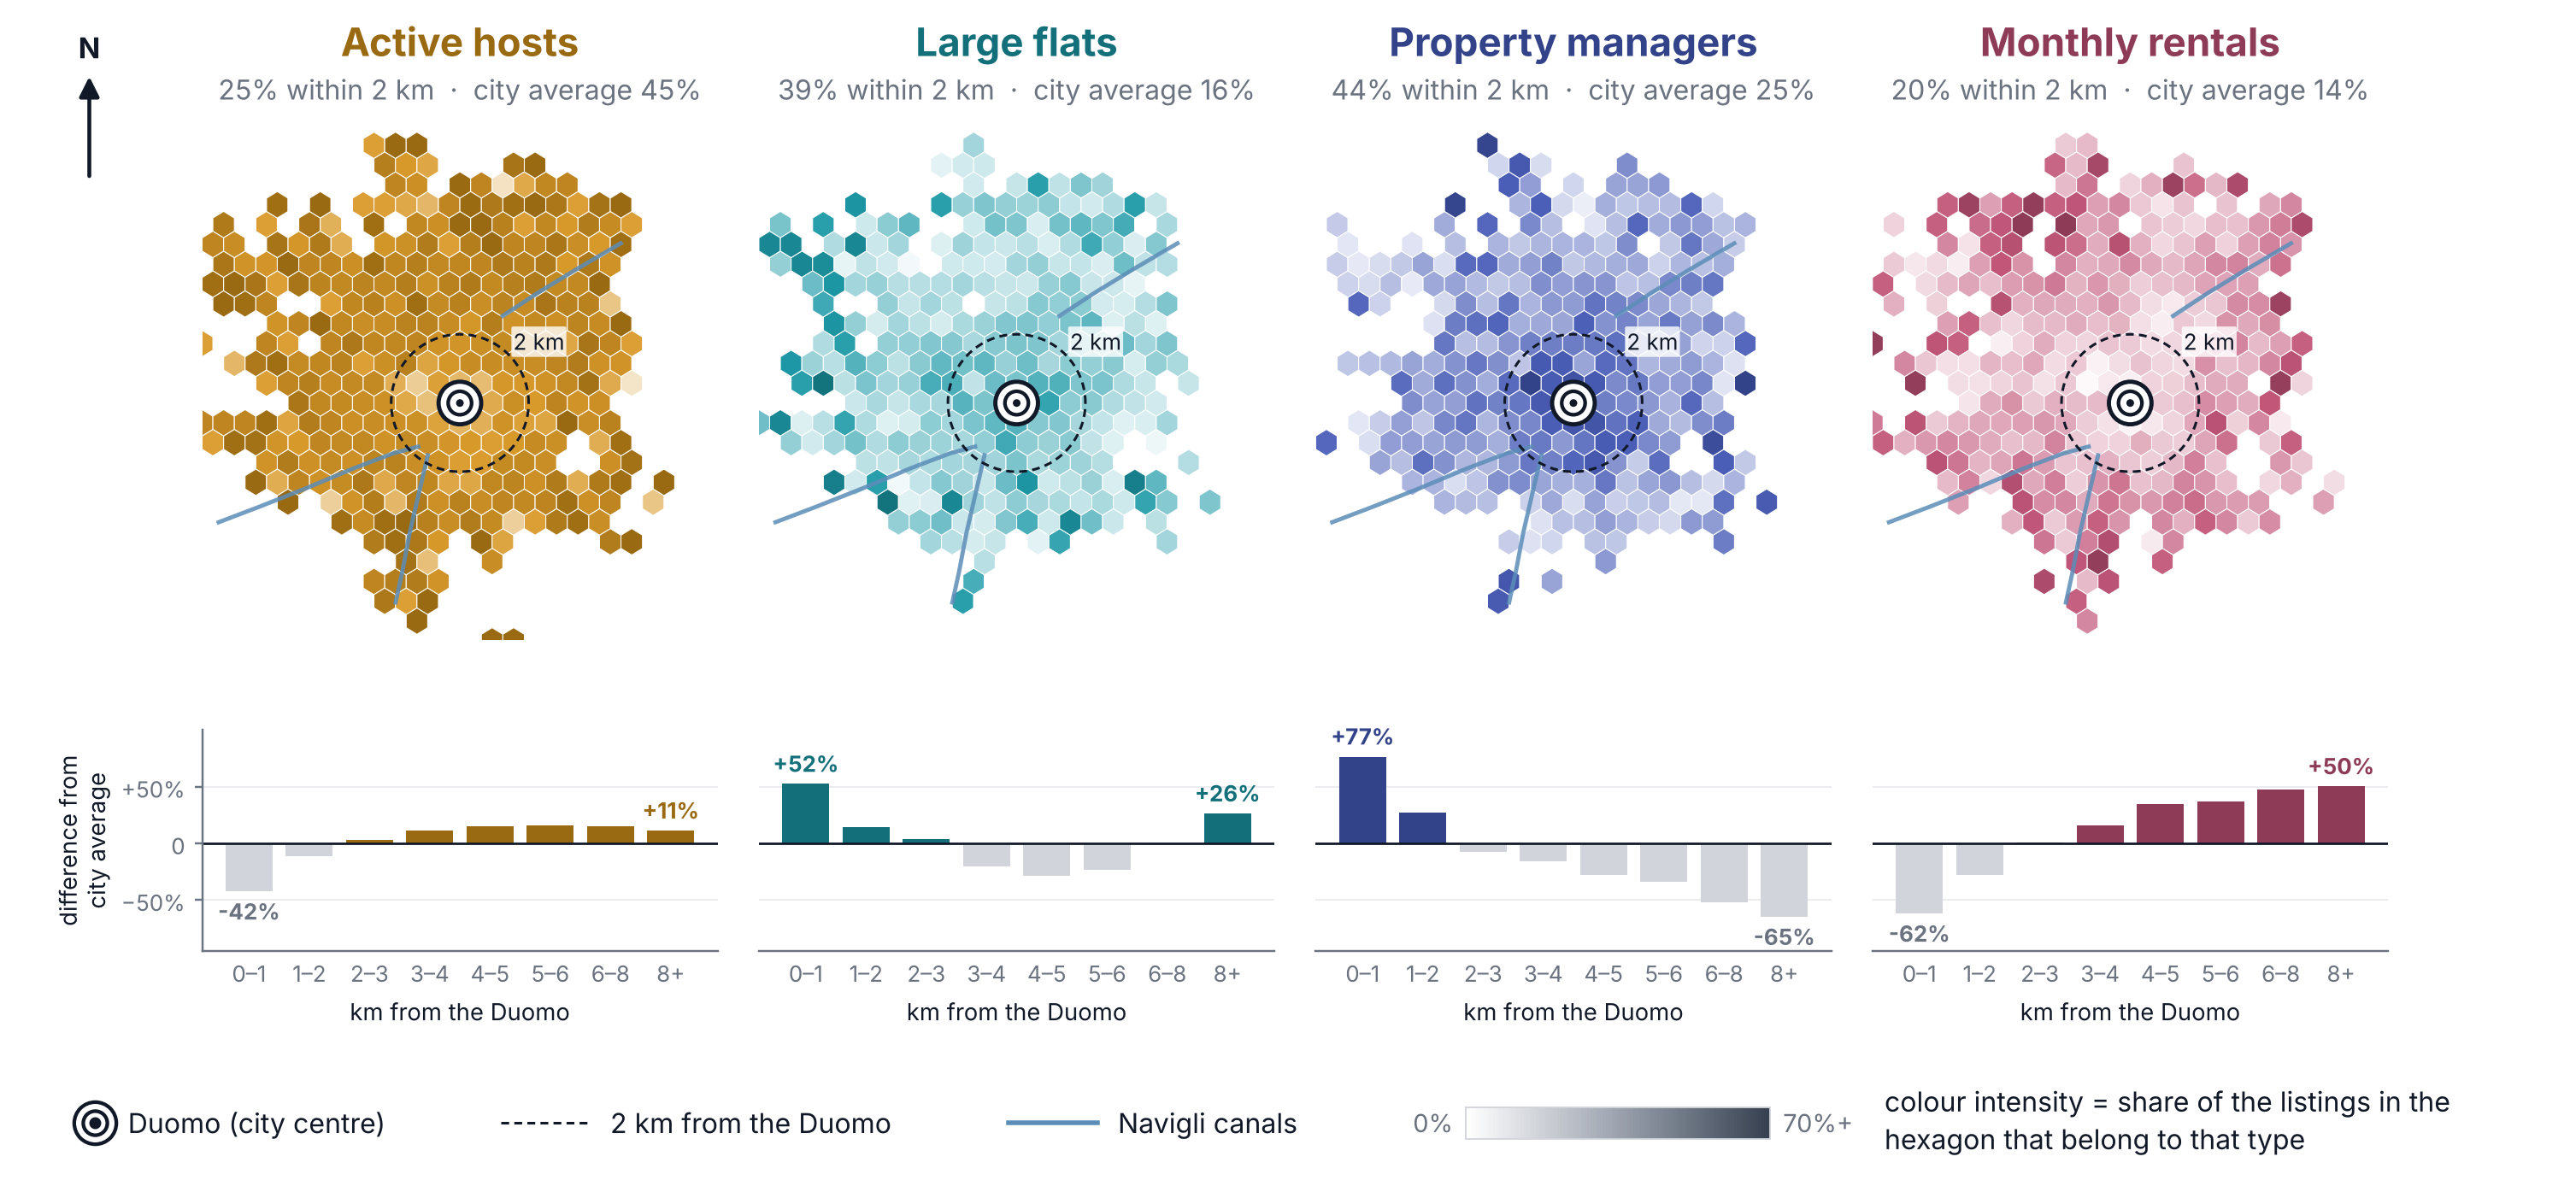

In [31]:
style('modern')
meta = json.load(open(O + 'meta.json')); K = meta['K']; B = pd.read_csv(O + 'heldout.csv')
lat0, lon0 = 45.4642, 9.1900; kx = 111.2 * np.cos(np.radians(lat0)); ky = 111.2
B['x'] = (B.lon - lon0) * kx; B['y'] = (B.lat - lat0) * ky
def xy(lat, lon): return (lon - lon0) * kx, (lat - lat0) * ky
CANALS = [[(45.4528, 9.1745), (45.4510, 9.1650), (45.4470, 9.1500), (45.4420, 9.1330), (45.4370, 9.1150), (45.4330, 9.1000)],
          [(45.4505, 9.1780), (45.4400, 9.1745), (45.4300, 9.1712), (45.4200, 9.1685), (45.4120, 9.1660)],
          [(45.4870, 9.2060), (45.4930, 9.2190), (45.4990, 9.2330), (45.5060, 9.2500)]]
def centro(a, x, y, r=0.62, z=7):
    """Italian 'centro' road sign: outer ring, inner ring, dot."""
    a.add_patch(Circle((x, y), r, fc='white', ec=INK, lw=1.6, zorder=z))
    a.add_patch(Circle((x, y), r * 0.55, fc='white', ec=INK, lw=1.4, zorder=z))
    a.add_patch(Circle((x, y), r * 0.18, fc=INK, ec=INK, lw=0, zorder=z))

rel = pd.read_csv(O + 'rel_by_distance.csv', index_col=0)
fig = plt.figure(figsize=(15, 6.5))
gs = fig.add_gridspec(2, 4, height_ratios=[3.4, 1.15], hspace=0.04, wspace=0.08, bottom=0.17, top=0.9)
for kk in range(K):
    a = fig.add_subplot(gs[0, kk]); t = np.linspace(0, 2 * np.pi, 200)
    cmk = LSC2.from_list(f'hh{kk}', ['#FFFFFF', COL[kk], DARK[kk]])
    ind = (B.cluster == kk).astype(float).values
    a.hexbin(B.x, B.y, C=ind, reduce_C_function=np.mean, gridsize=24, extent=(-7.5, 7.5, -7.5, 7.5), mincnt=3, cmap=cmk, vmin=0, vmax=0.7, linewidths=0.35, edgecolors='white', zorder=1)
    for cn in CANALS:
        cx, cy = zip(*[xy(*p_) for p_ in cn]); a.plot(cx, cy, color='#5B8DB8', lw=1.6, alpha=0.85, zorder=2)
    a.plot(2 * np.cos(t), 2 * np.sin(t), color=INK, lw=1.0, ls=(0, (3, 2)), zorder=3)
    centro(a, 0, 0)
    a.text(1.55, 1.55, '2 km', fontsize=8.5, color=INK, zorder=6, bbox=dict(boxstyle='round,pad=0.08', fc='white', ec='none', alpha=0.8))
    s_ = B[B.cluster == kk]
    a.text(0.5, 1.13, NAMES[kk], transform=a.transAxes, ha='center', va='bottom', fontsize=15, fontweight='bold', color=DARK[kk])
    a.text(0.5, 1.05, f'{(s_.Dist <= 2).mean()*100:.0f}% within 2 km  ·  city average {len(s_)/len(B)*100:.0f}%', transform=a.transAxes, ha='center', va='bottom', fontsize=10.5, color=MUTED)
    a.set_xlim(-7.5, 7.5); a.set_ylim(-6.9, 7.9); a.set_aspect('equal'); a.axis('off')
    b = fig.add_subplot(gs[1, kk]); r = rel[str(kk)].values * 100; xs = np.arange(len(r))
    b.bar(xs, r, color=[DARK[kk] if v_ > 0 else '#D1D5DB' for v_ in r], width=0.78)
    b.axhline(0, color=INK, lw=0.9); b.set_ylim(-95, 100); b.set_yticks([-50, 0, 50]); b.set_yticklabels(['−50%', '0', '+50%'] if kk == 0 else [''] * 3, fontsize=8.5)
    b.set_xticks(xs); b.set_xticklabels(rel.index, fontsize=8.5); b.grid(axis='y', color=GRID, lw=0.5); b.set_axisbelow(True)
    b.spines['left'].set_visible(kk == 0); b.tick_params(axis='y', length=0 if kk else 3); b.tick_params(axis='x', length=0)
    for xi, v_ in zip(xs[[0, -1]], r[[0, -1]]): b.text(xi, v_ + (6 if v_ > 0 else -6), f'{v_:+.0f}%', ha='center', va='bottom' if v_ > 0 else 'top', fontsize=8.5, fontweight='bold', color=DARK[kk] if v_ > 0 else MUTED)
    if kk == 0: b.set_ylabel('difference from\ncity average', fontsize=9)
    b.set_xlabel('km from the Duomo', fontsize=9)
# north arrow, outside the first map on the left
fig.add_artist(mpl.patches.FancyArrowPatch((0.085, 0.80), (0.085, 0.89), transform=fig.transFigure, arrowstyle='-|>', mutation_scale=16, color=INK, lw=1.5))
fig.text(0.085, 0.895, 'N', ha='center', va='bottom', fontsize=11, fontweight='bold')
# legend row
L = fig.add_axes([0.06, 0.0, 0.9, 0.065]); L.set_xlim(0, 100); L.set_ylim(0, 1); L.axis('off')
for s_, fc, ec in [(260, 'white', INK), (85, 'white', INK), (10, INK, INK)]: L.scatter(3.0, 0.45, s=s_, fc=fc, ec=ec, lw=1.4, zorder=3)
L.text(4.3, 0.45, 'Duomo (city centre)', va='center', fontsize=10.5)
L.plot([19, 22.5], [0.45, 0.45], color=INK, lw=1.0, ls=(0, (3, 2))); L.text(23.3, 0.45, '2 km from the Duomo', va='center', fontsize=10.5)
L.plot([39, 42.5], [0.45, 0.45], color='#5B8DB8', lw=1.8); L.text(43.3, 0.45, 'Navigli canals', va='center', fontsize=10.5)
grad = np.linspace(0, 1, 100).reshape(1, -1)
L.imshow(grad, extent=(57, 69, 0.25, 0.65), cmap=LSC2.from_list('g', ['#FFFFFF', '#9CA3AF', '#374151']), aspect='auto', zorder=1)
L.add_patch(plt.Rectangle((57, 0.25), 12, 0.4, fill=False, ec='#D1D5DB', lw=0.6))
L.text(56.5, 0.45, '0%', ha='right', va='center', fontsize=9.5, color=MUTED); L.text(69.5, 0.45, '70%+', ha='left', va='center', fontsize=9.5, color=MUTED)
L.text(73.5, 0.45, 'colour intensity = share of the listings in the\nhexagon that belong to that type', va='center', fontsize=10.5, linespacing=1.15)
save(fig, 'g_hexrow')

## Slide 19 · Neighbourhoods: price vs share of property managers

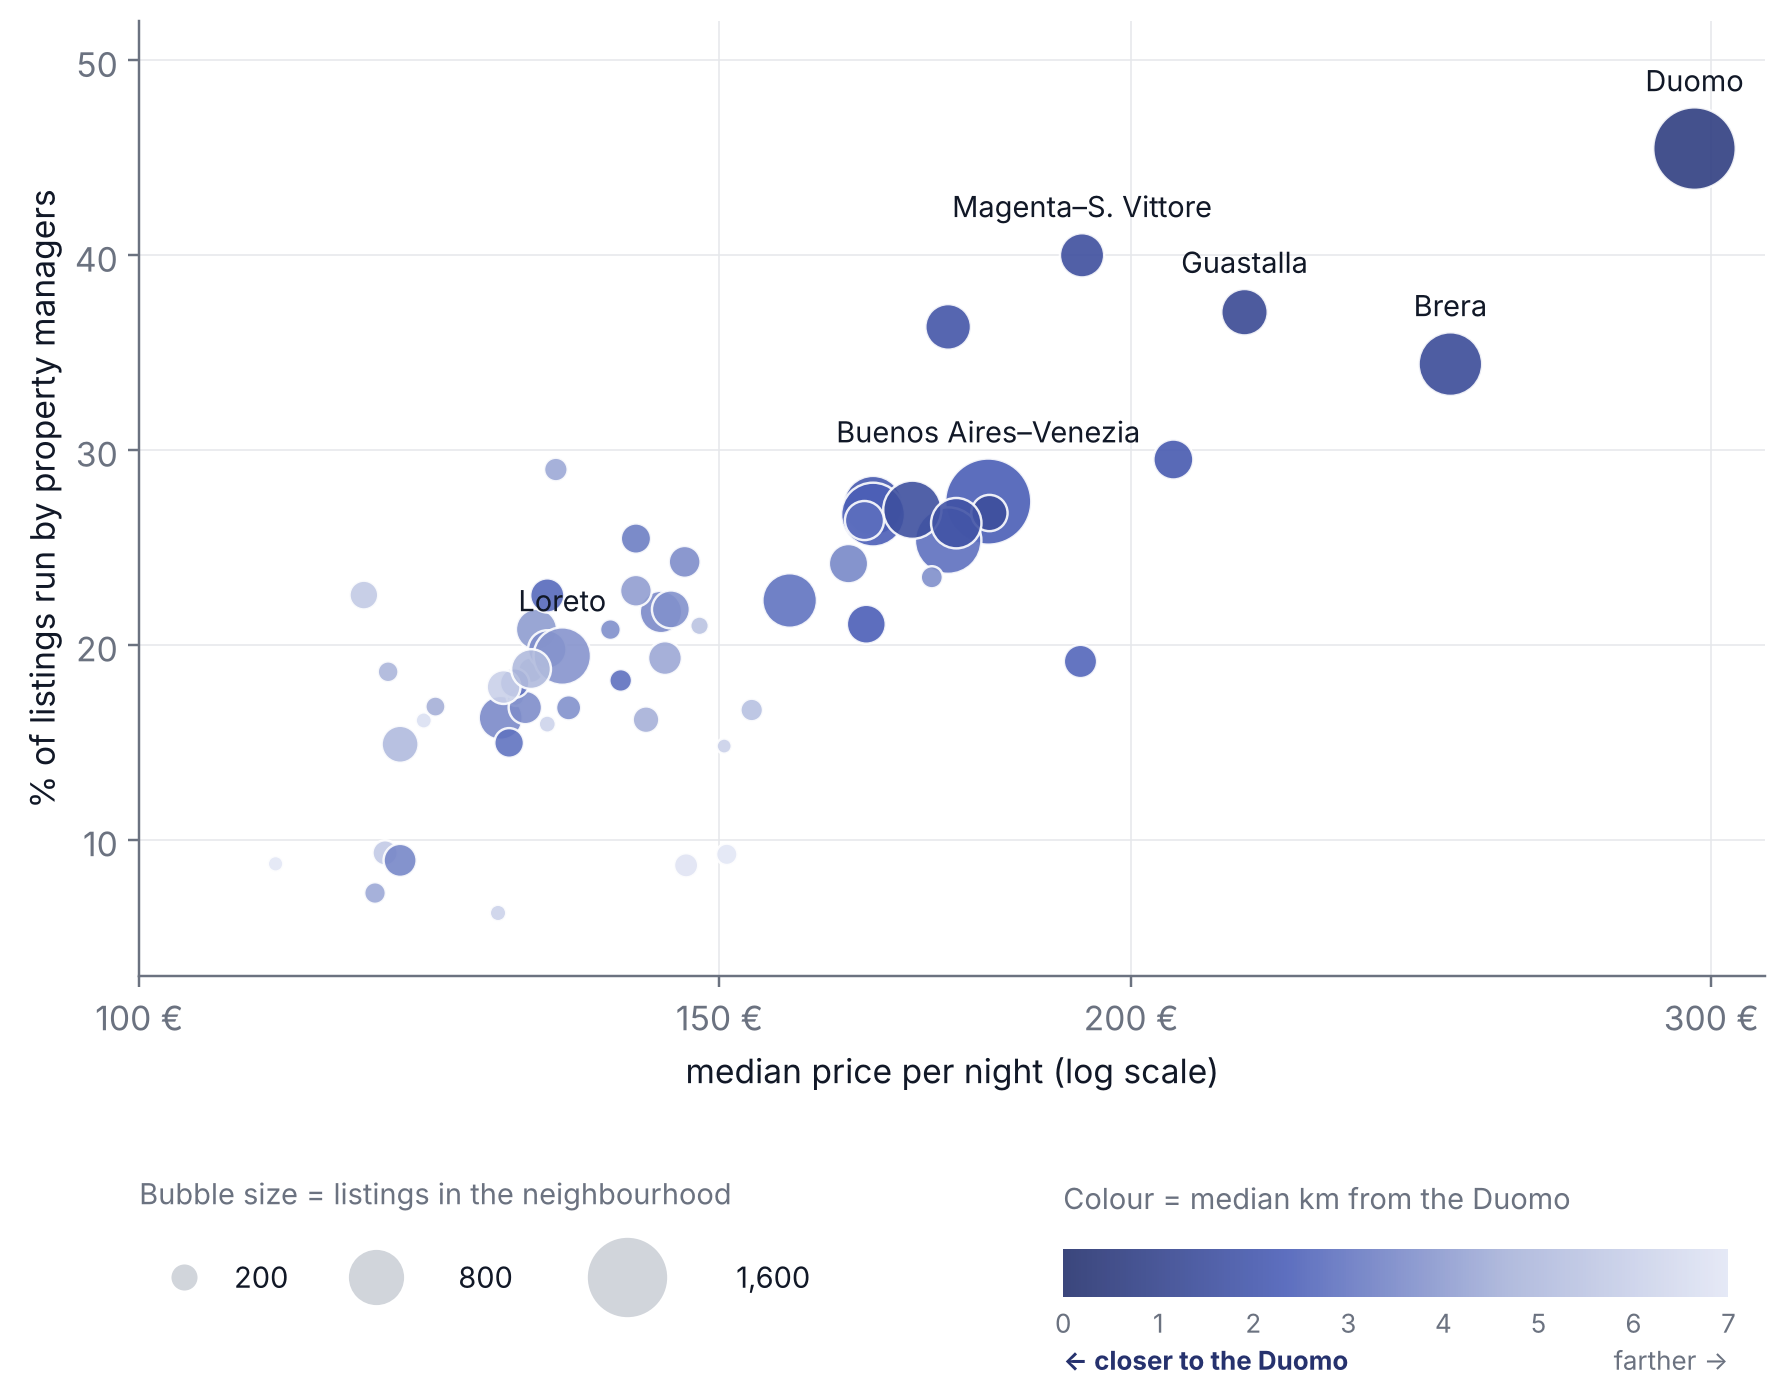

In [32]:
style('plain')
N = pd.read_csv(O + 'neighbourhoods.csv', index_col=0); N = N[N.n >= 50]
cmb = LSC.from_list('pm', ['#26326E', '#4B5FB8', '#A9B4DA', '#E3E7F5'])
fig = plt.figure(figsize=(8.4, 6.2))
ax = fig.add_axes([0.1, 0.27, 0.88, 0.7])
sc = ax.scatter(N.price, N.managers * 100, s=N.n / 2.2, c=N.dist, cmap=cmb, vmin=0, vmax=7, alpha=0.9, edgecolor='white', lw=0.8)
show = set(N.sort_values('n', ascending=False).index[:2]) | set(N.sort_values('managers', ascending=False).index[:3]) | {'LORETO', 'BRERA'}
for nm_, r in N.iterrows():
    if nm_ in show:
        rad = np.sqrt(r.n / 2.2) / 2
        ax.annotate(nm_.title().replace(' - ', '–'), (r.price, r.managers * 100), xytext=(0, rad + 3), textcoords='offset points', ha='center', va='bottom', fontsize=9.5, color=INK)
ax.set_xscale('log'); ax.set_xticks([100, 150, 200, 300]); ax.set_xticklabels(['100 €', '150 €', '200 €', '300 €']); ax.set_ylim(3, 52); ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel('median price per night (log scale)', fontsize=11); ax.set_ylabel('% of listings run by property managers', fontsize=11)
ax.grid(color=GRID, lw=0.5); ax.set_axisbelow(True)
# size legend: three bubbles side by side
L = fig.add_axes([0.1, 0.0, 0.4, 0.13]); L.set_xlim(0, 10); L.set_ylim(0, 1); L.axis('off')
L.text(0, 0.95, 'Bubble size = listings in the neighbourhood', fontsize=9.5, color=MUTED, va='top')
for x_, n_ in [(0.6, 200), (3.2, 800), (6.6, 1600)]:
    L.scatter(x_, 0.38, s=n_ / 2.2, color='#D1D5DB', edgecolor='white')
    L.text(x_ + 0.25 + np.sqrt(n_ / 2.2) / 22, 0.38, f'{n_:,}', va='center', fontsize=9.5)
# horizontal distance scale: dark = close to the Duomo
C = fig.add_axes([0.6, 0.035, 0.36, 0.035])
cb = fig.colorbar(sc, cax=C, orientation='horizontal'); cb.outline.set_visible(False)
cb.set_ticks([0, 1, 2, 3, 4, 5, 6, 7]); cb.ax.tick_params(labelsize=8.5, length=0)
fig.text(0.6, 0.12, 'Colour = median km from the Duomo', fontsize=9.5, color=MUTED, va='top')
fig.text(0.6, 0.0, '← closer to the Duomo', fontsize=8.5, color='#26326E', va='top', fontweight='bold')
fig.text(0.96, 0.0, 'farther →', fontsize=8.5, color=MUTED, va='top', ha='right')
save(fig, 'g_bubble')

## Slide 20 · Superhost prediction: ROC and partial dependence

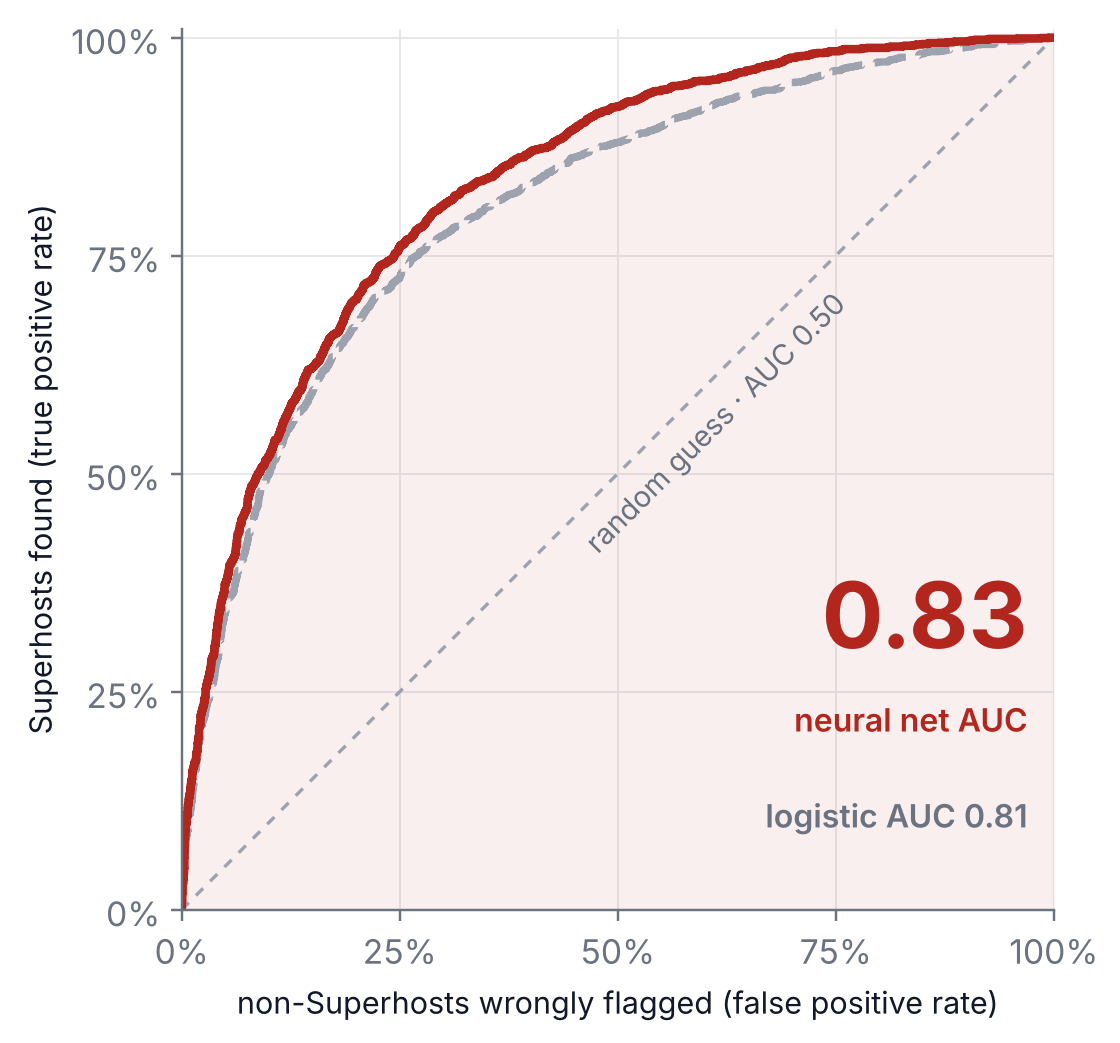

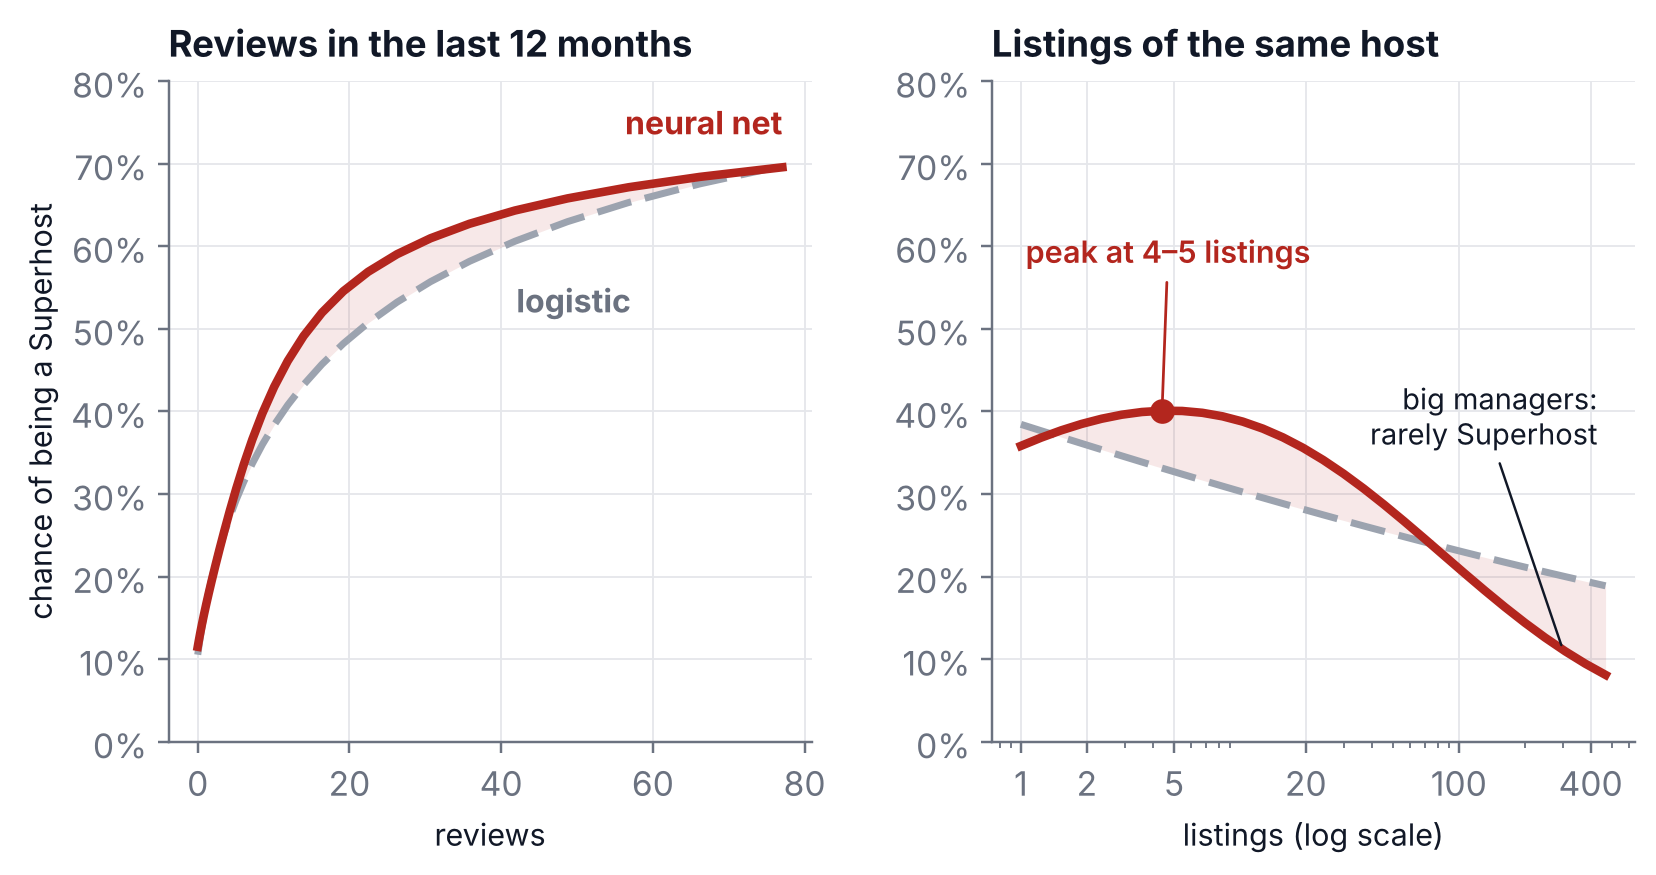

In [33]:
style('plain')
GREYL = '#9CA3AF'
sup = json.load(open(O + 'meta.json'))['sup']; roc = pd.read_csv(O + 'roc.csv'); pdp = pd.read_csv(O + 'pdp.csv')
NN, LG = 'Neural network', 'Logistic regression'
# ---- ROC
fig, a = plt.subplots(figsize=(5.2, 5.2))
nn = roc[roc.model == NN]; lg = roc[roc.model == LG]
a.fill_between(nn.fpr, 0, nn.tpr, color=RED, alpha=0.07, lw=0)
a.plot([0, 1], [0, 1], color=GREYL, lw=1.1, ls=(0, (3, 3)))
a.text(0.62, 0.55, 'random guess · AUC 0.50', rotation=45, rotation_mode='anchor', ha='center', fontsize=9.5, color=MUTED)
a.plot(lg.fpr, lg.tpr, color=GREYL, lw=2.4, ls=(0, (5, 2)))
a.plot(nn.fpr, nn.tpr, color=RED, lw=2.8)
a.text(0.97, 0.30, f"{sup[NN]['test']:.2f}", ha='right', fontsize=30, fontweight='bold', color=RED)
a.text(0.97, 0.24, 'neural net AUC', ha='right', va='top', fontsize=10.5, color=RED, fontweight='semibold')
a.text(0.97, 0.13, f"logistic AUC {sup[LG]['test']:.2f}", ha='right', va='top', fontsize=10.5, color=MUTED, fontweight='semibold')
a.set_xlim(0, 1); a.set_ylim(0, 1.01); a.set_aspect('equal')
a.set_xticks([0, 0.25, 0.5, 0.75, 1]); a.set_yticks([0, 0.25, 0.5, 0.75, 1])
a.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); a.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
a.set_xlabel('non-Superhosts wrongly flagged (false positive rate)', fontsize=10); a.set_ylabel('Superhosts found (true positive rate)', fontsize=10)
a.grid(color=GRID, lw=0.6); a.set_axisbelow(True)
save(fig, 'sup_roc')
# ---- partial dependence
fig, axs = plt.subplots(1, 2, figsize=(8.6, 3.9)); fig.subplots_adjust(wspace=0.28)
for a, v, tt in zip(axs, ['Reviews, last 12 m', 'Host listings'], ['Reviews in the last 12 months', 'Listings of the same host']):
    n_ = pdp[(pdp['var'] == v) & (pdp.model == NN)].sort_values('x'); l_ = pdp[(pdp['var'] == v) & (pdp.model == LG)].sort_values('x')
    yl = np.interp(n_.x, l_.x, l_.p) * 100
    a.fill_between(n_.x, n_.p * 100, yl, color=RED, alpha=0.10, lw=0)
    a.plot(l_.x, l_.p * 100, color=GREYL, lw=2.3, ls=(0, (5, 2)))
    a.plot(n_.x, n_.p * 100, color=RED, lw=2.8)
    a.set_title(tt, loc='left', fontsize=12, fontweight='bold', pad=8)
    a.grid(color=GRID, lw=0.6); a.set_axisbelow(True); a.set_ylim(0, 80)
    a.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda y, _: f'{y:.0f}%'))
    if v == 'Host listings':
        a.set_xscale('log'); a.set_xticks([1, 2, 5, 20, 100, 400]); a.set_xticklabels(['1', '2', '5', '20', '100', '400'])
        a.xaxis.set_minor_formatter(mpl.ticker.NullFormatter()); a.set_xlabel('listings (log scale)', fontsize=10)
        i = n_.p.values.argmax(); px, py = n_.x.values[i], n_.p.values[i] * 100
        a.scatter(px, py, s=50, color=RED, zorder=4)
        a.annotate('peak at 4–5 listings', (px, py), xytext=(1.05, 58), fontsize=10, color=RED, fontweight='semibold',
                   arrowprops=dict(arrowstyle='-', color=RED, lw=0.9))
        a.annotate('big managers:\nrarely Superhost', (300, 11), xytext=(430, 36), ha='right', fontsize=9.5, color=INK, arrowprops=dict(arrowstyle='-', color=INK, lw=0.8))
    else:
        a.set_xlabel('reviews', fontsize=10); a.set_ylabel('chance of being a Superhost', fontsize=10)
        x_end = n_.x.values[-1]
        a.text(x_end, n_.p.values[-1] * 100 + 4, 'neural net', ha='right', fontsize=10.5, color=RED, fontweight='bold')
        a.text(42, 52, 'logistic', ha='left', fontsize=10.5, color=MUTED, fontweight='bold')
save(fig, 'sup_pdp')

## Slide 21 · What the neural net looks at (SHAP)

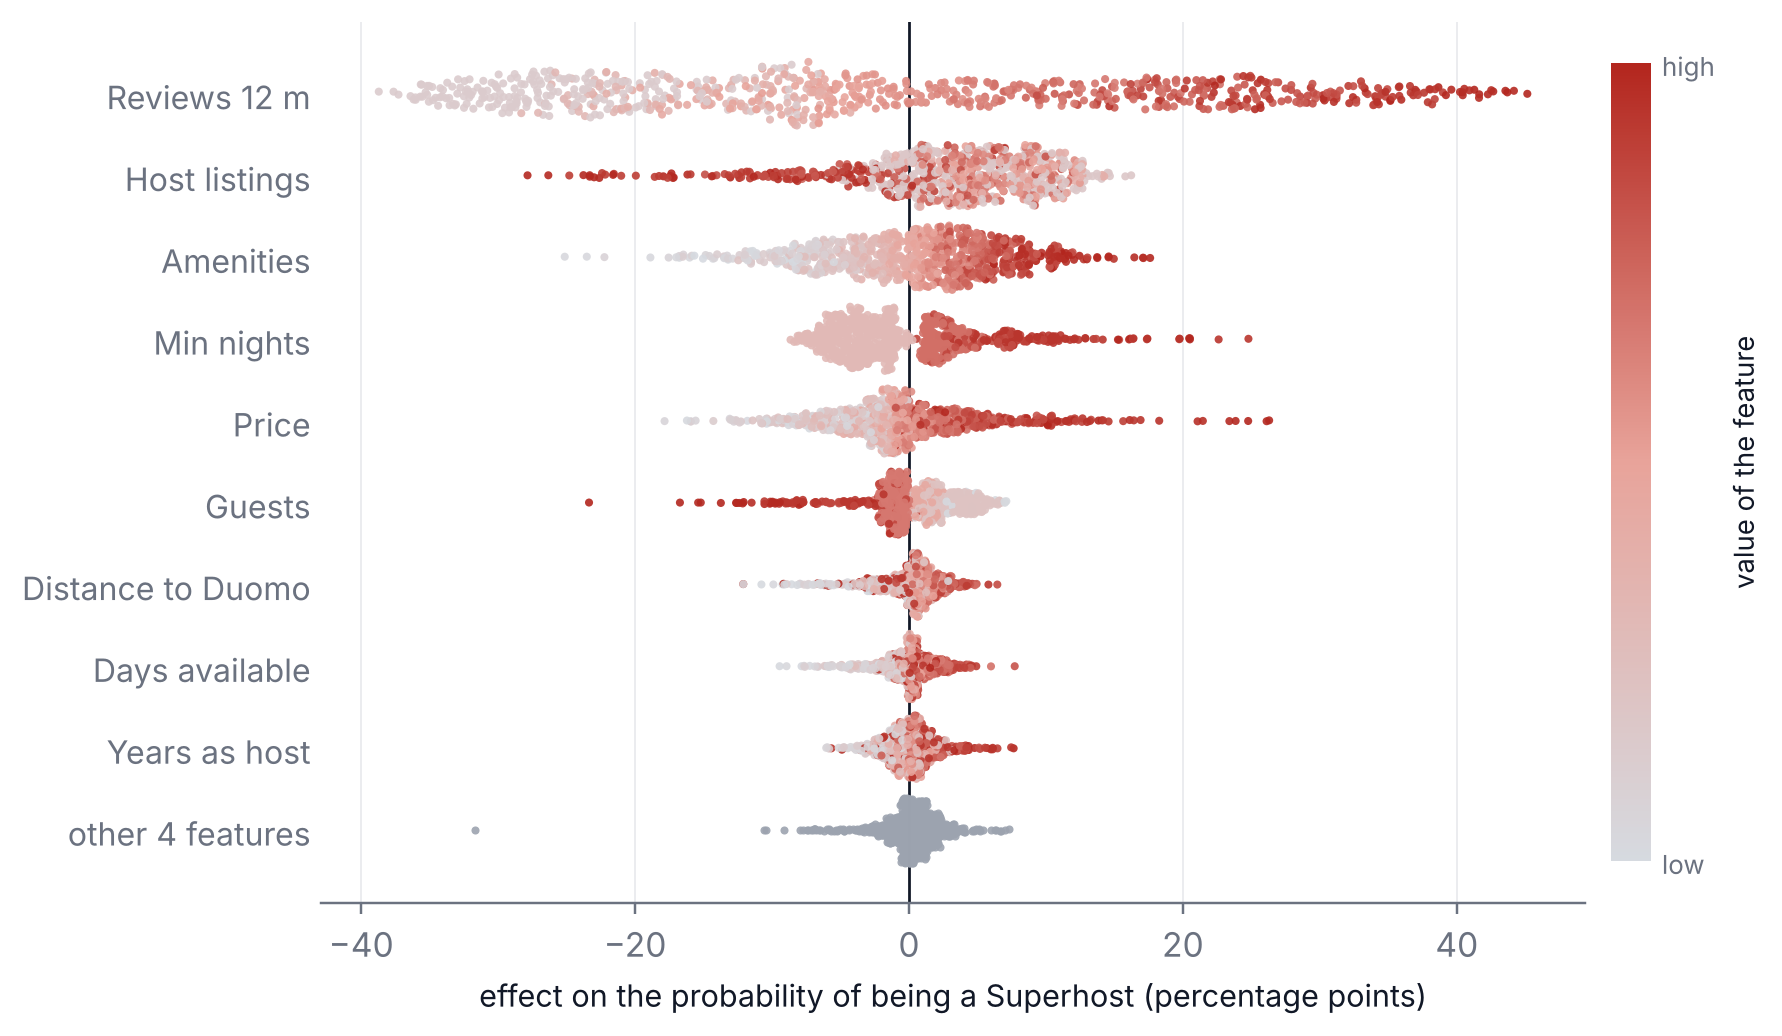

In [34]:
style('modern')
SHORT = {'Price / night': 'Price', 'Minimum nights': 'Min nights', 'Days available / year': 'Days available', 'Reviews, last 12 m': 'Reviews 12 m',
         'Host listings': 'Host listings', 'Years as host': 'Years as host'}
Sv = np.load(O + 'shap_nn.npz', allow_pickle=True); V = Sv['values'] * 100; R = Sv['raw']; FN = list(Sv['feats'])
order = np.argsort(np.abs(V).mean(0))[::-1]; top = order[:9]; rest = order[9:]
rows = [(SHORT.get(FN[i], FN[i]), V[:, i], R[:, i]) for i in top] + [(f'other {len(rest)} features', V[:, rest].sum(1), None)]
cmv = LSC2.from_list('val', ['#D6DAE0', '#E8A39A', '#B3261E'])
fig, ax = plt.subplots(figsize=(7.8, 5.2)); rsb = np.random.RandomState(0)
for r, (nm_, v, raw) in enumerate(rows):
    y0 = len(rows) - 1 - r
    bins = np.linspace(v.min(), v.max() + 1e-9, 40); idx = np.digitize(v, bins); cnt = np.bincount(idx, minlength=len(bins) + 1)
    dens = cnt[idx] / cnt.max(); jit = (rsb.rand(len(v)) - 0.5) * 0.8 * dens
    col = '#9CA3AF' if raw is None else cmv(pd.Series(raw).rank(pct=True).values)
    ax.scatter(v, y0 + jit, s=7, c=col, lw=0, alpha=0.9, zorder=3)
ax.axvline(0, color=INK, lw=0.9, zorder=2)
ax.set_yticks(range(len(rows))); ax.set_yticklabels([r_[0] for r_ in rows][::-1], fontsize=10.5); ax.tick_params(axis='y', length=0); ax.spines['left'].set_visible(False)
ax.set_xlabel('effect on the probability of being a Superhost (percentage points)', fontsize=10); ax.grid(axis='x', color=GRID, lw=0.5); ax.set_axisbelow(True)
sm = mpl.cm.ScalarMappable(cmap=cmv, norm=mpl.colors.Normalize(0, 1)); cb = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
cb.set_ticks([0, 1]); cb.set_ticklabels(['low', 'high']); cb.set_label('value of the feature', fontsize=9); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8.5, length=0)
save(fig, 'sup_shap')

## Slides 22–23 · The market over time

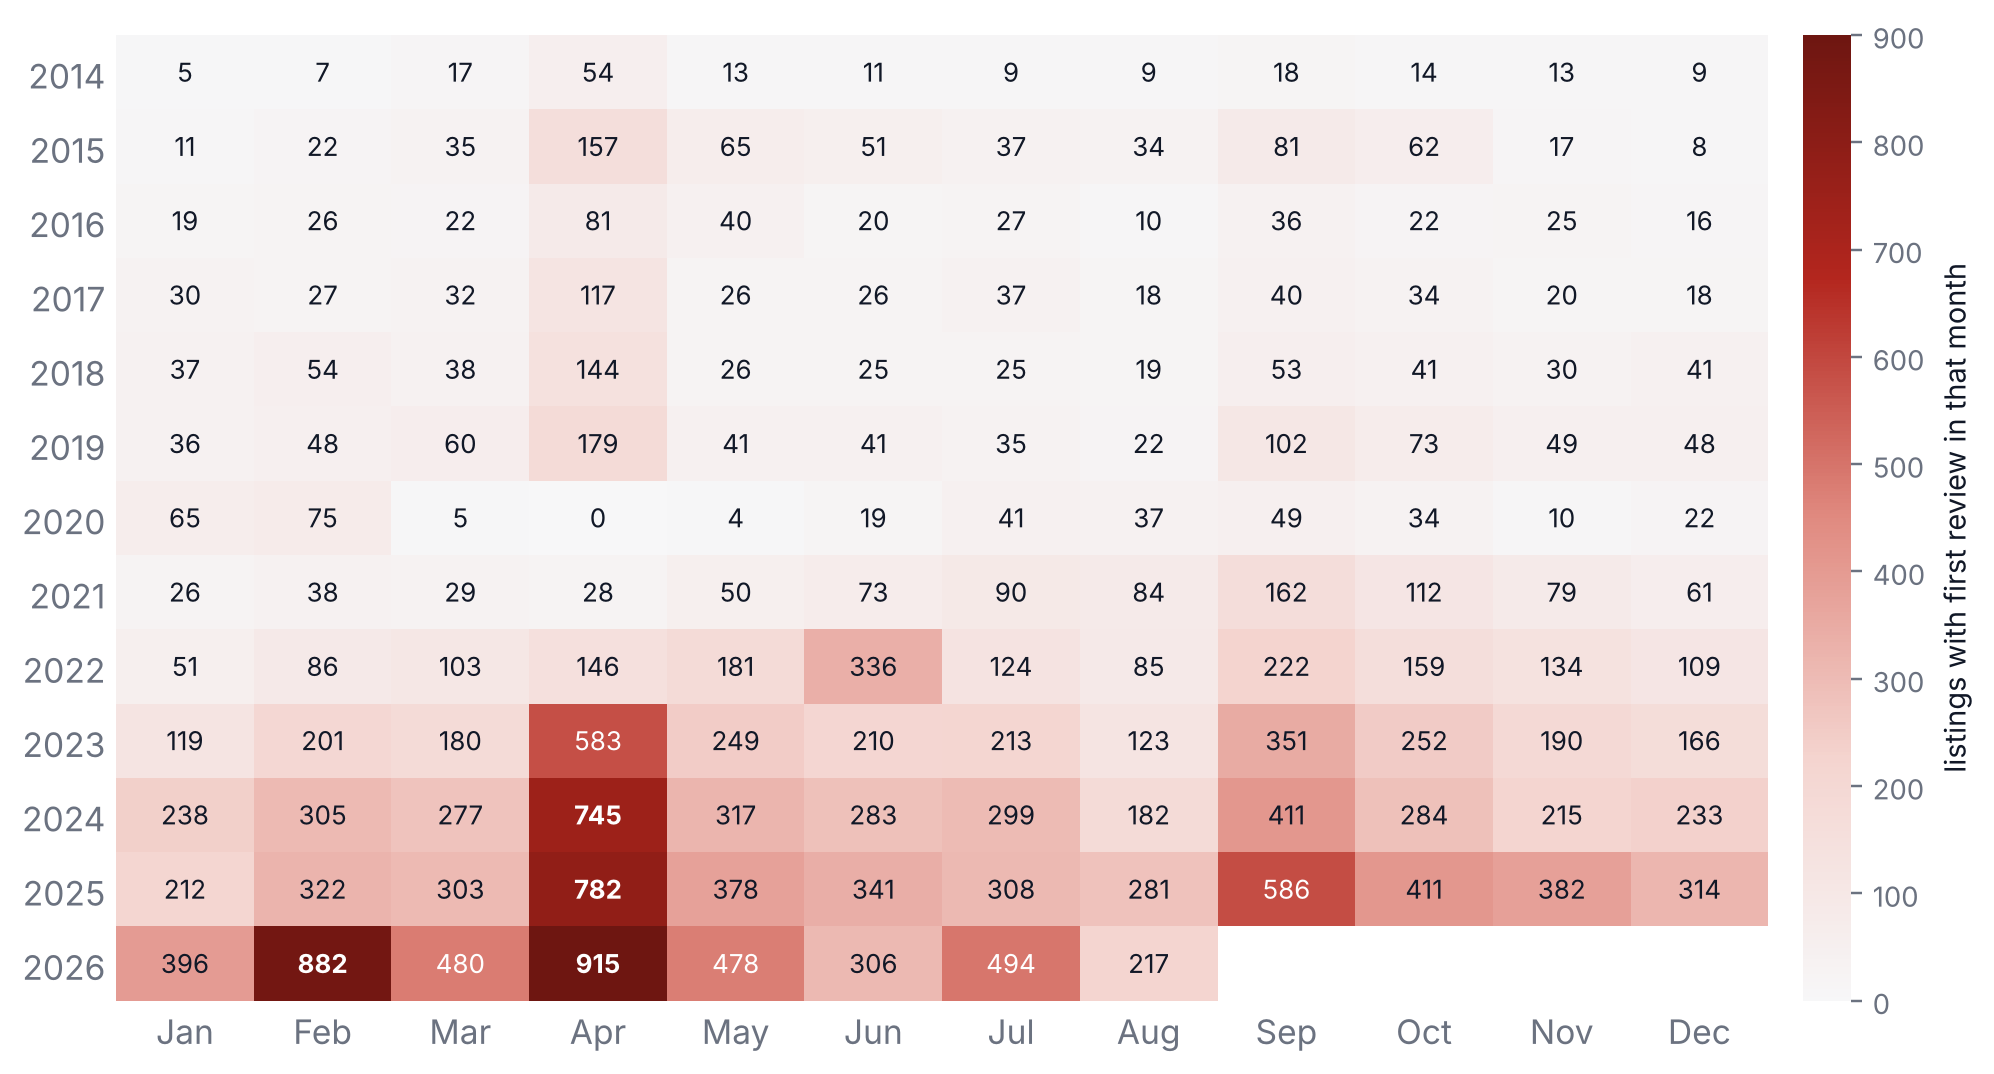

Feb 2026 882.0 Feb 2025 322.0


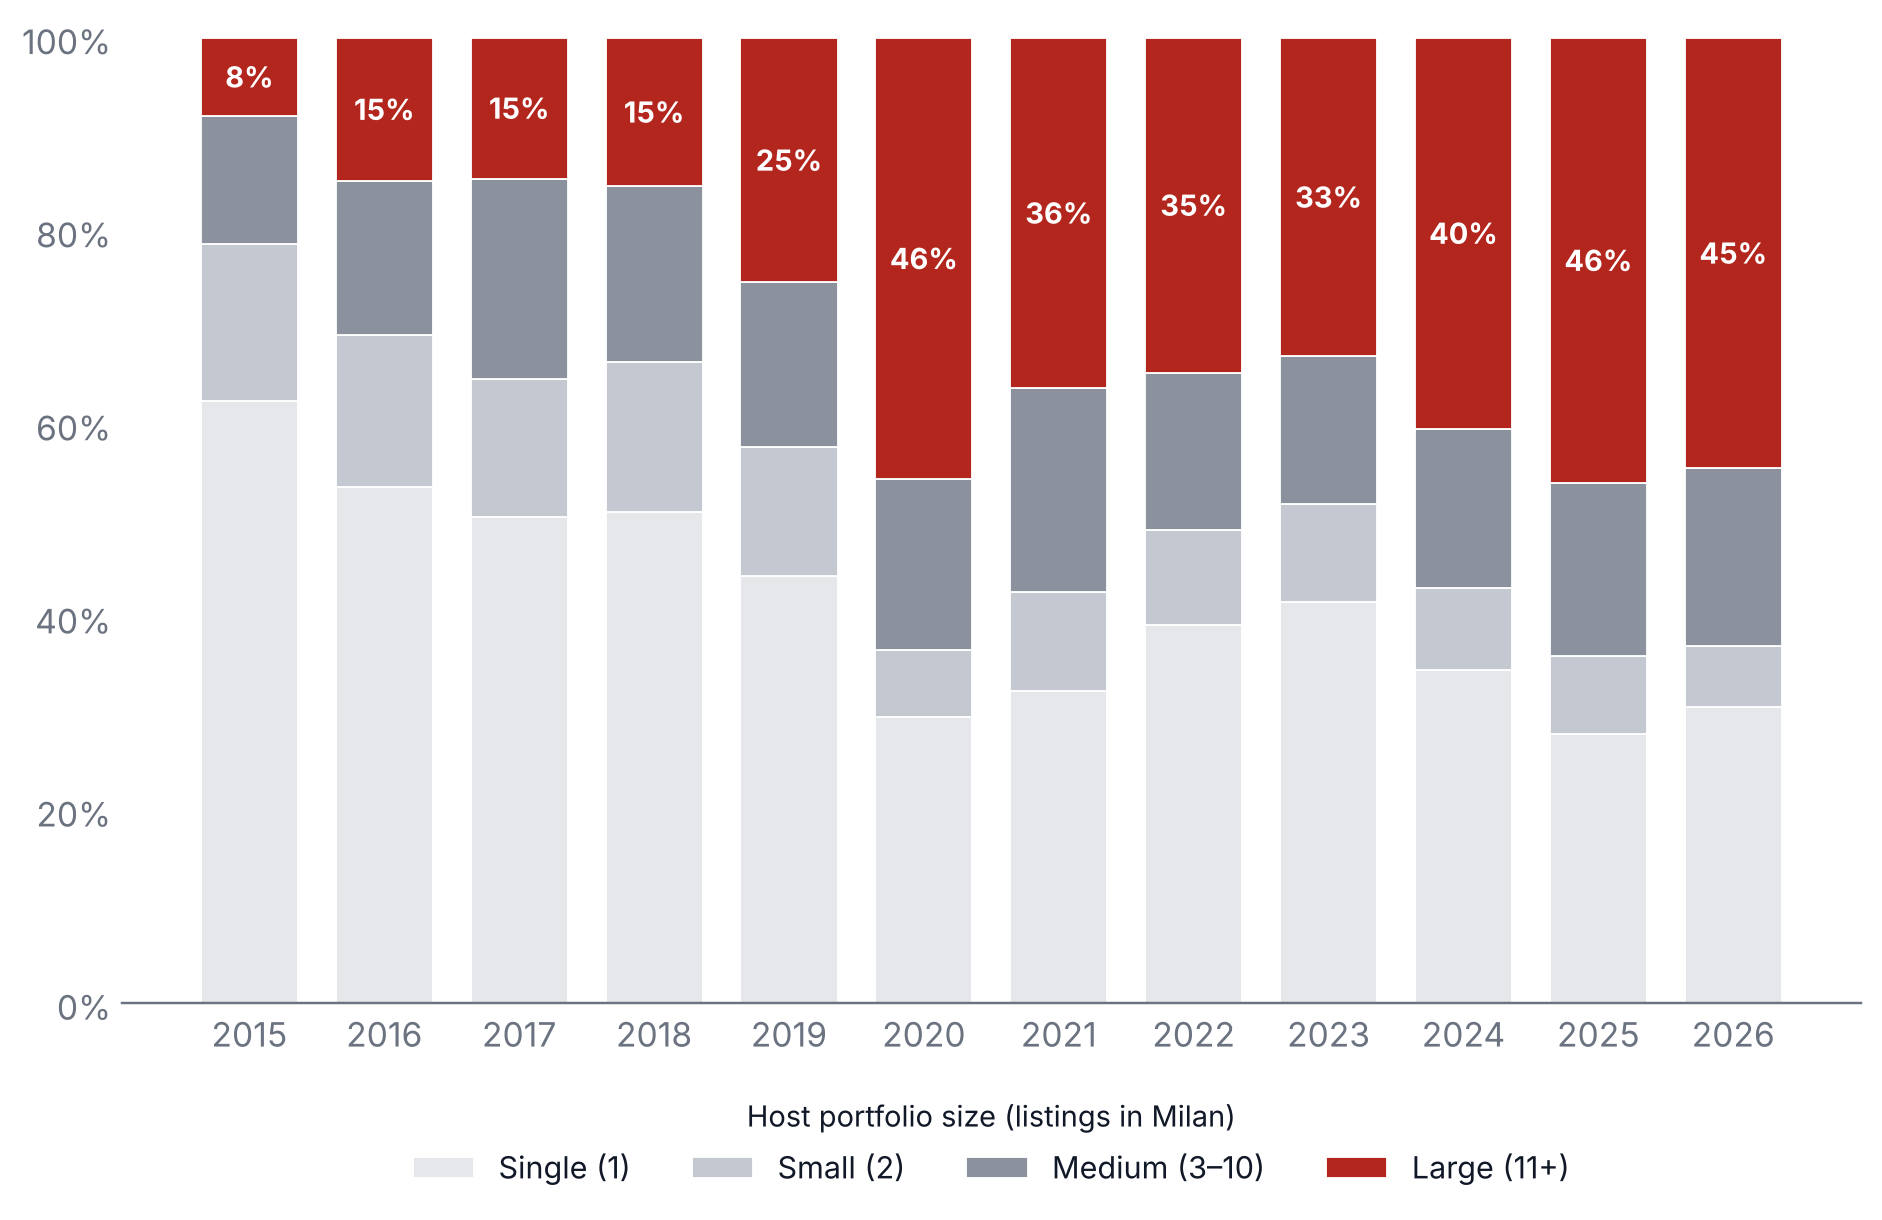

{2015: 8.1, 2016: 14.8, 2017: 14.6, 2018: 15.4, 2019: 25.3, 2020: 45.7, 2021: 36.3, 2022: 34.7, 2023: 33.0, 2024: 40.5, 2025: 46.1, 2026: 44.6}


In [35]:
style('heat')
d = pd.read_csv(DATA, usecols=['id', 'first_review', 'calculated_host_listings_count'])
d['fr'] = pd.to_datetime(d.first_review); d = d.dropna(subset=['fr'])
d['y'], d['m'] = d.fr.dt.year, d.fr.dt.month

# ---- heatmap: new listings by month of first review, 2014-2026 (2026 up to August)
H = d[(d.y >= 2014)].groupby(['y', 'm']).size().unstack(fill_value=0).reindex(index=range(2014, 2027), columns=range(1, 13), fill_value=0).astype(float)
H.loc[2026, 9:] = np.nan
cm = LSC.from_list('red', ['#F7F7F8', '#F4D4CF', '#E08A80', RED, '#6E1611'])
fig, ax = plt.subplots(figsize=(10.2, 5.7))
im = ax.imshow(H.values, cmap=cm, vmin=0, vmax=900, aspect='auto')
for i in range(H.shape[0]):
    for j in range(12):
        v = H.values[i, j]
        if not np.isnan(v): ax.text(j, i, f'{int(v)}', ha='center', va='center', fontsize=8.5, color='white' if v > 430 else INK,
                                    fontweight='bold' if v > 700 else 'normal')
ax.set_xticks(range(12)); ax.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
ax.set_yticks(range(H.shape[0])); ax.set_yticklabels(H.index); ax.tick_params(length=0)
[s.set_visible(False) for s in ax.spines.values()]
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=9)
cb.set_label('listings with first review in that month', fontsize=9.5)
save(fig, 'q6_heat')
print('Feb 2026', H.loc[2026, 2], 'Feb 2025', H.loc[2025, 2])

# ---- stacked bars: new listings per year by host portfolio size; large operators in red
d['size'] = pd.cut(d.calculated_host_listings_count, [0, 1, 2, 10, 1e9], labels=['Single (1)', 'Small (2)', 'Medium (3–10)', 'Large (11+)'])
S = d[(d.y >= 2015)].groupby(['y', 'size'], observed=False).size().unstack(); S = S.div(S.sum(1), axis=0) * 100
cols = ['#E5E7EB', '#C4C9D1', '#8B929D', RED]
fig, ax = plt.subplots(figsize=(10.2, 5.7)); bot = np.zeros(len(S)); x = np.arange(len(S))
for c, col in zip(S.columns, cols):
    ax.bar(x, S[c], bottom=bot, color=col, width=0.72, label=c, edgecolor='white', lw=0.6); bot += S[c].values
for i, v in enumerate(S['Large (11+)']):
    ax.text(i, 100 - v / 2, f'{v:.0f}%', ha='center', va='center', color='white', fontsize=9.5, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(S.index); ax.set_ylim(0, 100); ax.set_yticks([0, 20, 40, 60, 80, 100]); ax.set_yticklabels([f'{t}%' for t in [0, 20, 40, 60, 80, 100]])
ax.tick_params(length=0); ax.spines['left'].set_visible(False)
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.07), frameon=False, fontsize=10, title='Host portfolio size (listings in Milan)', title_fontsize=9.5)
save(fig, 'q6_stack')
print(S['Large (11+)'].round(1).to_dict())

## Extra charts (not in the deck) · room type, guest rating and all six effect sizes
The two held-out variables that the slides only mention: both differ significantly across the types, with small effects.

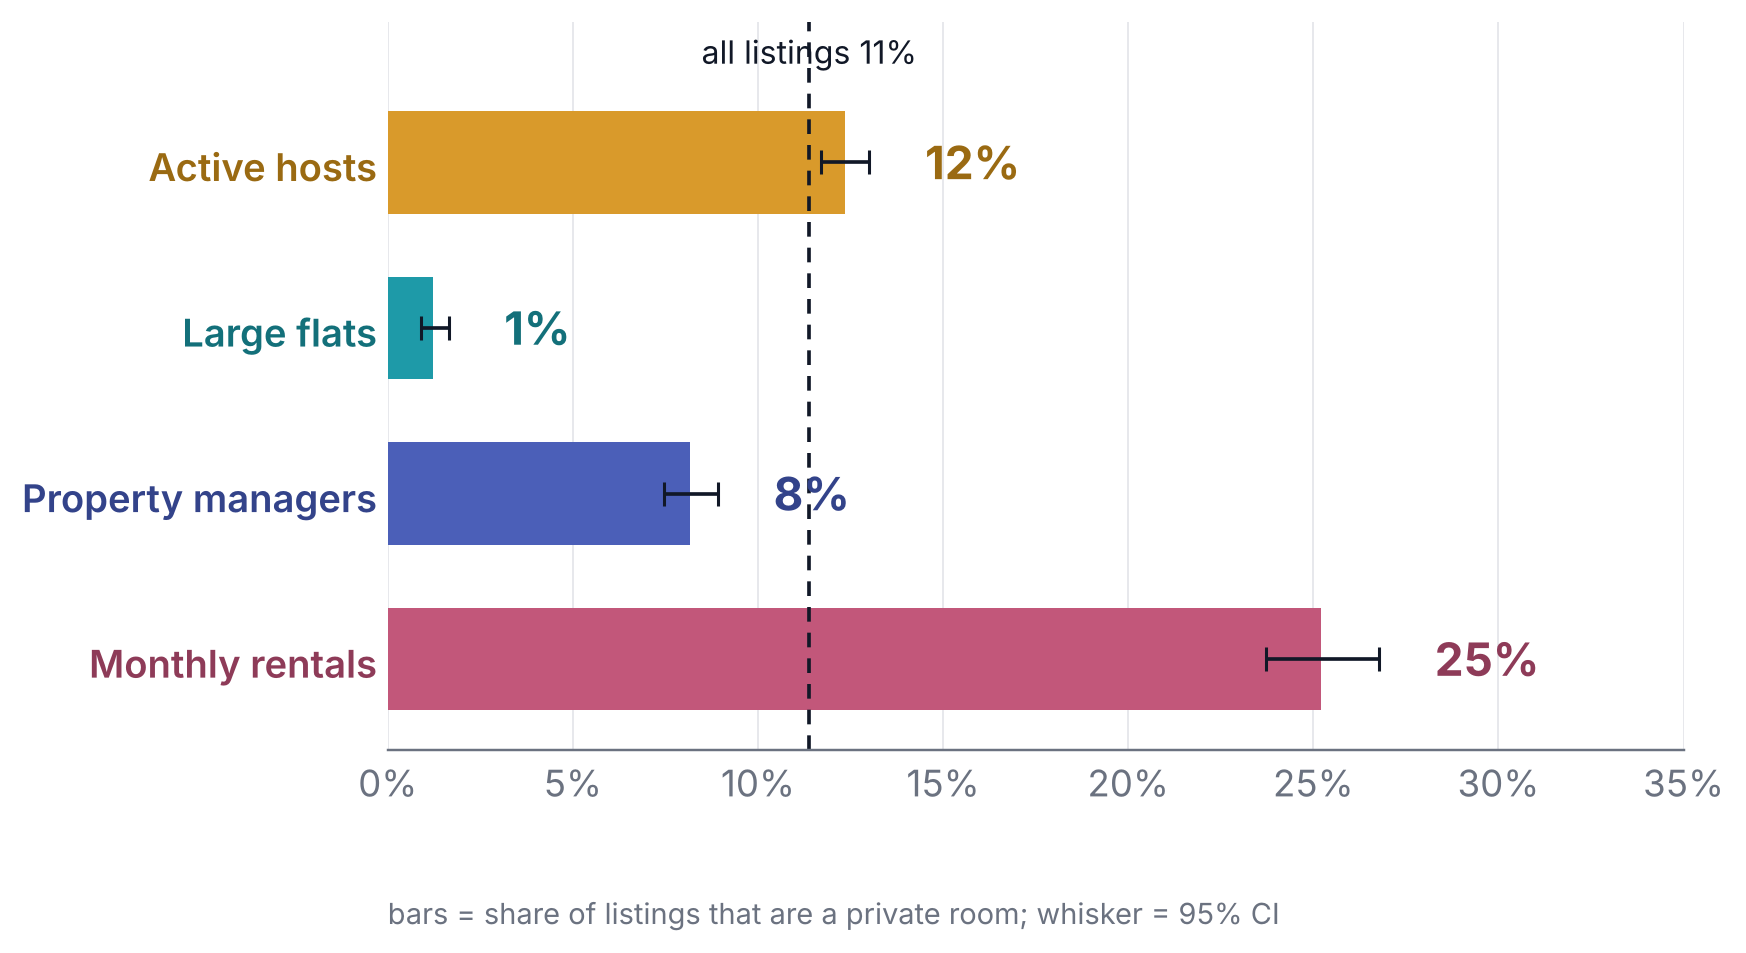

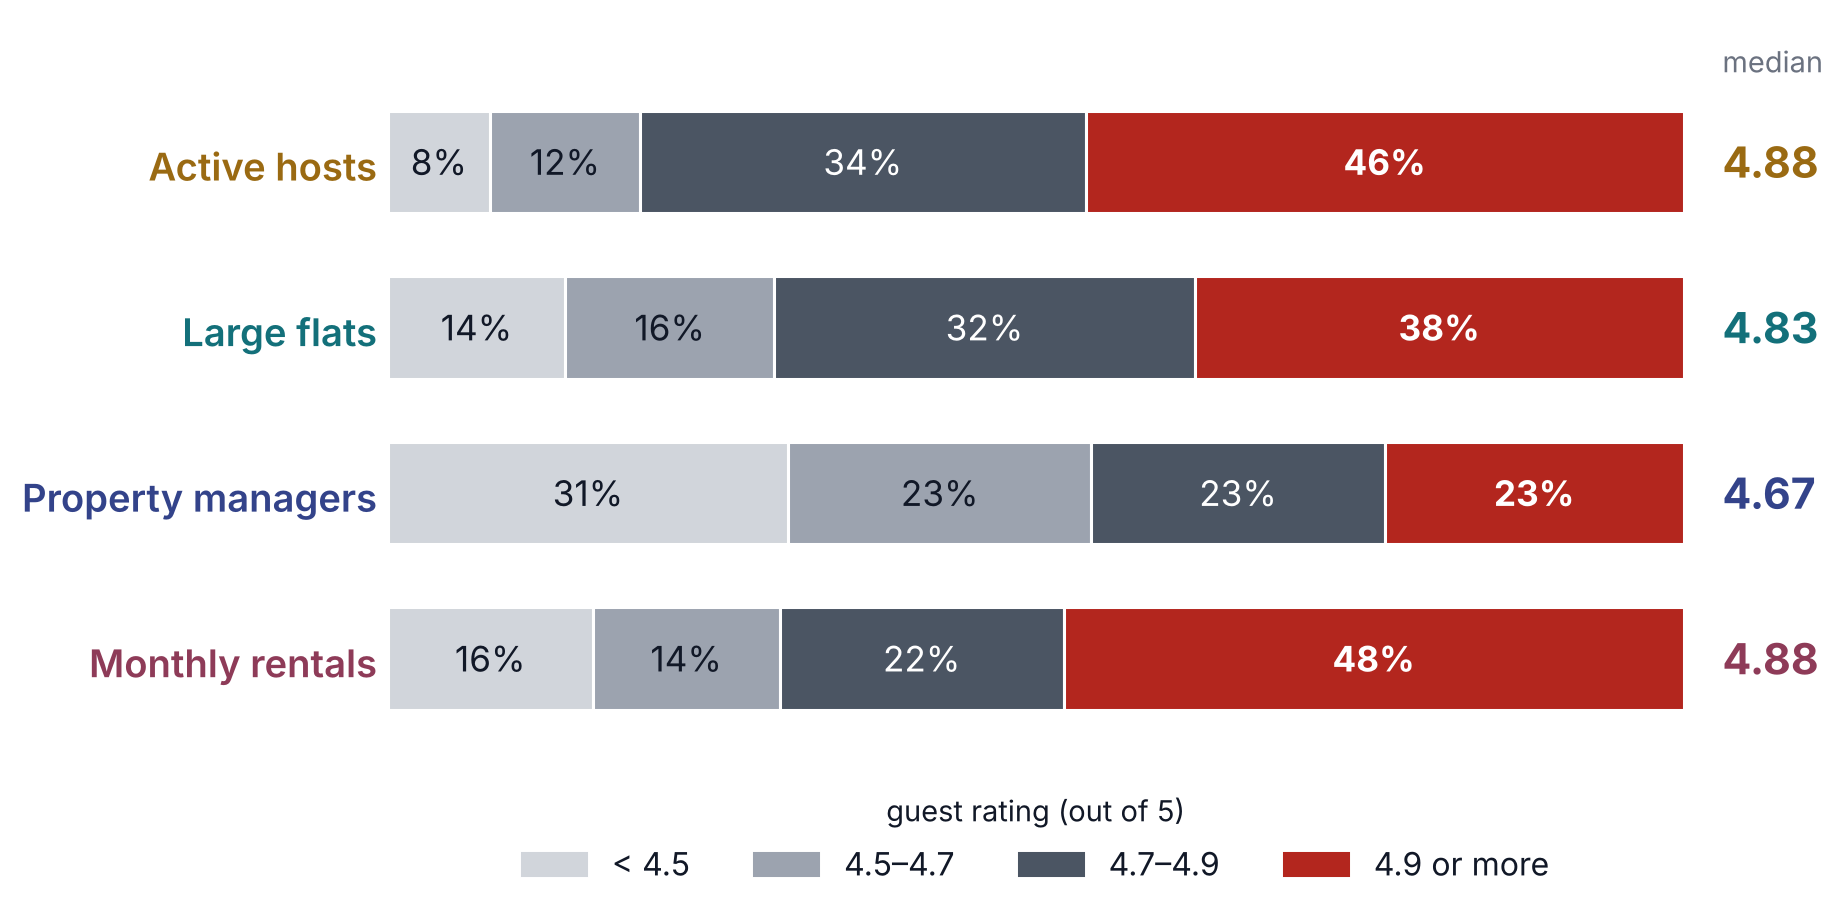

In [36]:
style('tests')
B = pd.read_csv(O + 'heldout.csv'); PR = pd.read_csv(O + 'proportions.csv'); OR = pd.read_csv(O + 'adjusted_or.csv')

def bars(var, fname, xmax=100, odds=True, note=None):
    d = PR[PR['var'] == var].set_index('cluster'); allp = B[var].mean() * 100
    fig, ax = plt.subplots(figsize=(7.6, 4.3)); y = np.arange(4)[::-1]
    ax.barh(y, d.p * 100, color=COL, height=0.62)
    ax.errorbar(d.p * 100, y, xerr=[(d.p - d.lo) * 100, (d.hi - d.p) * 100], fmt='none', ecolor=INK, elinewidth=1.2, capsize=4)
    for k in range(4):
        ax.text(d.hi[k] * 100 + 1.5, y[k], f'{d.p[k] * 100:.0f}%', va='center', fontsize=15, fontweight='bold', color=DARK[k])
    ax.axvline(allp, color=INK, lw=1.2, ls=(0, (4, 3)))
    ax.text(allp, 3.55, f'all listings {allp:.0f}%', ha='center', va='bottom', fontsize=10.5, color=INK)
    ax.set_yticks(y); ax.set_yticklabels(NAMES, fontsize=12.5)
    for t, c in zip(ax.get_yticklabels(), DARK): t.set_color(c); t.set_fontweight('semibold')
    ax.set_xlim(0, xmax); ax.set_ylim(-0.55, 3.85); ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:.0f}%'))
    ax.tick_params(length=0); ax.spines['left'].set_visible(False); ax.grid(axis='x', color=GRID, lw=0.6); ax.set_axisbelow(True)
    if odds:
        o = OR[OR.outcome == var].set_index('cluster')
        ax.text(1.04, 3.55, 'odds vs\nactive hosts*', transform=ax.get_yaxis_transform(), ha='center', va='bottom', fontsize=9.5, color=MUTED)
        for k in range(4):
            lab = 'ref.' if k == 0 else f'×{o.OR[k]:.2f}'.rstrip('0').rstrip('.')
            ns = k > 0 and o.p[k] >= 0.05
            ax.text(1.04, y[k], lab, transform=ax.get_yaxis_transform(), ha='center', va='center', fontsize=13,
                    fontweight='bold' if k else 'normal', color=MUTED if (k == 0 or ns) else INK, style='italic' if k == 0 else 'normal')
    if note: ax.text(0, -0.2, note, transform=ax.transAxes, fontsize=9.5, color=MUTED, va='top')
    save(fig, fname)

nt = '* same distance from the Duomo and room type (logistic regression, errors clustered by host)'
bars('Private room', 't_room', xmax=35, odds=False, note='bars = share of listings that are a private room; whisker = 95% CI')
# guest rating: 100% stacked bands per type
bands = [(0, 4.5, '< 4.5', '#D1D5DB'), (4.5, 4.7, '4.5–4.7', '#9CA3AF'), (4.7, 4.9, '4.7–4.9', '#4B5563'), (4.9, 5.01, '4.9 or more', RED)]
fig, ax = plt.subplots(figsize=(7.6, 4.3)); y = np.arange(4)[::-1]
for k in range(4):
    r = B.Rating[B.cluster == k].dropna(); left = 0
    for lo, hi, lab, c in bands:
        s = ((r >= lo) & (r < hi)).mean() * 100
        ax.barh(y[k], s, left=left, color=c, height=0.62, edgecolor='white', lw=1)
        if s > 7: ax.text(left + s / 2, y[k], f'{s:.0f}%', ha='center', va='center', fontsize=11.5, color='white' if c in (RED, '#4B5563') else INK, fontweight='bold' if c == RED else 'normal')
        left += s
    ax.text(103, y[k], f'{r.median():.2f}', va='center', fontsize=14, fontweight='bold', color=DARK[k])
ax.text(103, 3.5, 'median', va='bottom', fontsize=9.5, color=MUTED)
ax.set_yticks(y); ax.set_yticklabels(NAMES, fontsize=12.5)
for t, c in zip(ax.get_yticklabels(), DARK): t.set_color(c); t.set_fontweight('semibold')
ax.set_xlim(0, 100); ax.set_ylim(-0.55, 3.85); ax.set_xticks([]); ax.tick_params(length=0)
[ax.spines[s].set_visible(False) for s in ('left', 'bottom')]
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for _, _, l, c in bands], ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.02), frameon=False, fontsize=10.5, title='guest rating (out of 5)', title_fontsize=9.5)
save(fig, 't_rating')

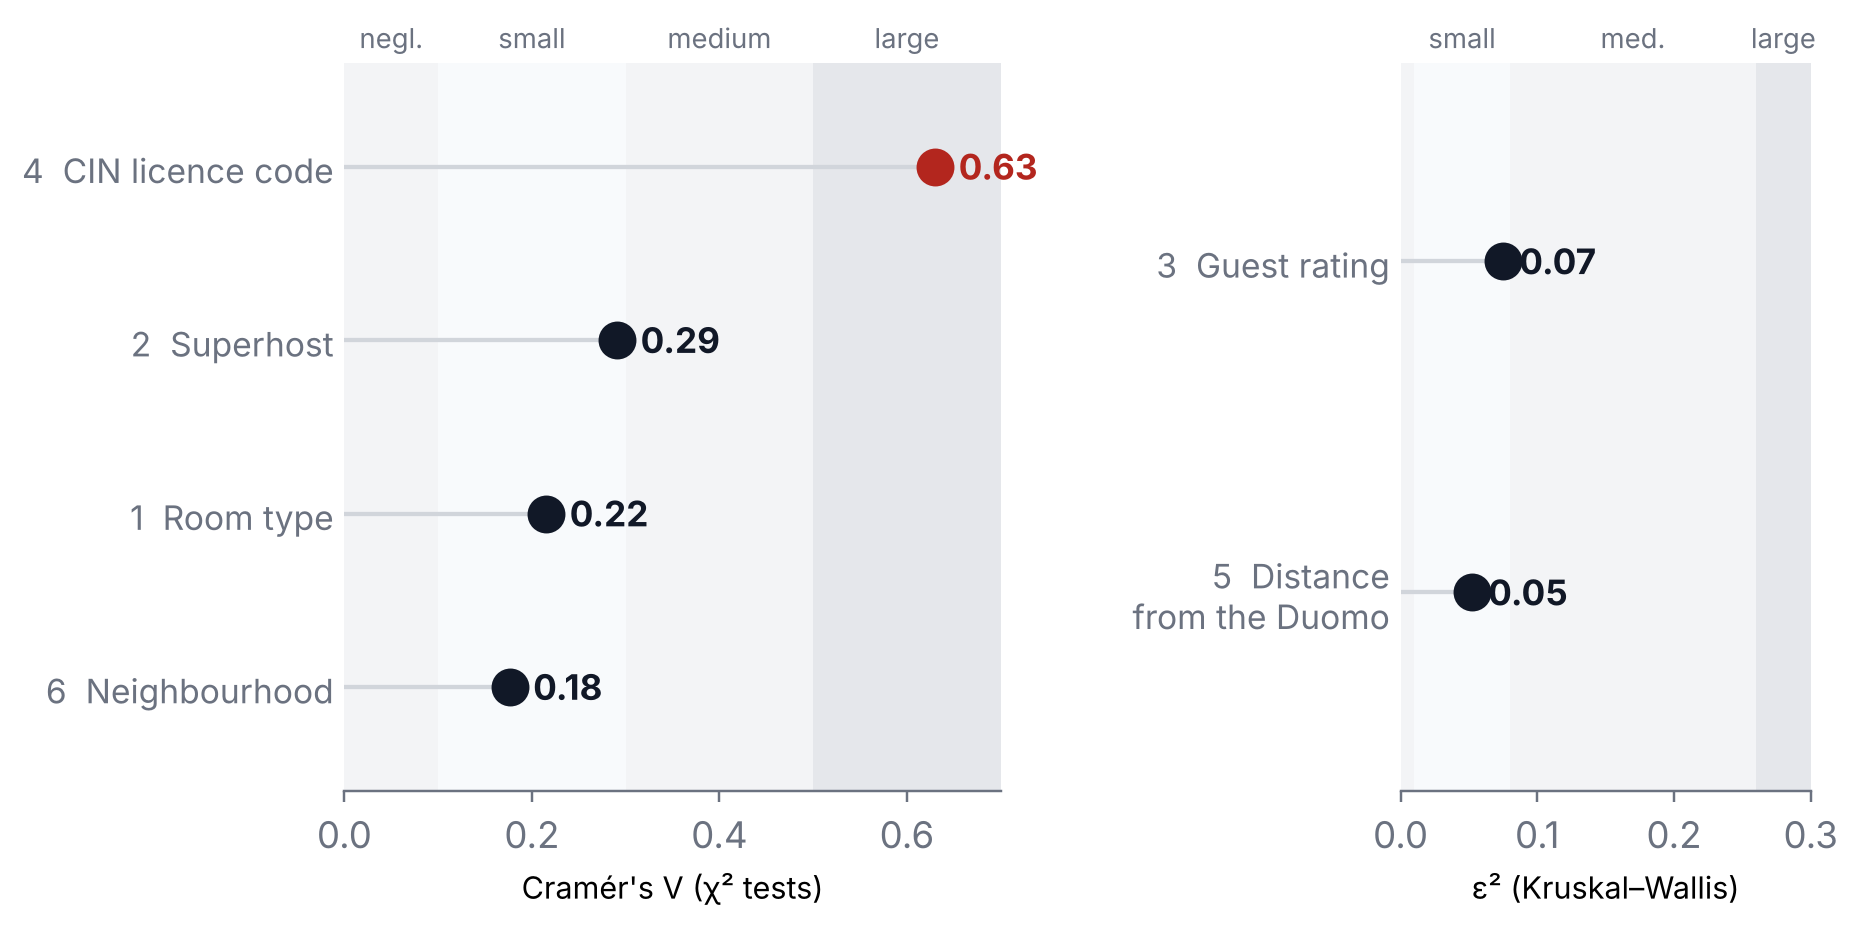

In [37]:
style('tests')
# ---- effect sizes of the six tests (numbers match the test slides)
T = pd.read_csv(O + 'tests.csv').set_index('var')
fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.6, 4.3), gridspec_kw={'width_ratios': [1.6, 1]}); fig.subplots_adjust(wspace=0.75)
def bands(a, cuts, lim, names):
    edges = [0] + cuts + [lim]; cols = ['#F3F4F6', '#F8FAFC', '#F3F4F6', '#E5E7EB']
    for i in range(4):
        a.axvspan(edges[i], edges[i + 1], color=cols[i], lw=0, zorder=0)
        a.text((edges[i] + edges[i + 1]) / 2, 1.02, names[i], transform=a.get_xaxis_transform(), ha='center', fontsize=9, color=MUTED)
def dots(a, items, lim, off):
    for i, (lab, v) in enumerate(items):
        c = RED if v > 0.5 else INK
        a.plot([0, v], [i, i], color='#D1D5DB', lw=1.4, zorder=1); a.scatter(v, i, s=130, color=c, zorder=3)
        a.text(v + off, i, f'{v:.2f}', va='center', fontsize=11.5, fontweight='bold', color=c)
    a.set_yticks(range(len(items))); a.set_yticklabels([l for l, _ in items], fontsize=11); a.set_xlim(0, lim); a.set_ylim(-0.6, len(items) - 0.4)
    a.tick_params(axis='y', length=0); a.spines['left'].set_visible(False)
left = [('6  Neighbourhood', T.effect['Neighbourhood']), ('1  Room type', T.effect['Private room']), ('2  Superhost', T.effect['Superhost']), ('4  CIN licence code', T.effect['CIN licence shown'])]
bands(a1, [0.1, 0.3, 0.5], 0.7, ['negl.', 'small', 'medium', 'large']); dots(a1, left, 0.7, 0.025); a1.set_xlabel("Cramér's V (χ² tests)", fontsize=10)
right = [('5  Distance\n    from the Duomo', T.effect['Dist']), ('3  Guest rating', T.effect['Rating'])]
bands(a2, [0.01, 0.08, 0.26], 0.3, ['', 'small', 'med.', 'large']); dots(a2, right, 0.3, 0.012); a2.set_xlabel('ε² (Kruskal–Wallis)', fontsize=10)
save(fig, 't_effects')

---
**Check.** `figures/` now holds 22 charts named `slideNN_*.png`; they are the images used in the presentation.